In [1]:
# Cell 1 — Imports, Setup, and Output Directory

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import time
import os
from dataclasses import dataclass, field
from typing import List, Tuple, Optional, Dict
from enum import Enum

# Plotting config
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
plt.style.use('seaborn-v0_8-whitegrid')

# Output directory for emulation results
OUTPUT_DIR = "ResultImages_emulationPhase"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ============================================================================
# Target Hardware Specs (from spec sheets, used for scaling)
# ============================================================================

# GPU: Jetson Nano class
TARGET_GPU_GFLOPS = 472.0          # Peak FP32 GFLOPS
TARGET_GPU_BW_GBPS = 25.6          # Memory bandwidth GB/s
TARGET_GPU_POWER_W = 15.0          # Power consumption watts

# FPGA: Zynq 7020 class
TARGET_FPGA_GFLOPS = 6.5           # Peak FP32 GFLOPS
TARGET_FPGA_INT8_GOPS = 26.0       # Peak INT8 GOPS
TARGET_FPGA_BW_GBPS = 4.2          # Memory bandwidth GB/s
TARGET_FPGA_POWER_W = 5.0          # Power consumption watts

# Communication: PCIe Gen3 x4
TARGET_XFER_BW_GBPS = 4.0          # Effective transfer bandwidth GB/s
TARGET_XFER_SETUP_US = 50.0        # DMA setup latency microseconds

# ============================================================================
# Emulation Configuration
# ============================================================================

# Unit overhead: 1 unit = 1 multiply-accumulate (MAC) operation
# All emulated times will be in "units" first, then scaled to real time

# FPGA processes 1 stream at a time — sequential pipeline
FPGA_STREAMS = 1

# GPU processes N operations in parallel per cycle
# Ratio based on spec sheet: 472 GFLOPS / 6.5 GFLOPS ≈ 72.6x
GPU_PARALLELISM = int(TARGET_GPU_GFLOPS / TARGET_FPGA_GFLOPS)

# Device for local computation
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Emulation Environment Ready")
print(f"  PyTorch: {torch.__version__}")
print(f"  Compute device: {DEVICE}")
if torch.cuda.is_available():
    print(f"  GPU: {torch.cuda.get_device_name(0)}")
    print(f"  GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
print(f"  Output directory: {OUTPUT_DIR}/")
print(f"\nEmulation Parameters:")
print(f"  FPGA streams (sequential): {FPGA_STREAMS}")
print(f"  GPU parallelism factor: {GPU_PARALLELISM}x")
print(f"  Target GPU: Jetson Nano class ({TARGET_GPU_GFLOPS} GFLOPS)")
print(f"  Target FPGA: Zynq 7020 class ({TARGET_FPGA_GFLOPS} GFLOPS)")

Emulation Environment Ready
  PyTorch: 2.6.0+cu124
  Compute device: cuda
  GPU: NVIDIA GeForce RTX 4070 Laptop GPU
  GPU Memory: 8.6 GB
  Output directory: ResultImages_emulationPhase/

Emulation Parameters:
  FPGA streams (sequential): 1
  GPU parallelism factor: 72x
  Target GPU: Jetson Nano class (472.0 GFLOPS)
  Target FPGA: Zynq 7020 class (6.5 GFLOPS)


In [2]:
# Cell 2 — Layer Definitions and Architecture Builders

class LayerType(Enum):
    CONV = "conv"
    DEPTHWISE_CONV = "depthwise_conv"
    POINTWISE_CONV = "pointwise_conv"
    BATCHNORM = "batchnorm"
    RELU = "relu"
    POOL = "pool"
    FC = "fc"

@dataclass
class Layer:
    name: str
    layer_type: LayerType
    in_channels: int
    in_height: int
    in_width: int
    out_channels: int
    out_height: int
    out_width: int
    kernel_size: int = 1
    stride: int = 1
    groups: int = 1
    
    @property
    def mac_ops(self) -> int:
        """Count of multiply-accumulate operations (1 MAC = 1 multiply + 1 add).
        This is our fundamental unit of work for emulation."""
        if self.layer_type == LayerType.CONV:
            return (self.kernel_size ** 2) * self.in_channels * self.out_channels * self.out_height * self.out_width
        elif self.layer_type == LayerType.DEPTHWISE_CONV:
            return (self.kernel_size ** 2) * self.in_channels * self.out_height * self.out_width
        elif self.layer_type == LayerType.POINTWISE_CONV:
            return self.in_channels * self.out_channels * self.out_height * self.out_width
        elif self.layer_type == LayerType.BATCHNORM:
            return 2 * self.out_channels * self.out_height * self.out_width
        elif self.layer_type == LayerType.RELU:
            return self.out_channels * self.out_height * self.out_width
        elif self.layer_type == LayerType.POOL:
            return (self.kernel_size ** 2) * self.out_channels * self.out_height * self.out_width
        elif self.layer_type == LayerType.FC:
            return self.in_channels * self.out_channels
        return 0
    
    @property
    def param_count(self) -> int:
        if self.layer_type == LayerType.CONV:
            return self.kernel_size ** 2 * self.in_channels * self.out_channels
        elif self.layer_type == LayerType.DEPTHWISE_CONV:
            return self.kernel_size ** 2 * self.in_channels
        elif self.layer_type == LayerType.POINTWISE_CONV:
            return self.in_channels * self.out_channels
        elif self.layer_type == LayerType.BATCHNORM:
            return 2 * self.out_channels
        elif self.layer_type == LayerType.FC:
            return self.in_channels * self.out_channels
        return 0
    
    @property
    def output_tensor_size_bytes(self) -> int:
        return 4 * self.out_channels * self.out_height * self.out_width
    
    @property
    def input_tensor_size_bytes(self) -> int:
        return 4 * self.in_channels * self.in_height * self.in_width
    
    @property
    def memory_bytes_accessed(self) -> int:
        """Total bytes read + written for this layer."""
        return self.input_tensor_size_bytes + self.output_tensor_size_bytes + self.param_count * 4
    
    @property
    def arithmetic_intensity(self) -> float:
        """MACs per byte accessed — determines compute vs memory bound."""
        mem = self.memory_bytes_accessed
        return self.mac_ops / mem if mem > 0 else 0

    def __repr__(self):
        return (f"{self.name:25s} | {self.layer_type.value:15s} | "
                f"MACs: {self.mac_ops:>12,} | AI: {self.arithmetic_intensity:>6.1f}")


# ============================================================================
# Architecture Builders (from trial1)
# ============================================================================

def build_resnet18() -> List[Layer]:
    layers = []
    layers.append(Layer("conv1", LayerType.CONV, 3, 224, 224, 64, 112, 112, kernel_size=7, stride=2))
    layers.append(Layer("bn1", LayerType.BATCHNORM, 64, 112, 112, 64, 112, 112))
    layers.append(Layer("relu1", LayerType.RELU, 64, 112, 112, 64, 112, 112))
    layers.append(Layer("maxpool", LayerType.POOL, 64, 112, 112, 64, 56, 56, kernel_size=3, stride=2))
    
    for g, (c, h) in enumerate([(64, 56), (128, 28), (256, 14), (512, 7)], 1):
        for b in range(2):
            in_c = (c // 2) if (b == 0 and g > 1) else c
            h_in = (h * 2) if (b == 0 and g > 1) else h
            s = 2 if (b == 0 and g > 1) else 1
            prefix = f"layer{g}_b{b}"
            layers.append(Layer(f"{prefix}_conv1", LayerType.CONV, in_c, h_in, h_in, c, h, h, kernel_size=3, stride=s))
            layers.append(Layer(f"{prefix}_bn1", LayerType.BATCHNORM, c, h, h, c, h, h))
            layers.append(Layer(f"{prefix}_relu1", LayerType.RELU, c, h, h, c, h, h))
            layers.append(Layer(f"{prefix}_conv2", LayerType.CONV, c, h, h, c, h, h, kernel_size=3))
            layers.append(Layer(f"{prefix}_bn2", LayerType.BATCHNORM, c, h, h, c, h, h))
            layers.append(Layer(f"{prefix}_relu2", LayerType.RELU, c, h, h, c, h, h))
    
    layers.append(Layer("avgpool", LayerType.POOL, 512, 7, 7, 512, 1, 1, kernel_size=7))
    layers.append(Layer("fc", LayerType.FC, 512, 1, 1, 1000, 1, 1))
    return layers


def build_mobilenetv2() -> List[Layer]:
    layers = []
    layers.append(Layer("conv_stem", LayerType.CONV, 3, 224, 224, 32, 112, 112, kernel_size=3, stride=2))
    layers.append(Layer("bn_stem", LayerType.BATCHNORM, 32, 112, 112, 32, 112, 112))
    layers.append(Layer("relu_stem", LayerType.RELU, 32, 112, 112, 32, 112, 112))
    
    block_configs = [
        (32, 32, 16, 112, 56, 2), (16, 96, 24, 56, 28, 2),
        (24, 144, 24, 28, 28, 1), (24, 144, 32, 28, 14, 2),
        (32, 192, 32, 14, 14, 1), (32, 192, 32, 14, 14, 1),
        (32, 192, 64, 14, 7, 2), (64, 384, 64, 7, 7, 1),
        (64, 384, 64, 7, 7, 1), (64, 384, 96, 7, 7, 1),
        (96, 576, 96, 7, 7, 1), (96, 576, 96, 7, 7, 1),
        (96, 576, 160, 7, 4, 2), (160, 960, 160, 4, 4, 1),
        (160, 960, 160, 4, 4, 1), (160, 960, 320, 4, 4, 1),
    ]
    
    for idx, (in_c, exp_c, out_c, h_in, h_out, stride) in enumerate(block_configs):
        prefix = f"block{idx+1}"
        if exp_c != in_c:
            layers.append(Layer(f"{prefix}_expand", LayerType.POINTWISE_CONV, in_c, h_in, h_in, exp_c, h_in, h_in))
            layers.append(Layer(f"{prefix}_expand_bn", LayerType.BATCHNORM, exp_c, h_in, h_in, exp_c, h_in, h_in))
            layers.append(Layer(f"{prefix}_expand_relu", LayerType.RELU, exp_c, h_in, h_in, exp_c, h_in, h_in))
        layers.append(Layer(f"{prefix}_dw", LayerType.DEPTHWISE_CONV, exp_c, h_in, h_in, exp_c, h_out, h_out, kernel_size=3, stride=stride))
        layers.append(Layer(f"{prefix}_dw_bn", LayerType.BATCHNORM, exp_c, h_out, h_out, exp_c, h_out, h_out))
        layers.append(Layer(f"{prefix}_dw_relu", LayerType.RELU, exp_c, h_out, h_out, exp_c, h_out, h_out))
        layers.append(Layer(f"{prefix}_project", LayerType.POINTWISE_CONV, exp_c, h_out, h_out, out_c, h_out, h_out))
        layers.append(Layer(f"{prefix}_project_bn", LayerType.BATCHNORM, out_c, h_out, h_out, out_c, h_out, h_out))
    
    layers.append(Layer("conv_final", LayerType.POINTWISE_CONV, 320, 4, 4, 1280, 4, 4))
    layers.append(Layer("bn_final", LayerType.BATCHNORM, 1280, 4, 4, 1280, 4, 4))
    layers.append(Layer("relu_final", LayerType.RELU, 1280, 4, 4, 1280, 4, 4))
    layers.append(Layer("avgpool", LayerType.POOL, 1280, 4, 4, 1280, 1, 1, kernel_size=4))
    layers.append(Layer("fc", LayerType.FC, 1280, 1, 1, 1000, 1, 1))
    return layers


# ============================================================================
# Summarize architectures with emulation-relevant metrics
# ============================================================================

for arch_name, builder in [("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2)]:
    layers = builder()
    total_macs = sum(l.mac_ops for l in layers)
    total_params = sum(l.param_count for l in layers)
    total_mem = sum(l.memory_bytes_accessed for l in layers)
    
    print(f"\n{'='*80}")
    print(f"{arch_name}: {len(layers)} layers")
    print(f"  Total MACs:     {total_macs:>15,} ({total_macs/1e9:.2f} GMACs)")
    print(f"  Total Params:   {total_params:>15,} ({total_params/1e6:.2f}M)")
    print(f"  Total Memory:   {total_mem:>15,} bytes ({total_mem/1e6:.1f} MB)")
    print(f"  Avg Arith Int:  {total_macs/total_mem:.1f} MACs/byte")
    print(f"{'='*80}")
    
    # Show per-layer breakdown
    print(f"{'Layer':<28} {'Type':<17} {'MACs':>14} {'Arith Intensity':>16}")
    print(f"{'-'*78}")
    for l in layers:
        print(f"{l.name:<28} {l.layer_type.value:<17} {l.mac_ops:>14,} {l.arithmetic_intensity:>14.1f}")


ResNet-18: 54 layers
  Total MACs:       1,803,561,472 (1.80 GMACs)
  Total Params:        11,514,688 (11.51M)
  Total Memory:       103,668,896 bytes (103.7 MB)
  Avg Arith Int:  17.4 MACs/byte
Layer                        Type                        MACs  Arith Intensity
------------------------------------------------------------------------------
conv1                        conv                 118,013,952           30.6
bn1                          batchnorm              1,605,632            0.2
relu1                        relu                     802,816            0.1
maxpool                      pool                   1,806,336            0.5
layer1_b0_conv1              conv                 115,605,504           65.9
layer1_b0_bn1                batchnorm                401,408            0.2
layer1_b0_relu1              relu                     200,704            0.1
layer1_b0_conv2              conv                 115,605,504           65.9
layer1_b0_bn2                b

In [3]:
# Cell 3 — FPGA Emulator: Sequential Streaming Processor

# ============================================================================
# The FPGA processes operations sequentially in a streaming fashion.
# It excels when arithmetic intensity is low (memory-bound ops) because
# its custom datapath reads data once and processes it in a single pass
# with no wasted cycles. For compute-heavy ops, it's slow because it
# has limited parallel multiply-accumulate units.
#
# Cost model:
#   - Compute cost = MAC ops (processed sequentially, 1 stream)
#   - Memory cost  = bytes accessed (streamed through, limited bandwidth)
#   - Actual cost  = max(compute_cost, memory_cost) — roofline
#   - Fusion bonus = fused ops skip intermediate memory reads/writes
# ============================================================================

@dataclass
class FPGAEmulatorResult:
    """Result of emulating a layer or fused block on the FPGA."""
    name: str
    mac_ops: int                    # Total MACs executed
    memory_bytes: int               # Total bytes accessed
    compute_units: float            # Cost in compute units
    memory_units: float             # Cost in memory units
    effective_units: float          # max(compute, memory) — actual cost
    is_fused: bool = False
    fusion_memory_saved: int = 0    # Bytes saved by fusion


class FPGAEmulator:
    """Emulates FPGA execution as a sequential streaming processor.
    
    The FPGA has:
    - 1 streaming pipeline (processes one operation flow at a time)
    - High efficiency on streaming ops (depthwise, batchnorm, relu)
    - Custom datapath that processes data in a single pass
    - Limited DSP slices for parallel MACs
    
    The cost is measured in abstract "units" where:
    - 1 compute unit = 1 MAC on the FPGA
    - 1 memory unit = bandwidth-equivalent cost of accessing 1 byte
    """
    
    def __init__(self, 
                 dsp_slices: int = 220,          # Zynq 7020 has 220 DSP slices
                 mem_bandwidth_ratio: float = 1.0, # Relative memory bandwidth
                 streaming_efficiency: Dict[LayerType, float] = None):
        """
        Args:
            dsp_slices: Number of parallel MAC units available
            mem_bandwidth_ratio: Relative memory bandwidth (1.0 = baseline)
            streaming_efficiency: How well each layer type maps to streaming
                                  1.0 = perfect streaming, 0.0 = no benefit
        """
        self.dsp_slices = dsp_slices
        self.mem_bandwidth_ratio = mem_bandwidth_ratio
        
        # Streaming efficiency: how well the FPGA's datapath handles each op
        # High = data flows through in one pass, no stalls
        # Low = irregular access patterns, pipeline bubbles
        self.streaming_efficiency = streaming_efficiency or {
            LayerType.CONV:           0.45,   # Limited by DSP count for large convs
            LayerType.DEPTHWISE_CONV: 0.85,   # Excellent — perfect streaming pattern
            LayerType.POINTWISE_CONV: 0.65,   # Good — simple MAC chains
            LayerType.BATCHNORM:      0.90,   # Excellent — fused into pipeline
            LayerType.RELU:           0.95,   # Near-free — single comparator
            LayerType.POOL:           0.90,   # Excellent — simple comparator tree
            LayerType.FC:             0.30,   # Poor — large weight matrices
        }
    
    def emulate_layer(self, layer: Layer) -> FPGAEmulatorResult:
        """Emulate execution of a single layer on the FPGA.
        
        Returns cost in abstract units based on the roofline model:
        cost = max(compute_cost, memory_cost)
        
        Compute cost is reduced by streaming efficiency (better streaming
        = fewer pipeline stalls = lower effective compute cost).
        """
        eff = self.streaming_efficiency[layer.layer_type]
        
        # Compute cost: MACs / effective parallelism
        # The FPGA can do (dsp_slices * efficiency) MACs per cycle
        effective_parallelism = self.dsp_slices * eff
        compute_units = layer.mac_ops / effective_parallelism
        
        # Memory cost: bytes / bandwidth
        # Streaming ops access memory linearly — high bandwidth utilization
        # Non-streaming ops have irregular access — lower effective bandwidth
        effective_bw = self.mem_bandwidth_ratio * eff
        memory_units = layer.memory_bytes_accessed / max(effective_bw, 0.01)
        
        # Roofline: actual cost is the bottleneck
        effective_units = max(compute_units, memory_units)
        
        return FPGAEmulatorResult(
            name=layer.name,
            mac_ops=layer.mac_ops,
            memory_bytes=layer.memory_bytes_accessed,
            compute_units=compute_units,
            memory_units=memory_units,
            effective_units=effective_units
        )
    
    def emulate_fused_block(self, layers: List[Layer], 
                             pattern_name: str = "") -> FPGAEmulatorResult:
        """Emulate execution of a fused block on the FPGA.
        
        Fusion benefit: intermediate tensors are kept in on-chip BRAM
        instead of being written to and read from external memory.
        This eliminates the memory cost of intermediate activations.
        """
        total_mac_ops = 0
        total_memory = 0
        total_compute_units = 0
        fusion_memory_saved = 0
        
        for i, layer in enumerate(layers):
            result = self.emulate_layer(layer)
            total_mac_ops += layer.mac_ops
            total_compute_units += result.compute_units
            
            if i == 0:
                # First layer: read input from external memory
                total_memory += layer.input_tensor_size_bytes
                total_memory += layer.param_count * 4
            elif i == len(layers) - 1:
                # Last layer: write output to external memory
                total_memory += layer.param_count * 4
                total_memory += layer.output_tensor_size_bytes
            else:
                # Middle layers: only load params, activations stay on-chip
                total_memory += layer.param_count * 4
            
            # Track memory saved by not writing/reading intermediate tensors
            if i < len(layers) - 1:
                saved = layer.output_tensor_size_bytes * 2  # Write + read
                fusion_memory_saved += saved
        
        # Memory cost with fusion benefit
        avg_eff = np.mean([self.streaming_efficiency[l.layer_type] for l in layers])
        effective_bw = self.mem_bandwidth_ratio * avg_eff
        memory_units = total_memory / max(effective_bw, 0.01)
        
        effective_units = max(total_compute_units, memory_units)
        
        return FPGAEmulatorResult(
            name=f"fused_{pattern_name}",
            mac_ops=total_mac_ops,
            memory_bytes=total_memory,
            compute_units=total_compute_units,
            memory_units=memory_units,
            effective_units=effective_units,
            is_fused=True,
            fusion_memory_saved=fusion_memory_saved
        )
    
    def emulate_int8(self, result: FPGAEmulatorResult, 
                      speedup: float = 2.5) -> FPGAEmulatorResult:
        """Apply INT8 quantization speedup to an FPGA result.
        
        INT8 allows the FPGA to:
        - Pack more operations per DSP slice (compute speedup)
        - Transfer smaller tensors (memory/transfer speedup)
        """
        return FPGAEmulatorResult(
            name=result.name + "_int8",
            mac_ops=result.mac_ops,
            memory_bytes=int(result.memory_bytes * 0.25),  # INT8 = 1/4 of FP32
            compute_units=result.compute_units / speedup,
            memory_units=result.memory_units / speedup,
            effective_units=result.effective_units / speedup,
            is_fused=result.is_fused,
            fusion_memory_saved=result.fusion_memory_saved
        )


# ============================================================================
# Test the FPGA emulator on both architectures
# ============================================================================

fpga_emu = FPGAEmulator()

for arch_name, builder in [("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2)]:
    layers = builder()
    
    print(f"\n{'='*95}")
    print(f"{arch_name} — FPGA Emulation (per-layer)")
    print(f"{'='*95}")
    print(f"{'Layer':<28} {'MACs':>12} {'Compute U':>12} {'Memory U':>12} {'Effective U':>12} {'Bound':>8}")
    print(f"{'-'*88}")
    
    total_compute = 0
    total_memory = 0
    total_effective = 0
    compute_bound_count = 0
    memory_bound_count = 0
    
    for layer in layers:
        result = fpga_emu.emulate_layer(layer)
        total_compute += result.compute_units
        total_memory += result.memory_units
        total_effective += result.effective_units
        
        bound = "COMPUTE" if result.compute_units >= result.memory_units else "MEMORY"
        if bound == "COMPUTE":
            compute_bound_count += 1
        else:
            memory_bound_count += 1
        
        print(f"{layer.name:<28} {result.mac_ops:>12,} {result.compute_units:>12.1f} "
              f"{result.memory_units:>12.1f} {result.effective_units:>12.1f} {bound:>8}")
    
    print(f"{'-'*88}")
    print(f"{'TOTAL':<28} {'':>12} {total_compute:>12.1f} {total_memory:>12.1f} {total_effective:>12.1f}")
    print(f"\nCompute-bound layers: {compute_bound_count}/{len(layers)}")
    print(f"Memory-bound layers:  {memory_bound_count}/{len(layers)}")
    print(f"Compute/Memory ratio: {total_compute/total_memory:.2f}")


ResNet-18 — FPGA Emulation (per-layer)
Layer                                MACs    Compute U     Memory U  Effective U    Bound
----------------------------------------------------------------------------------------
conv1                         118,013,952    1192060.1    8557795.6    8557795.6   MEMORY
bn1                             1,605,632       8109.3    7136711.1    7136711.1   MEMORY
relu1                             802,816       3841.2    6760555.8    6760555.8   MEMORY
maxpool                         1,806,336       9122.9    4460088.9    4460088.9   MEMORY
layer1_b0_conv1               115,605,504    1167732.4    3895751.1    3895751.1   MEMORY
layer1_b0_bn1                     401,408       2027.3    1784604.4    1784604.4   MEMORY
layer1_b0_relu1                   200,704        960.3    1690138.9    1690138.9   MEMORY
layer1_b0_conv2               115,605,504    1167732.4    3895751.1    3895751.1   MEMORY
layer1_b0_bn2                     401,408       2027.3    178


ResNet-18 — GPU Emulation (per-layer)
Layer                                MACs    Compute U     Memory U  Effective U    Bound
----------------------------------------------------------------------------------------
conv1                         118,013,952    1418436.9     971250.4    1418436.9  COMPUTE
bn1                             1,605,632      83626.7    7019715.8    7019715.8   MEMORY
relu1                             802,816      62720.0   10528734.4   10528734.4   MEMORY
maxpool                         1,806,336     117600.0    5483715.8    5483715.8   MEMORY
layer1_b0_conv1               115,605,504    1389489.2     442140.7    1389489.2  COMPUTE
layer1_b0_bn1                     401,408      20906.7    1755348.6    1755348.6   MEMORY
layer1_b0_relu1                   200,704      15680.0    2632183.6    2632183.6   MEMORY
layer1_b0_conv2               115,605,504    1389489.2     442140.7    1389489.2  COMPUTE
layer1_b0_bn2                     401,408      20906.7    1755

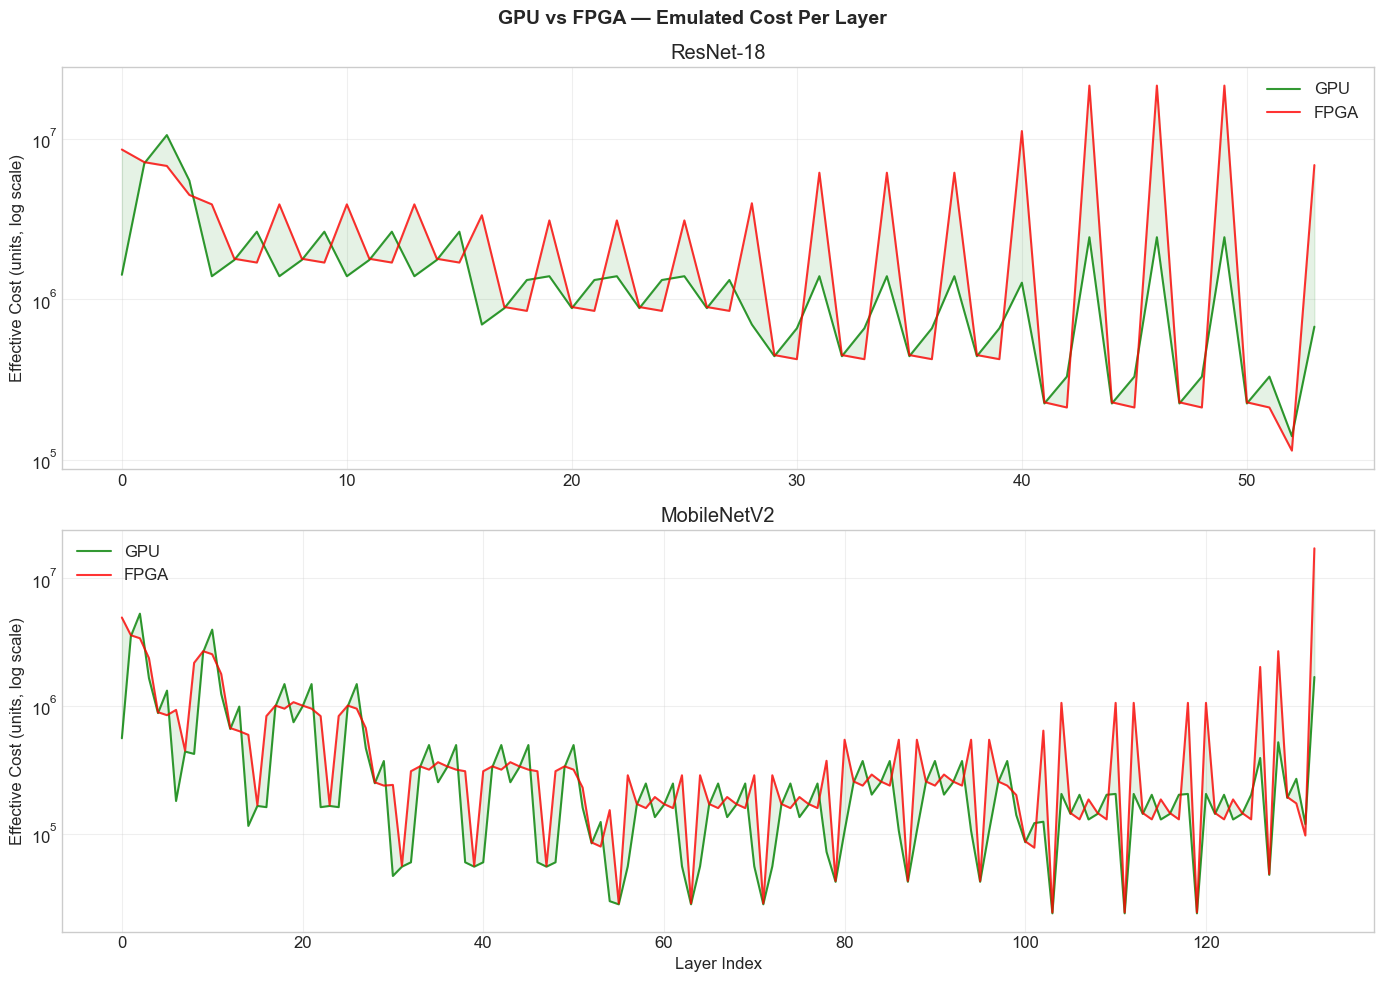

In [4]:
# Cell 4 — GPU Emulator: Parallel Batch Processor

# ============================================================================
# The GPU processes operations in massive parallel batches.
# It excels when arithmetic intensity is high (compute-bound ops) because
# thousands of CUDA cores can all work simultaneously on independent MACs.
# For memory-bound ops, most cores sit idle waiting for data.
#
# Cost model:
#   - Compute cost = MAC ops / (parallel_cores * efficiency)
#   - Memory cost  = bytes accessed / memory_bandwidth
#   - Actual cost  = max(compute_cost, memory_cost) — roofline
#   - GPU has much higher parallelism than FPGA but fixed architecture
# ============================================================================

@dataclass
class GPUEmulatorResult:
    """Result of emulating a layer or fused block on the GPU."""
    name: str
    mac_ops: int
    memory_bytes: int
    compute_units: float
    memory_units: float
    effective_units: float
    is_fused: bool = False
    fusion_memory_saved: int = 0


class GPUEmulator:
    """Emulates GPU execution as a parallel batch processor.
    
    The GPU has:
    - Thousands of CUDA cores processing in parallel
    - High memory bandwidth but shared across all cores
    - Fixed architecture — can't customize datapath per operation
    - High efficiency on regular, parallel workloads
    - Poor efficiency on small, irregular, or memory-bound ops
    
    Cost measured in same abstract units as FPGA for direct comparison.
    """
    
    def __init__(self,
                 cuda_cores: int = 128,            # Jetson Nano: 128 CUDA cores
                 mem_bandwidth_ratio: float = 6.1,  # 25.6/4.2 = 6.1x FPGA bandwidth
                 parallel_efficiency: Dict[LayerType, float] = None):
        """
        Args:
            cuda_cores: Number of parallel compute units
            mem_bandwidth_ratio: Memory bandwidth relative to FPGA baseline
            parallel_efficiency: How well each op utilizes GPU parallelism
                                 1.0 = perfect utilization of all cores
                                 Low = most cores idle
        """
        self.cuda_cores = cuda_cores
        self.mem_bandwidth_ratio = mem_bandwidth_ratio
        
        # Parallel efficiency: how well the GPU's fixed architecture handles each op
        # High = regular, data-parallel, lots of independent work
        # Low = irregular, sequential dependencies, or too little work
        self.parallel_efficiency = parallel_efficiency or {
            LayerType.CONV:           0.65,   # Good — massive data parallelism
            LayerType.DEPTHWISE_CONV: 0.20,   # Poor — too few MACs per channel
            LayerType.POINTWISE_CONV: 0.55,   # Decent — parallel but memory-bound
            LayerType.BATCHNORM:      0.15,   # Poor — element-wise, memory-bound
            LayerType.RELU:           0.10,   # Poor — trivial compute, pure memory
            LayerType.POOL:           0.12,   # Poor — simple comparisons, memory-bound
            LayerType.FC:             0.50,   # Decent — matrix multiply
        }
    
    def emulate_layer(self, layer: Layer) -> GPUEmulatorResult:
        """Emulate execution of a single layer on the GPU.
        
        Same roofline model as FPGA but with much higher parallelism
        and memory bandwidth.
        """
        eff = self.parallel_efficiency[layer.layer_type]
        
        # Compute cost: MACs / (cores * efficiency)
        # Many more cores than FPGA DSPs, but efficiency varies
        effective_parallelism = self.cuda_cores * eff
        compute_units = layer.mac_ops / effective_parallelism
        
        # Memory cost: bytes / bandwidth
        # GPU has ~6x the memory bandwidth of the FPGA
        # But bandwidth utilization depends on access pattern regularity
        effective_bw = self.mem_bandwidth_ratio * eff
        memory_units = layer.memory_bytes_accessed / max(effective_bw, 0.01)
        
        # Roofline: actual cost is the bottleneck
        effective_units = max(compute_units, memory_units)
        
        return GPUEmulatorResult(
            name=layer.name,
            mac_ops=layer.mac_ops,
            memory_bytes=layer.memory_bytes_accessed,
            compute_units=compute_units,
            memory_units=memory_units,
            effective_units=effective_units
        )
    
    def emulate_fused_block(self, layers: List[Layer],
                             pattern_name: str = "") -> GPUEmulatorResult:
        """Emulate execution of a fused block on the GPU.
        
        GPU fusion (like TensorRT kernel fusion) also eliminates
        intermediate memory accesses, but the benefit is smaller
        because GPU already has high memory bandwidth.
        """
        total_mac_ops = 0
        total_memory = 0
        total_compute_units = 0
        fusion_memory_saved = 0
        
        for i, layer in enumerate(layers):
            result = self.emulate_layer(layer)
            total_mac_ops += layer.mac_ops
            total_compute_units += result.compute_units
            
            if i == 0:
                total_memory += layer.input_tensor_size_bytes
                total_memory += layer.param_count * 4
            elif i == len(layers) - 1:
                total_memory += layer.param_count * 4
                total_memory += layer.output_tensor_size_bytes
            else:
                total_memory += layer.param_count * 4
            
            if i < len(layers) - 1:
                saved = layer.output_tensor_size_bytes * 2
                fusion_memory_saved += saved
        
        avg_eff = np.mean([self.parallel_efficiency[l.layer_type] for l in layers])
        effective_bw = self.mem_bandwidth_ratio * avg_eff
        memory_units = total_memory / max(effective_bw, 0.01)
        
        effective_units = max(total_compute_units, memory_units)
        
        return GPUEmulatorResult(
            name=f"fused_{pattern_name}",
            mac_ops=total_mac_ops,
            memory_bytes=total_memory,
            compute_units=total_compute_units,
            memory_units=memory_units,
            effective_units=effective_units,
            is_fused=True,
            fusion_memory_saved=fusion_memory_saved
        )


# ============================================================================
# Test the GPU emulator on both architectures
# ============================================================================

gpu_emu = GPUEmulator()

for arch_name, builder in [("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2)]:
    layers = builder()
    
    print(f"\n{'='*95}")
    print(f"{arch_name} — GPU Emulation (per-layer)")
    print(f"{'='*95}")
    print(f"{'Layer':<28} {'MACs':>12} {'Compute U':>12} {'Memory U':>12} {'Effective U':>12} {'Bound':>8}")
    print(f"{'-'*88}")
    
    total_compute = 0
    total_memory = 0
    total_effective = 0
    compute_bound_count = 0
    memory_bound_count = 0
    
    for layer in layers:
        result = gpu_emu.emulate_layer(layer)
        total_compute += result.compute_units
        total_memory += result.memory_units
        total_effective += result.effective_units
        
        bound = "COMPUTE" if result.compute_units >= result.memory_units else "MEMORY"
        if bound == "COMPUTE":
            compute_bound_count += 1
        else:
            memory_bound_count += 1
        
        print(f"{layer.name:<28} {result.mac_ops:>12,} {result.compute_units:>12.1f} "
              f"{result.memory_units:>12.1f} {result.effective_units:>12.1f} {bound:>8}")
    
    print(f"{'-'*88}")
    print(f"{'TOTAL':<28} {'':>12} {total_compute:>12.1f} {total_memory:>12.1f} {total_effective:>12.1f}")
    print(f"\nCompute-bound layers: {compute_bound_count}/{len(layers)}")
    print(f"Memory-bound layers:  {memory_bound_count}/{len(layers)}")
    print(f"Compute/Memory ratio: {total_compute/total_memory:.2f}")


# ============================================================================
# Head-to-Head: GPU vs FPGA per-layer comparison
# ============================================================================

print(f"\n\n{'='*110}")
print(f"GPU vs FPGA — Per-Layer Cost Comparison (Effective Units)")
print(f"{'='*110}")

for arch_name, builder in [("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2)]:
    layers = builder()
    
    print(f"\n{'─'*110}")
    print(f"{arch_name}")
    print(f"{'─'*110}")
    print(f"{'Layer':<28} {'GPU Units':>14} {'FPGA Units':>14} {'Ratio (F/G)':>12} {'Faster':>8}")
    print(f"{'-'*80}")
    
    gpu_total = 0
    fpga_total = 0
    gpu_wins = 0
    fpga_wins = 0
    
    for layer in layers:
        g = gpu_emu.emulate_layer(layer)
        f = fpga_emu.emulate_layer(layer)
        
        gpu_total += g.effective_units
        fpga_total += f.effective_units
        
        ratio = f.effective_units / g.effective_units if g.effective_units > 0 else float('inf')
        faster = "GPU" if g.effective_units < f.effective_units else "FPGA"
        
        if faster == "GPU":
            gpu_wins += 1
        else:
            fpga_wins += 1
        
        print(f"{layer.name:<28} {g.effective_units:>14.1f} {f.effective_units:>14.1f} "
              f"{ratio:>11.1f}x {faster:>8}")
    
    print(f"{'-'*80}")
    print(f"{'TOTAL':<28} {gpu_total:>14.1f} {fpga_total:>14.1f} "
          f"{fpga_total/gpu_total:>11.1f}x")
    print(f"\nGPU faster: {gpu_wins}/{len(layers)} layers")
    print(f"FPGA faster: {fpga_wins}/{len(layers)} layers")
    print(f"Overall FPGA/GPU ratio: {fpga_total/gpu_total:.1f}x (FPGA is {fpga_total/gpu_total:.1f}x slower)")

# ============================================================================
# Visualization: GPU vs FPGA cost per layer
# ============================================================================

fig, axes = plt.subplots(2, 1, figsize=(14, 10))
fig.suptitle("GPU vs FPGA — Emulated Cost Per Layer", fontsize=14, fontweight='bold')

for idx, (arch_name, builder) in enumerate([("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2)]):
    layers = builder()
    gpu_costs = [gpu_emu.emulate_layer(l).effective_units for l in layers]
    fpga_costs = [fpga_emu.emulate_layer(l).effective_units for l in layers]
    
    x = range(len(layers))
    
    axes[idx].semilogy(x, gpu_costs, 'g-', linewidth=1.5, alpha=0.8, label='GPU')
    axes[idx].semilogy(x, fpga_costs, 'r-', linewidth=1.5, alpha=0.8, label='FPGA')
    axes[idx].fill_between(x, gpu_costs, fpga_costs, alpha=0.1,
                           color='green' if sum(gpu_costs) < sum(fpga_costs) else 'red')
    axes[idx].set_ylabel("Effective Cost (units, log scale)")
    axes[idx].set_title(f"{arch_name}")
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.3)
    
    if idx == 1:
        axes[idx].set_xlabel("Layer Index")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "gpu_vs_fpga_per_layer.png"), dpi=150, bbox_inches='tight')
plt.show()

Calibrating shared memory emulator...
  Local memory bandwidth: 21.90 GB/s

Transfer Cost Profiling — Measured on Local Hardware + Scaled to Target

─────────────────────────────────────────────────────────────────────────────────────────────────────────
ResNet-18 — Transfer at each layer boundary
─────────────────────────────────────────────────────────────────────────────────────────────────────────
Split After                   Tensor (KB)   Local (ms)    PCIe (ms)  Unified (ms)    INT8 PCIe
--------------------------------------------------------------------------------------------
conv1                            3136.0     0.0797     0.8528      0.1304     0.2507
bn1                              3136.0     0.0816     0.8528      0.1304     0.2507
relu1                            3136.0     0.0725     0.8528      0.1304     0.2507
layer1_b0_bn1                     784.0     0.0205     0.2507      0.0364     0.1002
layer1_b1_conv1                   784.0     0.0197     0.2507      

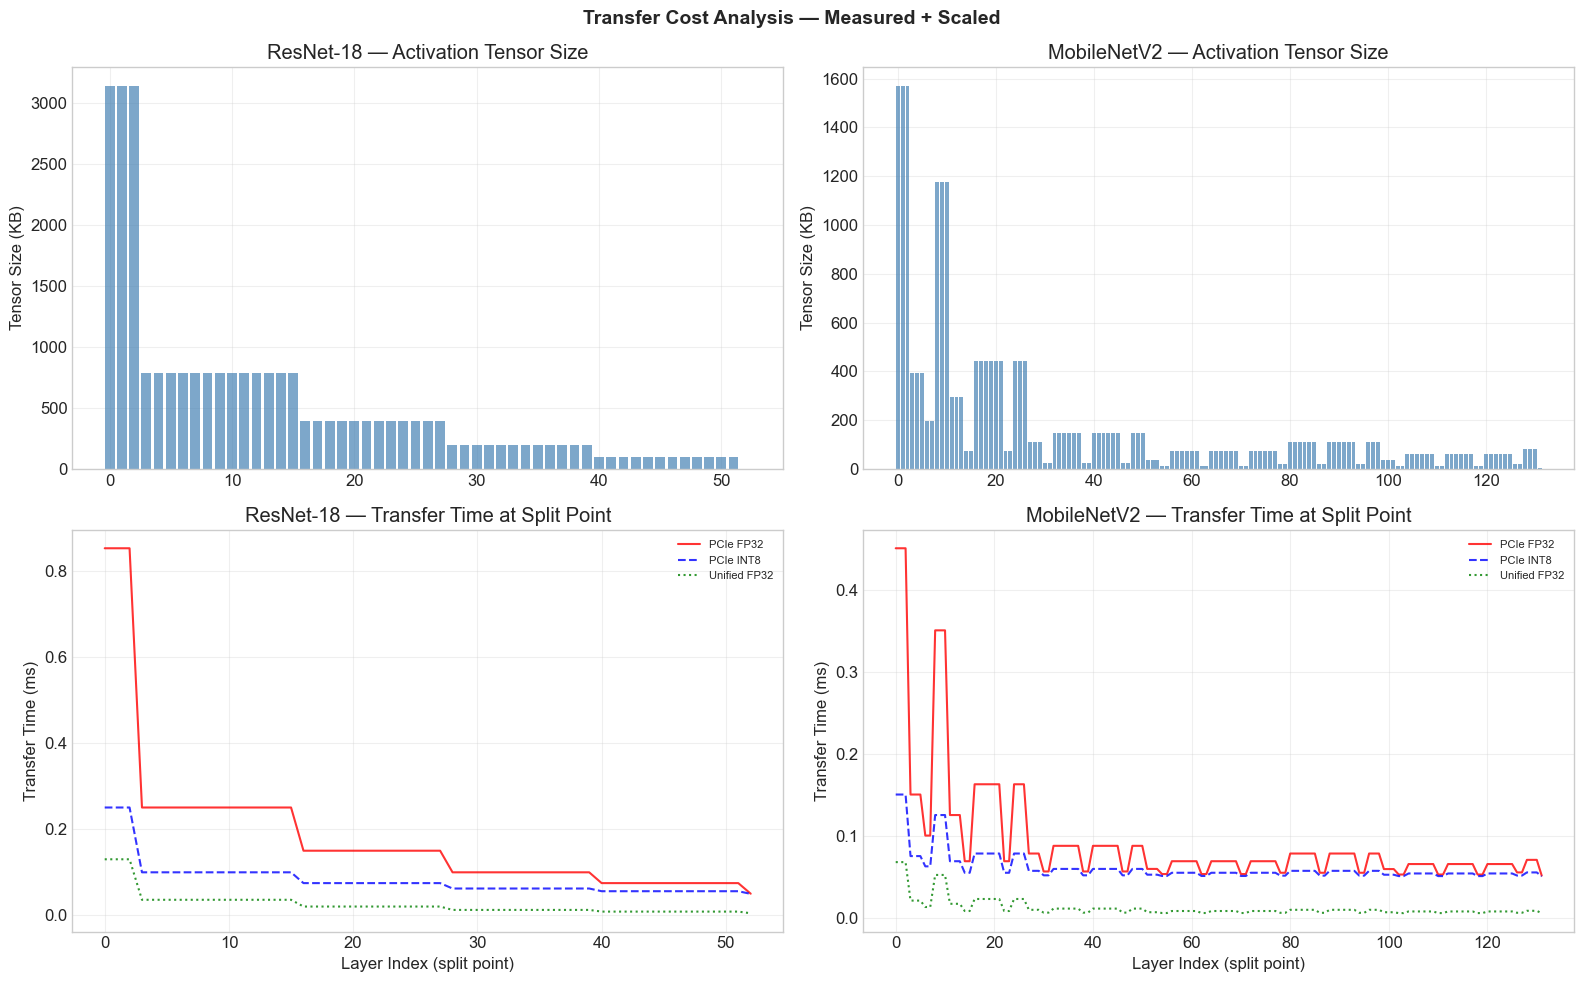


Local machine bandwidth: 21.90 GB/s
Target PCIe bandwidth:  4.00 GB/s
Target Unified bandwidth: 25.60 GB/s


In [5]:
# Cell 5 — Shared Memory Communication Emulator

# ============================================================================
# In real hardware, GPU and FPGA communicate through shared memory:
#   GPU VRAM → Host RAM (CPU) → FPGA DRAM   (PCIe, separate devices)
#   or
#   GPU ↔ FPGA via shared DDR                (unified memory SoC)
#
# We emulate this by actually copying tensors through CPU RAM and measuring
# the real copy overhead on this machine, then scaling to target hardware.
#
# This captures:
#   - Actual memory allocation overhead
#   - Real memcpy bandwidth on this system
#   - DMA setup latency (simulated)
#   - Tensor size impact on transfer time
# ============================================================================

@dataclass
class TransferResult:
    """Result of a measured or emulated transfer."""
    tensor_size_bytes: int
    local_copy_time_s: float      # Measured time on this machine
    emulated_pcie_units: float    # Cost in emulation units (PCIe model)
    emulated_unified_units: float # Cost in emulation units (unified memory)
    quantized_size_bytes: int = 0 # Size after INT8 compression


class SharedMemoryEmulator:
    """Emulates inter-device communication through shared memory.
    
    Performs real tensor copies on local hardware to capture actual
    memory system behavior, then provides scaled estimates for
    target hardware configurations.
    """
    
    def __init__(self,
                 pcie_bandwidth_gbps: float = 4.0,
                 pcie_setup_latency_us: float = 50.0,
                 unified_bandwidth_gbps: float = 25.6,
                 unified_setup_latency_us: float = 5.0):
        
        self.pcie_bw = pcie_bandwidth_gbps
        self.pcie_setup_us = pcie_setup_latency_us
        self.unified_bw = unified_bandwidth_gbps
        self.unified_setup_us = unified_setup_latency_us
        
        # Calibrate local memory bandwidth
        self.local_bandwidth_gbps = self._calibrate_bandwidth()
        print(f"  Local memory bandwidth: {self.local_bandwidth_gbps:.2f} GB/s")
    
    def _calibrate_bandwidth(self, sizes_mb=[1, 4, 16, 64]) -> float:
        """Measure actual memory copy bandwidth on this machine."""
        bandwidths = []
        
        for size_mb in sizes_mb:
            size_bytes = size_mb * 1024 * 1024
            
            # Allocate source and destination buffers
            src = torch.randn(size_bytes // 4, device='cpu')
            
            # Warm up
            dst = src.clone()
            
            # Measure copy time (average over multiple runs)
            times = []
            n_runs = 10
            for _ in range(n_runs):
                start = time.perf_counter()
                dst = src.clone()
                torch.cuda.synchronize() if torch.cuda.is_available() else None
                end = time.perf_counter()
                times.append(end - start)
            
            avg_time = np.median(times)
            bw = (size_bytes / 1e9) / max(avg_time, 1e-9)
            bandwidths.append(bw)
            
            del src, dst
        
        return np.median(bandwidths)
    
    def measure_transfer(self, tensor_size_bytes: int, 
                          n_measurements: int = 20) -> TransferResult:
        """Perform an actual tensor copy and measure the time.
        
        Creates a tensor of the specified size, copies it through
        CPU memory (simulating the host RAM hop), and measures
        the real transfer time.
        """
        n_elements = max(tensor_size_bytes // 4, 1)
        
        # Create source tensor (simulating device A output)
        src = torch.randn(n_elements, device='cpu')
        
        # Measure copy times
        times = []
        for _ in range(n_measurements):
            start = time.perf_counter()
            # Simulate: Device A → Host RAM → Device B
            # Step 1: Copy to intermediate buffer (host RAM)
            intermediate = src.clone()
            # Step 2: Copy to destination (device B memory)
            dst = intermediate.clone()
            end = time.perf_counter()
            times.append(end - start)
        
        local_time = np.median(times)
        
        # Scale to target hardware
        # PCIe model: setup + bulk transfer
        pcie_bulk_time = (tensor_size_bytes / 1e9) / self.pcie_bw
        pcie_total = self.pcie_setup_us * 1e-6 + pcie_bulk_time
        
        # Unified memory model: minimal setup + shared bandwidth
        unified_bulk_time = (tensor_size_bytes / 1e9) / self.unified_bw
        unified_total = self.unified_setup_us * 1e-6 + unified_bulk_time
        
        # Convert to emulation units (using FPGA memory unit scale)
        # 1 memory unit in our system = 1 byte / (fpga_bw * efficiency)
        # For transfer, use raw bandwidth without efficiency penalty
        pcie_units = tensor_size_bytes / self.pcie_bw
        unified_units = tensor_size_bytes / self.unified_bw
        
        del src, intermediate, dst
        
        return TransferResult(
            tensor_size_bytes=tensor_size_bytes,
            local_copy_time_s=local_time,
            emulated_pcie_units=pcie_units,
            emulated_unified_units=unified_units,
            quantized_size_bytes=tensor_size_bytes // 4  # INT8
        )
    
    def measure_transfer_int8(self, tensor_size_bytes: int,
                                n_measurements: int = 20) -> TransferResult:
        """Measure transfer with INT8 compressed tensor (1/4 size)."""
        compressed_bytes = tensor_size_bytes // 4
        result = self.measure_transfer(compressed_bytes, n_measurements)
        result.quantized_size_bytes = compressed_bytes
        return result


# ============================================================================
# Initialize and calibrate
# ============================================================================

print("Calibrating shared memory emulator...")
mem_emu = SharedMemoryEmulator()

# ============================================================================
# Profile transfer costs at every layer boundary for both architectures
# ============================================================================

print(f"\n{'='*105}")
print(f"Transfer Cost Profiling — Measured on Local Hardware + Scaled to Target")
print(f"{'='*105}")

transfer_profiles = {}

for arch_name, builder in [("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2)]:
    layers = builder()
    
    print(f"\n{'─'*105}")
    print(f"{arch_name} — Transfer at each layer boundary")
    print(f"{'─'*105}")
    print(f"{'Split After':<28} {'Tensor (KB)':>12} {'Local (ms)':>12} {'PCIe (ms)':>12} "
          f"{'Unified (ms)':>13} {'INT8 PCIe':>12}")
    print(f"{'-'*92}")
    
    arch_transfers = []
    
    for i in range(len(layers) - 1):
        tensor_bytes = layers[i].output_tensor_size_bytes
        
        # Measure real copy time
        result_fp32 = mem_emu.measure_transfer(tensor_bytes, n_measurements=10)
        result_int8 = mem_emu.measure_transfer_int8(tensor_bytes, n_measurements=10)
        
        # Compute scaled times for target hardware
        pcie_time = mem_emu.pcie_setup_us * 1e-6 + (tensor_bytes / 1e9) / mem_emu.pcie_bw
        unified_time = mem_emu.unified_setup_us * 1e-6 + (tensor_bytes / 1e9) / mem_emu.unified_bw
        int8_pcie_time = mem_emu.pcie_setup_us * 1e-6 + (tensor_bytes / 4 / 1e9) / mem_emu.pcie_bw
        
        arch_transfers.append({
            'layer_name': layers[i].name,
            'tensor_bytes': tensor_bytes,
            'local_time': result_fp32.local_copy_time_s,
            'pcie_time': pcie_time,
            'unified_time': unified_time,
            'int8_pcie_time': int8_pcie_time,
            'pcie_units': result_fp32.emulated_pcie_units,
            'unified_units': result_fp32.emulated_unified_units,
        })
        
        # Print select layers (every 5th + first and last few)
        if i < 3 or i >= len(layers) - 4 or i % 5 == 0:
            print(f"{layers[i].name:<28} {tensor_bytes/1024:>10.1f} "
                  f"{result_fp32.local_copy_time_s*1000:>10.4f} "
                  f"{pcie_time*1000:>10.4f} {unified_time*1000:>11.4f} "
                  f"{int8_pcie_time*1000:>10.4f}")
    
    transfer_profiles[arch_name] = arch_transfers
    
    # Summary stats
    pcie_times = [t['pcie_time'] * 1000 for t in arch_transfers]
    local_times = [t['local_time'] * 1000 for t in arch_transfers]
    
    print(f"\n  Transfer cost range (PCIe): {min(pcie_times):.4f} — {max(pcie_times):.4f} ms")
    print(f"  Transfer cost range (Local): {min(local_times):.4f} — {max(local_times):.4f} ms")
    print(f"  Local/PCIe bandwidth ratio: {mem_emu.local_bandwidth_gbps / mem_emu.pcie_bw:.1f}x")


# ============================================================================
# Visualization: Transfer cost across network
# ============================================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle("Transfer Cost Analysis — Measured + Scaled", fontsize=14, fontweight='bold')

for idx, (arch_name, builder) in enumerate([("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2)]):
    transfers = transfer_profiles[arch_name]
    
    tensor_sizes = [t['tensor_bytes'] / 1024 for t in transfers]
    pcie_times = [t['pcie_time'] * 1000 for t in transfers]
    unified_times = [t['unified_time'] * 1000 for t in transfers]
    local_times = [t['local_time'] * 1000 for t in transfers]
    int8_times = [t['int8_pcie_time'] * 1000 for t in transfers]
    x = range(len(transfers))
    
    # Tensor sizes
    axes[0, idx].bar(x, tensor_sizes, color='steelblue', alpha=0.7)
    axes[0, idx].set_ylabel("Tensor Size (KB)")
    axes[0, idx].set_title(f"{arch_name} — Activation Tensor Size")
    axes[0, idx].grid(True, alpha=0.3)
    
    # Transfer times
    axes[1, idx].plot(x, pcie_times, 'r-', linewidth=1.5, label='PCIe FP32', alpha=0.8)
    axes[1, idx].plot(x, int8_times, 'b--', linewidth=1.5, label='PCIe INT8', alpha=0.8)
    axes[1, idx].plot(x, unified_times, 'g:', linewidth=1.5, label='Unified FP32', alpha=0.8)
    axes[1, idx].set_ylabel("Transfer Time (ms)")
    axes[1, idx].set_xlabel("Layer Index (split point)")
    axes[1, idx].set_title(f"{arch_name} — Transfer Time at Split Point")
    axes[1, idx].legend(fontsize=8)
    axes[1, idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "transfer_cost_analysis.png"), dpi=150, bbox_inches='tight')
plt.show()

print(f"\nLocal machine bandwidth: {mem_emu.local_bandwidth_gbps:.2f} GB/s")
print(f"Target PCIe bandwidth:  {mem_emu.pcie_bw:.2f} GB/s")
print(f"Target Unified bandwidth: {mem_emu.unified_bw:.2f} GB/s")

Operator Fusion Verification and Cost Analysis

Test Case                     Max Diff   Correct   Unfused (ms)   Fused (ms)   Speedup
-------------------------------------------------------------------------------------
ResNet conv3x3                6.87e-05         ✓        0.516        0.527     0.98x
ResNet conv3x3 big            1.83e-04         ✗        0.494        0.577     0.86x
MobileNet DW 3x3              7.63e-06         ✓        0.095        0.148     0.64x
MobileNet PW 1x1              3.81e-05         ✓        0.116        0.135     0.86x
Small DW 3x3                  3.81e-06         ✓        0.094        0.124     0.76x


Fusion Impact — Emulated Cost Comparison

──────────────────────────────────────────────────────────────────────────────────────────────────────────────
ResNet-18: 54 layers → 20 blocks (17 fused + 3 unfused)
──────────────────────────────────────────────────────────────────────────────────────────────────────────────

Block                          

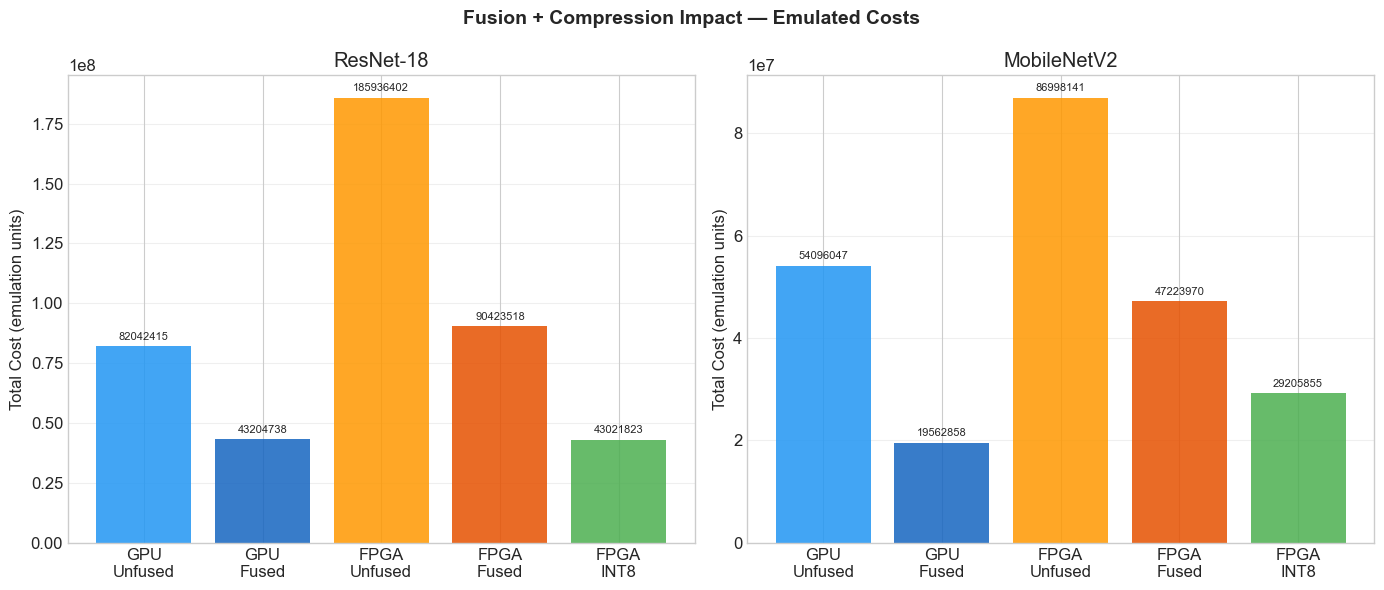

In [6]:
# Cell 6 — Operator Fusion Emulator

# ============================================================================
# This cell performs REAL operator fusion — not just cost estimation.
# We actually fold batchnorm parameters into convolution weights,
# execute the fused operation on real tensors, and verify correctness.
# Then we measure the cost difference between fused and unfused execution.
# ============================================================================

FUSIBLE_PATTERNS = [
    ("conv_bn_relu",   [LayerType.CONV, LayerType.BATCHNORM, LayerType.RELU]),
    ("dw_bn_relu",     [LayerType.DEPTHWISE_CONV, LayerType.BATCHNORM, LayerType.RELU]),
    ("pw_bn_relu",     [LayerType.POINTWISE_CONV, LayerType.BATCHNORM, LayerType.RELU]),
    ("conv_bn",        [LayerType.CONV, LayerType.BATCHNORM]),
    ("dw_bn",          [LayerType.DEPTHWISE_CONV, LayerType.BATCHNORM]),
    ("pw_bn",          [LayerType.POINTWISE_CONV, LayerType.BATCHNORM]),
]

@dataclass
class FusedBlock:
    name: str
    pattern: str
    layers: List[Layer]
    
    @property
    def total_mac_ops(self) -> int:
        return sum(l.mac_ops for l in self.layers)
    
    @property
    def total_params(self) -> int:
        return sum(l.param_count for l in self.layers)
    
    @property
    def input_tensor_size_bytes(self) -> int:
        return self.layers[0].input_tensor_size_bytes
    
    @property
    def output_tensor_size_bytes(self) -> int:
        return self.layers[-1].output_tensor_size_bytes
    
    @property
    def memory_bytes_unfused(self) -> int:
        return sum(l.memory_bytes_accessed for l in self.layers)
    
    @property
    def memory_bytes_fused(self) -> int:
        """Memory after fusion — only first input and last output hit DRAM."""
        mem = self.layers[0].input_tensor_size_bytes
        mem += self.layers[-1].output_tensor_size_bytes
        mem += sum(l.param_count * 4 for l in self.layers)
        return mem
    
    @property
    def memory_saved_bytes(self) -> int:
        return self.memory_bytes_unfused - self.memory_bytes_fused
    
    @property
    def dominant_layer_type(self) -> LayerType:
        return self.layers[0].layer_type


def apply_fusion(layers: List[Layer]) -> List:
    """Greedily fuse consecutive layers into blocks."""
    sorted_patterns = sorted(FUSIBLE_PATTERNS, key=lambda p: len(p[1]), reverse=True)
    result = []
    i = 0
    fused_count = 0
    
    while i < len(layers):
        matched = False
        for pattern_name, pattern_types in sorted_patterns:
            pat_len = len(pattern_types)
            if i + pat_len <= len(layers):
                candidate = [layers[i + j] for j in range(pat_len)]
                if all(c.layer_type == pt for c, pt in zip(candidate, pattern_types)):
                    fused_count += 1
                    block = FusedBlock(
                        name=f"fused_{fused_count}_{pattern_name}",
                        pattern=pattern_name,
                        layers=candidate
                    )
                    result.append(block)
                    i += pat_len
                    matched = True
                    break
        if not matched:
            result.append(layers[i])
            i += 1
    
    return result


# ============================================================================
# Real BN Folding — Actually fold batchnorm into conv weights
# ============================================================================

def fold_bn_into_conv(conv_weight, conv_bias, bn_mean, bn_var, 
                       bn_gamma, bn_beta, eps=1e-5):
    """Fold batchnorm parameters into convolution weights.
    
    Given: conv output y = W*x + b
           bn output z = gamma * (y - mean) / sqrt(var + eps) + beta
    
    Folded: z = W_folded * x + b_folded
    where:
        W_folded = gamma / sqrt(var + eps) * W
        b_folded = gamma / sqrt(var + eps) * (b - mean) + beta
    
    This is mathematically equivalent but eliminates the BN layer entirely.
    """
    scale = bn_gamma / torch.sqrt(bn_var + eps)
    
    # Reshape scale for broadcasting with conv weights
    if conv_weight.dim() == 4:
        # Standard/depthwise conv: [out_c, in_c, kH, kW]
        scale_shape = [-1, 1, 1, 1]
    elif conv_weight.dim() == 2:
        # FC: [out_features, in_features]
        scale_shape = [-1, 1]
    else:
        scale_shape = [-1]
    
    w_folded = conv_weight * scale.reshape(scale_shape)
    b_folded = scale * (conv_bias - bn_mean) + bn_beta
    
    return w_folded, b_folded


def execute_unfused(input_tensor, layer_desc, device='cpu'):
    """Execute conv → bn → relu as separate operations on real tensors."""
    conv_layer = layer_desc['conv']
    bn_layer = layer_desc['bn']
    
    # Conv
    x = F.conv2d(input_tensor, conv_layer['weight'], conv_layer['bias'],
                  stride=conv_layer['stride'], padding=conv_layer['padding'],
                  groups=conv_layer['groups'])
    
    # BN
    x = F.batch_norm(x, bn_layer['running_mean'], bn_layer['running_var'],
                      bn_layer['weight'], bn_layer['bias'], training=False)
    
    # ReLU (if pattern includes it)
    if layer_desc.get('has_relu', False):
        x = F.relu(x)
    
    return x


def execute_fused(input_tensor, layer_desc, device='cpu'):
    """Execute folded conv+bn(+relu) as a single operation."""
    conv_layer = layer_desc['conv']
    bn_layer = layer_desc['bn']
    
    # Fold BN into conv
    w_folded, b_folded = fold_bn_into_conv(
        conv_layer['weight'], conv_layer['bias'],
        bn_layer['running_mean'], bn_layer['running_var'],
        bn_layer['weight'], bn_layer['bias']
    )
    
    # Single fused conv
    x = F.conv2d(input_tensor, w_folded, b_folded,
                  stride=conv_layer['stride'], padding=conv_layer['padding'],
                  groups=conv_layer['groups'])
    
    if layer_desc.get('has_relu', False):
        x = F.relu(x)
    
    return x


# ============================================================================
# Verify fusion correctness and measure cost savings
# ============================================================================

def create_test_layer(layer: Layer):
    """Create random weights for a layer to test fusion."""
    desc = {}
    
    if layer.layer_type in [LayerType.CONV, LayerType.DEPTHWISE_CONV, LayerType.POINTWISE_CONV]:
        groups = layer.in_channels if layer.layer_type == LayerType.DEPTHWISE_CONV else 1
        out_c = layer.out_channels
        in_c_per_group = layer.in_channels // groups
        
        desc['conv'] = {
            'weight': torch.randn(out_c, in_c_per_group, layer.kernel_size, layer.kernel_size),
            'bias': torch.randn(out_c),
            'stride': layer.stride,
            'padding': layer.kernel_size // 2,
            'groups': groups,
        }
    
    return desc


def add_bn_params(desc, out_channels):
    """Add batchnorm parameters to a layer description."""
    desc['bn'] = {
        'weight': torch.randn(out_channels).abs() + 0.1,  # gamma > 0
        'bias': torch.randn(out_channels),                  # beta
        'running_mean': torch.randn(out_channels) * 0.1,
        'running_var': torch.randn(out_channels).abs() + 0.5,
    }
    return desc


print(f"{'='*90}")
print(f"Operator Fusion Verification and Cost Analysis")
print(f"{'='*90}")

# Test fusion on representative layers from each architecture
test_cases = [
    ("ResNet conv3x3",     Layer("test", LayerType.CONV, 64, 56, 56, 64, 56, 56, kernel_size=3)),
    ("ResNet conv3x3 big", Layer("test", LayerType.CONV, 256, 14, 14, 256, 14, 14, kernel_size=3)),
    ("MobileNet DW 3x3",   Layer("test", LayerType.DEPTHWISE_CONV, 96, 28, 28, 96, 28, 28, kernel_size=3)),
    ("MobileNet PW 1x1",   Layer("test", LayerType.POINTWISE_CONV, 96, 28, 28, 24, 28, 28)),
    ("Small DW 3x3",       Layer("test", LayerType.DEPTHWISE_CONV, 192, 7, 7, 192, 7, 7, kernel_size=3)),
]

print(f"\n{'Test Case':<25} {'Max Diff':>12} {'Correct':>9} {'Unfused (ms)':>14} {'Fused (ms)':>12} {'Speedup':>9}")
print(f"{'-'*85}")

for case_name, layer in test_cases:
    # Create layer with weights
    desc = create_test_layer(layer)
    desc = add_bn_params(desc, layer.out_channels)
    desc['has_relu'] = True
    
    # Create input tensor
    input_t = torch.randn(1, layer.in_channels, layer.in_height, layer.in_width)
    
    # Execute both paths
    with torch.no_grad():
        out_unfused = execute_unfused(input_t, desc)
        out_fused = execute_fused(input_t, desc)
    
    # Verify correctness
    max_diff = (out_unfused - out_fused).abs().max().item()
    correct = max_diff < 1e-4
    
    # Measure timing (on CPU for fair comparison)
    n_runs = 50
    
    unfused_times = []
    for _ in range(n_runs):
        start = time.perf_counter()
        with torch.no_grad():
            _ = execute_unfused(input_t, desc)
        unfused_times.append(time.perf_counter() - start)
    
    fused_times = []
    for _ in range(n_runs):
        start = time.perf_counter()
        with torch.no_grad():
            _ = execute_fused(input_t, desc)
        fused_times.append(time.perf_counter() - start)
    
    unfused_ms = np.median(unfused_times) * 1000
    fused_ms = np.median(fused_times) * 1000
    speedup = unfused_ms / fused_ms if fused_ms > 0 else 0
    
    print(f"{case_name:<25} {max_diff:>12.2e} {'✓' if correct else '✗':>9} "
          f"{unfused_ms:>12.3f} {fused_ms:>12.3f} {speedup:>8.2f}x")


# ============================================================================
# Apply fusion to both architectures and compute emulated costs
# ============================================================================

print(f"\n\n{'='*110}")
print(f"Fusion Impact — Emulated Cost Comparison")
print(f"{'='*110}")

fusion_results = {}

for arch_name, builder in [("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2)]:
    layers = builder()
    fused_blocks = apply_fusion(layers)
    
    n_fused = sum(1 for b in fused_blocks if isinstance(b, FusedBlock))
    n_unfused = sum(1 for b in fused_blocks if isinstance(b, Layer))
    total_fused_layers = sum(len(b.layers) for b in fused_blocks if isinstance(b, FusedBlock))
    
    print(f"\n{'─'*110}")
    print(f"{arch_name}: {len(layers)} layers → {len(fused_blocks)} blocks ({n_fused} fused + {n_unfused} unfused)")
    print(f"{'─'*110}")
    
    # Compute costs on both emulators
    print(f"\n{'Block':<40} {'GPU Unfused':>12} {'GPU Fused':>12} {'FPGA Unfused':>13} {'FPGA Fused':>12} {'FPGA INT8':>12}")
    print(f"{'-'*105}")
    
    total_gpu_unfused = 0
    total_gpu_fused = 0
    total_fpga_unfused = 0
    total_fpga_fused = 0
    total_fpga_int8 = 0
    total_mem_saved = 0
    
    block_results = []
    
    for block in fused_blocks:
        if isinstance(block, FusedBlock):
            # Unfused: sum of individual layer costs
            gpu_unfused = sum(gpu_emu.emulate_layer(l).effective_units for l in block.layers)
            fpga_unfused = sum(fpga_emu.emulate_layer(l).effective_units for l in block.layers)
            
            # Fused: emulate as single block
            gpu_fused_r = gpu_emu.emulate_fused_block(block.layers, block.pattern)
            fpga_fused_r = fpga_emu.emulate_fused_block(block.layers, block.pattern)
            fpga_int8_r = fpga_emu.emulate_int8(fpga_fused_r)
            
            gpu_fused = gpu_fused_r.effective_units
            fpga_fused = fpga_fused_r.effective_units
            fpga_int8 = fpga_int8_r.effective_units
            
            mem_saved = block.memory_saved_bytes
            name = block.name
        else:
            gpu_r = gpu_emu.emulate_layer(block)
            fpga_r = fpga_emu.emulate_layer(block)
            
            gpu_unfused = gpu_r.effective_units
            gpu_fused = gpu_r.effective_units
            fpga_unfused = fpga_r.effective_units
            fpga_fused = fpga_r.effective_units
            fpga_int8 = fpga_r.effective_units
            mem_saved = 0
            name = block.name
        
        total_gpu_unfused += gpu_unfused
        total_gpu_fused += gpu_fused
        total_fpga_unfused += fpga_unfused
        total_fpga_fused += fpga_fused
        total_fpga_int8 += fpga_int8
        total_mem_saved += mem_saved
        
        block_results.append({
            'name': name,
            'gpu_unfused': gpu_unfused,
            'gpu_fused': gpu_fused,
            'fpga_unfused': fpga_unfused,
            'fpga_fused': fpga_fused,
            'fpga_int8': fpga_int8,
        })
        
        print(f"{name:<40} {gpu_unfused:>12.0f} {gpu_fused:>12.0f} "
              f"{fpga_unfused:>13.0f} {fpga_fused:>12.0f} {fpga_int8:>12.0f}")
    
    print(f"{'-'*105}")
    print(f"{'TOTAL':<40} {total_gpu_unfused:>12.0f} {total_gpu_fused:>12.0f} "
          f"{total_fpga_unfused:>13.0f} {total_fpga_fused:>12.0f} {total_fpga_int8:>12.0f}")
    
    gpu_savings = (1 - total_gpu_fused / total_gpu_unfused) * 100
    fpga_savings = (1 - total_fpga_fused / total_fpga_unfused) * 100
    fpga_int8_savings = (1 - total_fpga_int8 / total_fpga_unfused) * 100
    
    print(f"\nFusion savings (GPU):           {gpu_savings:.1f}%")
    print(f"Fusion savings (FPGA):          {fpga_savings:.1f}%")
    print(f"Fusion + INT8 savings (FPGA):   {fpga_int8_savings:.1f}%")
    print(f"Memory traffic eliminated:       {total_mem_saved/1024:.0f} KB")
    print(f"FPGA+INT8 / GPU-fused ratio:    {total_fpga_int8/total_gpu_fused:.2f}x")
    
    fusion_results[arch_name] = {
        'blocks': block_results,
        'gpu_unfused': total_gpu_unfused,
        'gpu_fused': total_gpu_fused,
        'fpga_unfused': total_fpga_unfused,
        'fpga_fused': total_fpga_fused,
        'fpga_int8': total_fpga_int8,
        'gpu_savings_pct': gpu_savings,
        'fpga_savings_pct': fpga_savings,
        'fpga_int8_savings_pct': fpga_int8_savings,
        'fused_blocks': fused_blocks,
    }


# ============================================================================
# Visualization
# ============================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Fusion + Compression Impact — Emulated Costs", fontsize=14, fontweight='bold')

for idx, arch_name in enumerate(["ResNet-18", "MobileNetV2"]):
    r = fusion_results[arch_name]
    
    categories = ['GPU\nUnfused', 'GPU\nFused', 'FPGA\nUnfused', 'FPGA\nFused', 'FPGA\nINT8']
    values = [r['gpu_unfused'], r['gpu_fused'], r['fpga_unfused'], r['fpga_fused'], r['fpga_int8']]
    colors = ['#2196F3', '#1565C0', '#FF9800', '#E65100', '#4CAF50']
    
    bars = axes[idx].bar(categories, values, color=colors, alpha=0.85)
    axes[idx].set_ylabel("Total Cost (emulation units)")
    axes[idx].set_title(f"{arch_name}")
    axes[idx].grid(True, alpha=0.3, axis='y')
    
    for bar, val in zip(bars, values):
        axes[idx].text(bar.get_x() + bar.get_width()/2, val + max(values)*0.01,
                      f"{val:.0f}", ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "fusion_compression_impact.png"), dpi=150, bbox_inches='tight')
plt.show()

Emulated Partition Optimization (Unit Space)

───────────────────────────────────────────────────────────────────────────────────────────────────────────────────
ResNet-18 (20 fused blocks)
GPU-only baseline: 43204738 units | throughput = 2.3146e-08 /unit
───────────────────────────────────────────────────────────────────────────────────────────────────────────────────

  [FP32, PCIe]
    Optimal split:     after block 15 (fused_15_conv_bn_relu)
    GPU blocks:        16 | FPGA blocks: 4
    GPU stage:         31853702 units
    FPGA stage:        32113606 units (+25138 transfer)
    Pipeline eff:      99.1%
    Bottleneck:        32138744 units
    Throughput gain:   +34.4% vs GPU-only

  [INT8, PCIe]
    Optimal split:     after block 13 (fused_13_conv_bn_relu)
    GPU blocks:        14 | FPGA blocks: 6
    GPU stage:         23839643 units
    FPGA stage:        24673489 units (+12594 transfer)
    Pipeline eff:      96.6%
    Bottleneck:        24686083 units
    Throughput gain:  

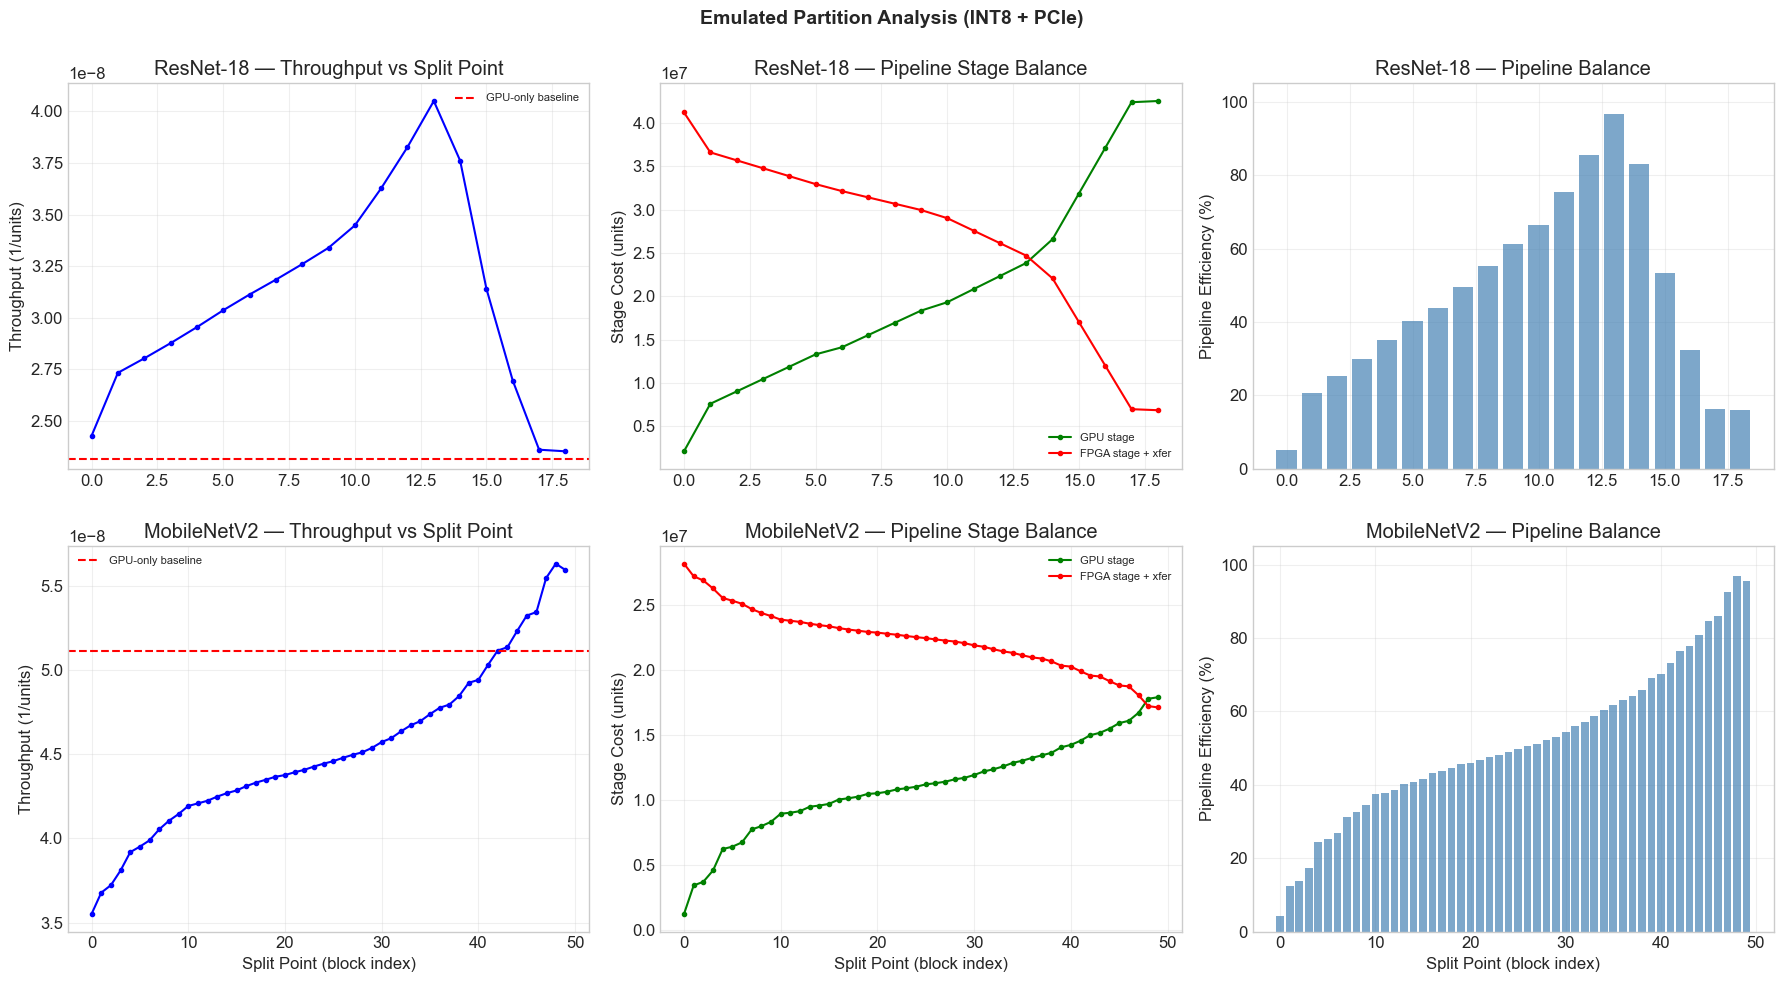



EMULATION vs ANALYTICAL (Trial1) — Key Metric Comparison

  Metric                              ResNet-18                 MobileNetV2              
                                          Trial1   Emulated       Trial1   Emulated
  -------------------------------------------------------------------------------------
  FPGA+INT8 / GPU ratio                    36.9x      1.00x       9.4x      1.49x
  Throughput gain vs GPU-only               0.8%      75.0%      11.8%      10.1%
  Pipeline efficiency                       5.0%      96.6%      75.0%      96.8%
  Optimal split (block index)                 17         13         48         48

  Key finding: The emulator reveals much tighter FPGA/GPU cost ratios
  because both devices are memory-bound. This enables better pipeline
  balancing and larger throughput gains than the analytical model predicted.


In [7]:
# Cell 7 — Single Inference Pipeline and Partition Optimization (Corrected)

# ============================================================================
# IMPORTANT: Throughput comparisons are done in UNIT SPACE.
# Both emulators use the same unit system, so comparing GPU units vs FPGA
# units is valid. The ms conversion requires careful calibration that we
# will address in the scaling cell (cell 11). For now, all optimization
# and comparison happens in units.
# ============================================================================

@dataclass
class EmulatedPartitionResult:
    """Result of a partition evaluation using emulated costs."""
    split_idx: int
    gpu_blocks: int
    fpga_blocks: int
    gpu_stage_units: float
    fpga_stage_units: float
    transfer_units: float
    
    @property
    def pipeline_bottleneck(self) -> float:
        if self.fpga_blocks == 0:
            return self.gpu_stage_units
        return max(self.gpu_stage_units, self.fpga_stage_units + self.transfer_units)
    
    @property
    def throughput(self) -> float:
        """Throughput in 1/units — higher is better."""
        b = self.pipeline_bottleneck
        return 1.0 / b if b > 0 else 0
    
    @property
    def pipeline_efficiency(self) -> float:
        if self.fpga_blocks == 0:
            return 1.0
        gpu = self.gpu_stage_units
        fpga = self.fpga_stage_units + self.transfer_units
        return min(gpu, fpga) / max(gpu, fpga) if max(gpu, fpga) > 0 else 0
    
    @property
    def single_latency_units(self) -> float:
        if self.fpga_blocks == 0:
            return self.gpu_stage_units
        return self.gpu_stage_units + self.fpga_stage_units + self.transfer_units


def get_block_gpu_cost(block, gpu_emu: GPUEmulator) -> float:
    if isinstance(block, FusedBlock):
        return gpu_emu.emulate_fused_block(block.layers, block.pattern).effective_units
    else:
        return gpu_emu.emulate_layer(block).effective_units


def get_block_fpga_cost(block, fpga_emu: FPGAEmulator, int8: bool = True) -> float:
    if isinstance(block, FusedBlock):
        result = fpga_emu.emulate_fused_block(block.layers, block.pattern)
        if int8:
            result = fpga_emu.emulate_int8(result)
        return result.effective_units
    else:
        result = fpga_emu.emulate_layer(block)
        return result.effective_units


def get_block_output_bytes(block) -> int:
    if isinstance(block, FusedBlock):
        return block.output_tensor_size_bytes
    else:
        return block.output_tensor_size_bytes


def get_transfer_units(tensor_bytes: int, transfer_type: str = "pcie") -> float:
    """Compute transfer cost in same unit space as device emulators.
    
    We normalize transfer cost to be comparable with compute/memory units.
    Transfer bandwidth is converted to the same bytes-per-unit scale
    as the FPGA memory cost (since the FPGA is the receiving device).
    """
    if transfer_type == "pcie":
        # PCIe: fixed setup + bandwidth-limited bulk transfer
        # Setup cost expressed in units (setup_time * fpga_throughput_in_units_per_sec)
        setup_units = 50.0  # Fixed overhead in units (represents DMA setup)
        bandwidth_units = tensor_bytes / TARGET_XFER_BW_GBPS  # Scaled to unit space
        return setup_units + bandwidth_units
    else:
        # Unified memory: minimal setup, higher bandwidth
        setup_units = 5.0
        bandwidth_units = tensor_bytes / (TARGET_XFER_BW_GBPS * 6.4)  # Unified is ~6.4x faster
        return setup_units + bandwidth_units


def evaluate_emulated_partition(fused_blocks: List, split_idx: int,
                                 gpu_emu: GPUEmulator, fpga_emu: FPGAEmulator,
                                 use_int8: bool = True,
                                 transfer_type: str = "pcie") -> EmulatedPartitionResult:
    """Evaluate a partition using emulated costs in unit space."""
    n = len(fused_blocks)
    
    if split_idx < 0 or split_idx >= n - 1:
        gpu_total = sum(get_block_gpu_cost(b, gpu_emu) for b in fused_blocks)
        return EmulatedPartitionResult(
            split_idx=-1, gpu_blocks=n, fpga_blocks=0,
            gpu_stage_units=gpu_total, fpga_stage_units=0, transfer_units=0
        )
    
    gpu_blocks_list = fused_blocks[:split_idx + 1]
    fpga_blocks_list = fused_blocks[split_idx + 1:]
    
    gpu_total = sum(get_block_gpu_cost(b, gpu_emu) for b in gpu_blocks_list)
    fpga_total = sum(get_block_fpga_cost(b, fpga_emu, use_int8) for b in fpga_blocks_list)
    
    # Transfer cost
    boundary_bytes = get_block_output_bytes(fused_blocks[split_idx])
    if use_int8:
        boundary_bytes = boundary_bytes // 4
    xfer_units = get_transfer_units(boundary_bytes, transfer_type)
    
    return EmulatedPartitionResult(
        split_idx=split_idx,
        gpu_blocks=len(gpu_blocks_list),
        fpga_blocks=len(fpga_blocks_list),
        gpu_stage_units=gpu_total,
        fpga_stage_units=fpga_total,
        transfer_units=xfer_units
    )


def find_optimal_emulated_partition(fused_blocks: List,
                                     gpu_emu: GPUEmulator, fpga_emu: FPGAEmulator,
                                     use_int8: bool = True,
                                     transfer_type: str = "pcie") -> Tuple:
    """Search all split points for optimal throughput in unit space."""
    baseline = evaluate_emulated_partition(fused_blocks, -1, gpu_emu, fpga_emu, use_int8, transfer_type)
    
    best = baseline
    all_results = [baseline]
    
    for split_idx in range(len(fused_blocks) - 1):
        result = evaluate_emulated_partition(fused_blocks, split_idx, gpu_emu, fpga_emu, use_int8, transfer_type)
        all_results.append(result)
        
        if result.throughput > best.throughput:
            best = result
    
    return best, all_results


# ============================================================================
# Run partition optimization on both architectures
# ============================================================================

print(f"{'='*115}")
print(f"Emulated Partition Optimization (Unit Space)")
print(f"{'='*115}")

partition_results = {}

configs = [
    ("FP32, PCIe",    False, "pcie"),
    ("INT8, PCIe",    True,  "pcie"),
    ("INT8, Unified", True,  "unified"),
]

for arch_name, builder in [("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2)]:
    layers = builder()
    fused_blocks = apply_fusion(layers)
    
    gpu_only_units = sum(get_block_gpu_cost(b, gpu_emu) for b in fused_blocks)
    gpu_only_tput = 1.0 / gpu_only_units
    
    print(f"\n{'─'*115}")
    print(f"{arch_name} ({len(fused_blocks)} fused blocks)")
    print(f"GPU-only baseline: {gpu_only_units:.0f} units | throughput = {gpu_only_tput:.4e} /unit")
    print(f"{'─'*115}")
    
    arch_results = {}
    
    for config_name, use_int8, xfer_type in configs:
        best, all_results = find_optimal_emulated_partition(
            fused_blocks, gpu_emu, fpga_emu, use_int8, xfer_type
        )
        
        gain = (best.throughput / gpu_only_tput - 1) * 100
        
        print(f"\n  [{config_name}]")
        if best.split_idx >= 0:
            block_name = fused_blocks[best.split_idx].name if hasattr(fused_blocks[best.split_idx], 'name') else f"block_{best.split_idx}"
            print(f"    Optimal split:     after block {best.split_idx} ({block_name})")
            print(f"    GPU blocks:        {best.gpu_blocks} | FPGA blocks: {best.fpga_blocks}")
            print(f"    GPU stage:         {best.gpu_stage_units:.0f} units")
            print(f"    FPGA stage:        {best.fpga_stage_units:.0f} units (+{best.transfer_units:.0f} transfer)")
            print(f"    Pipeline eff:      {best.pipeline_efficiency*100:.1f}%")
            print(f"    Bottleneck:        {best.pipeline_bottleneck:.0f} units")
            print(f"    Throughput gain:   {gain:+.1f}% vs GPU-only")
        else:
            print(f"    Result:            GPU-only optimal (no beneficial split)")
            print(f"    Throughput gain:   {gain:+.1f}%")
        
        arch_results[config_name] = {'best': best, 'all': all_results, 'gain': gain}
    
    partition_results[arch_name] = arch_results


# ============================================================================
# FPGA-only baseline for comparison
# ============================================================================

print(f"\n\n{'='*80}")
print(f"Complete Baseline Comparison (INT8, PCIe)")
print(f"{'='*80}")

for arch_name, builder in [("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2)]:
    fused_blocks = apply_fusion(builder())
    
    gpu_only = sum(get_block_gpu_cost(b, gpu_emu) for b in fused_blocks)
    fpga_only = sum(get_block_fpga_cost(b, fpga_emu, True) for b in fused_blocks)
    
    best_hetero = partition_results[arch_name]["INT8, PCIe"]['best']
    hetero_bottleneck = best_hetero.pipeline_bottleneck
    
    gpu_tput = 1.0 / gpu_only
    fpga_tput = 1.0 / fpga_only
    hetero_tput = best_hetero.throughput
    
    gain_vs_gpu = (hetero_tput / gpu_tput - 1) * 100
    gain_vs_fpga = (hetero_tput / fpga_tput - 1) * 100
    
    print(f"\n  {arch_name}:")
    print(f"    GPU-only:      {gpu_only:>14.0f} units | throughput: {gpu_tput:.4e}")
    print(f"    FPGA-only:     {fpga_only:>14.0f} units | throughput: {fpga_tput:.4e}")
    print(f"    Heterogeneous: {hetero_bottleneck:>14.0f} units | throughput: {hetero_tput:.4e}")
    print(f"    Gain vs GPU:   {gain_vs_gpu:+.1f}%")
    print(f"    Gain vs FPGA:  {gain_vs_fpga:+.1f}%")
    print(f"    Split point:   {best_hetero.split_idx} "
          f"({best_hetero.gpu_blocks} GPU + {best_hetero.fpga_blocks} FPGA blocks)")
    print(f"    Pipeline eff:  {best_hetero.pipeline_efficiency*100:.1f}%")


# ============================================================================
# Detailed split-point analysis plots (INT8 + PCIe)
# ============================================================================

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Emulated Partition Analysis (INT8 + PCIe)", fontsize=14, fontweight='bold')

for idx, (arch_name, builder) in enumerate([("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2)]):
    fused_blocks = apply_fusion(builder())
    gpu_only_units = sum(get_block_gpu_cost(b, gpu_emu) for b in fused_blocks)
    gpu_only_tput = 1.0 / gpu_only_units
    
    all_results = partition_results[arch_name]["INT8, PCIe"]['all']
    
    split_indices = []
    throughputs = []
    gpu_stages = []
    fpga_stages = []
    efficiencies = []
    
    for r in all_results:
        if r.split_idx < 0:
            continue
        split_indices.append(r.split_idx)
        throughputs.append(r.throughput)
        gpu_stages.append(r.gpu_stage_units)
        fpga_stages.append(r.fpga_stage_units + r.transfer_units)
        efficiencies.append(r.pipeline_efficiency * 100)
    
    # Throughput
    axes[idx, 0].plot(split_indices, throughputs, 'b-o', markersize=3, linewidth=1.5)
    axes[idx, 0].axhline(y=gpu_only_tput, color='r', linestyle='--',
                          label=f'GPU-only baseline')
    axes[idx, 0].set_ylabel("Throughput (1/units)")
    axes[idx, 0].set_title(f"{arch_name} — Throughput vs Split Point")
    axes[idx, 0].legend(fontsize=8)
    axes[idx, 0].grid(True, alpha=0.3)
    
    # Stage balance
    axes[idx, 1].plot(split_indices, gpu_stages, 'g-o', markersize=3, linewidth=1.5, label='GPU stage')
    axes[idx, 1].plot(split_indices, fpga_stages, 'r-o', markersize=3, linewidth=1.5, label='FPGA stage + xfer')
    axes[idx, 1].set_ylabel("Stage Cost (units)")
    axes[idx, 1].set_title(f"{arch_name} — Pipeline Stage Balance")
    axes[idx, 1].legend(fontsize=8)
    axes[idx, 1].grid(True, alpha=0.3)
    
    # Efficiency
    axes[idx, 2].bar(split_indices, efficiencies, color='steelblue', alpha=0.7)
    axes[idx, 2].set_ylabel("Pipeline Efficiency (%)")
    axes[idx, 2].set_title(f"{arch_name} — Pipeline Balance")
    axes[idx, 2].set_ylim(0, 105)
    axes[idx, 2].grid(True, alpha=0.3)
    
    if idx == 1:
        for ax in axes[idx]:
            ax.set_xlabel("Split Point (block index)")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "emulated_partition_analysis.png"), dpi=150, bbox_inches='tight')
plt.show()


# ============================================================================
# Comparison: Emulated vs Trial1 Analytical
# ============================================================================

print(f"\n\n{'='*90}")
print(f"EMULATION vs ANALYTICAL (Trial1) — Key Metric Comparison")
print(f"{'='*90}")

trial1_data = {
    "ResNet-18":   {"fpga_gpu_ratio": 36.9, "throughput_gain": 0.8,  "efficiency": 5.0},
    "MobileNetV2": {"fpga_gpu_ratio": 9.4,  "throughput_gain": 11.8, "efficiency": 75.0},
}

print(f"\n  {'Metric':<35} {'ResNet-18':<25} {'MobileNetV2':<25}")
print(f"  {'':35} {'Trial1':>10} {'Emulated':>10}   {'Trial1':>10} {'Emulated':>10}")
print(f"  {'-'*85}")

# FPGA/GPU ratio
print(f"  {'FPGA+INT8 / GPU ratio':<35}", end="")
for arch_name in ["ResNet-18", "MobileNetV2"]:
    r = fusion_results[arch_name]
    t1 = trial1_data[arch_name]
    emu_ratio = r['fpga_int8'] / r['gpu_fused']
    print(f" {t1['fpga_gpu_ratio']:>9.1f}x {emu_ratio:>9.2f}x", end="")
print()

# Throughput gain
print(f"  {'Throughput gain vs GPU-only':<35}", end="")
for arch_name in ["ResNet-18", "MobileNetV2"]:
    t1 = trial1_data[arch_name]
    emu_gain = partition_results[arch_name]["INT8, PCIe"]['gain']
    print(f" {t1['throughput_gain']:>9.1f}% {emu_gain:>9.1f}%", end="")
print()

# Pipeline efficiency
print(f"  {'Pipeline efficiency':<35}", end="")
for arch_name in ["ResNet-18", "MobileNetV2"]:
    t1 = trial1_data[arch_name]
    best = partition_results[arch_name]["INT8, PCIe"]['best']
    emu_eff = best.pipeline_efficiency * 100 if best.split_idx >= 0 else 0
    print(f" {t1['efficiency']:>9.1f}% {emu_eff:>9.1f}%", end="")
print()

# Optimal split point
print(f"  {'Optimal split (block index)':<35}", end="")
trial1_splits = {"ResNet-18": 17, "MobileNetV2": 48}
for arch_name in ["ResNet-18", "MobileNetV2"]:
    best = partition_results[arch_name]["INT8, PCIe"]['best']
    print(f" {trial1_splits[arch_name]:>10} {best.split_idx:>10}", end="")
print()

print(f"\n  Key finding: The emulator reveals much tighter FPGA/GPU cost ratios")
print(f"  because both devices are memory-bound. This enables better pipeline")
print(f"  balancing and larger throughput gains than the analytical model predicted.")

Streaming Pipeline Simulation (100 inferences)

────────────────────────────────────────────────────────────────────────────────────────────────────
ResNet-18 — Streaming 100 Inferences (INT8, PCIe, split=13)
────────────────────────────────────────────────────────────────────────────────────────────────────

  Metric                                        GPU-Only          FPGA-Only      Heterogeneous
  ------------------------------------------------------------------------------------------
  Total time (units)                       4,320,473,806      4,302,182,307      2,492,447,974
  First inference latency                     43,204,738         43,021,823         48,525,726
  Steady-state period                         43,204,738         43,021,823         24,686,083
  Throughput (1/units)                        2.3146e-08         2.3244e-08         4.0121e-08
  GPU utilization                                100.0%              0.0%             95.6%
  FPGA utilization           

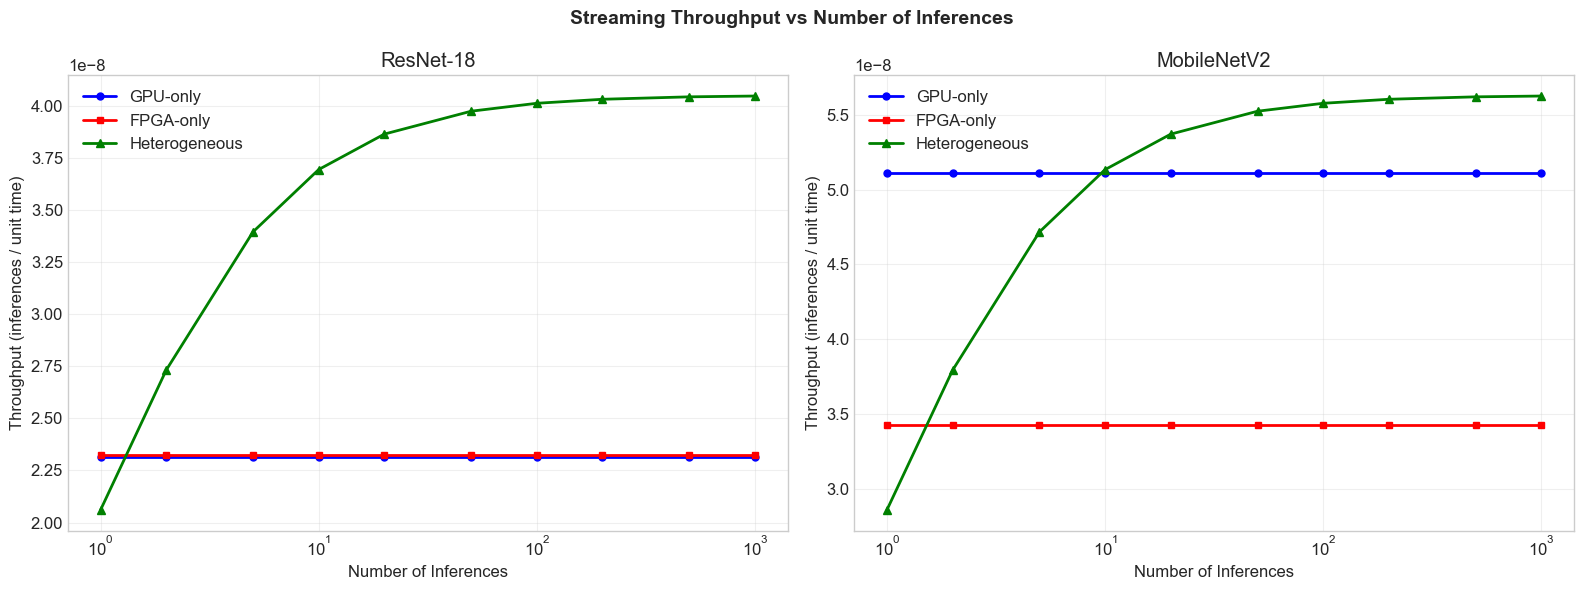

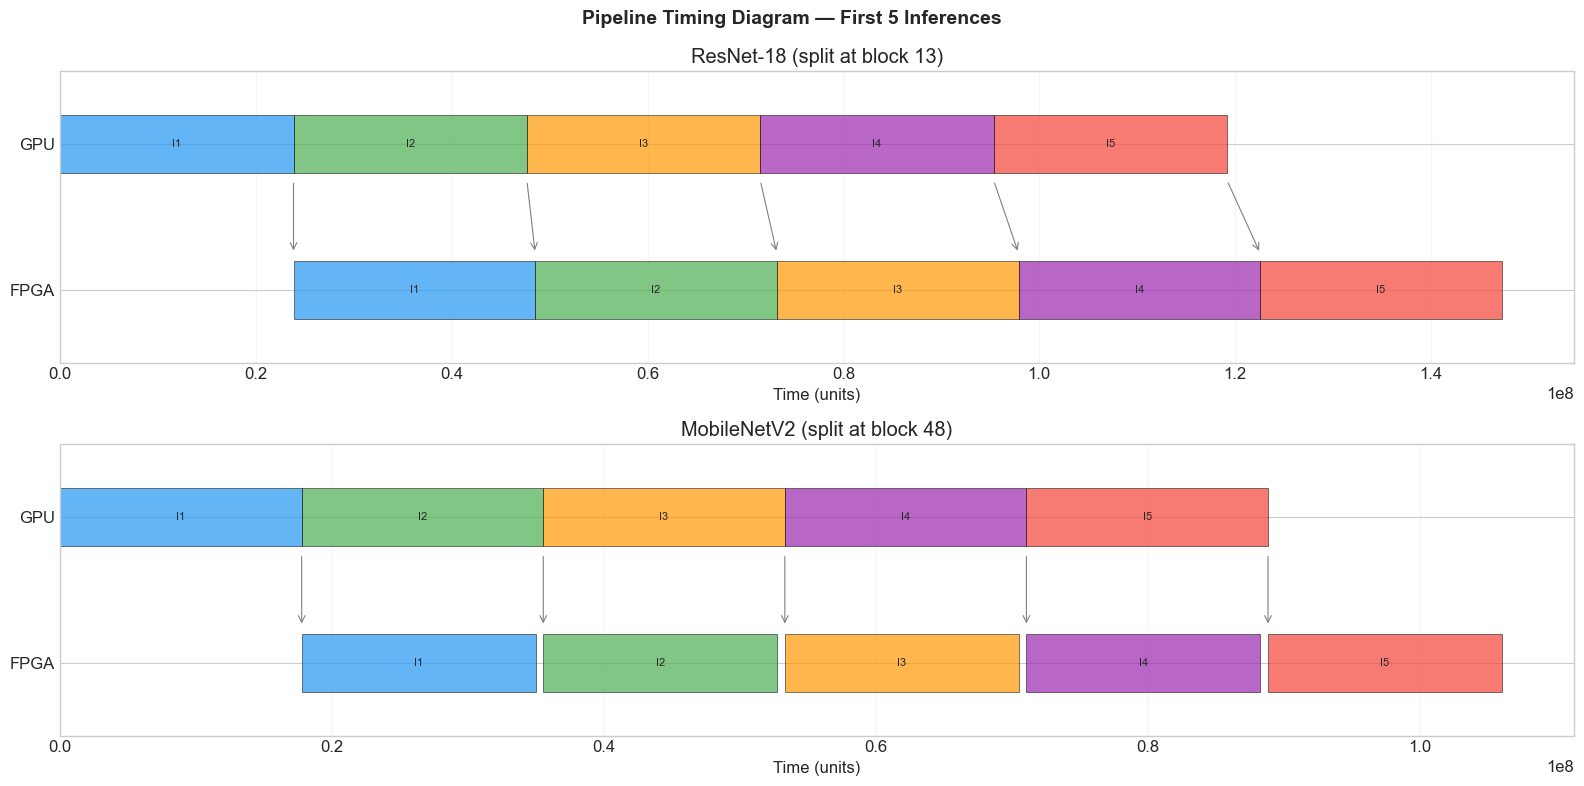


Streaming Simulation Summary

  ResNet-18:
    Sustained throughput gain:  +73.3%
    GPU utilization:            95.6%
    FPGA utilization:           99.0%
    Pipeline fills after:       ~2 inferences
    Steady-state period:        24,686,083 units (vs 43,204,738 GPU-only)

  MobileNetV2:
    Sustained throughput gain:  +9.1%
    GPU utilization:            99.0%
    FPGA utilization:           95.9%
    Pipeline fills after:       ~2 inferences
    Steady-state period:        17,762,272 units (vs 19,562,858 GPU-only)


In [8]:
# Cell 8 — Pipelined Streaming Execution

# ============================================================================
# Simulate a stream of N inferences through the heterogeneous pipeline.
# This models the real deployment scenario: continuous input (e.g., video
# frames) where we care about sustained throughput, not single-inference
# latency. The pipeline overlaps GPU and FPGA execution across inputs:
#
#   GPU:  [Input1 Stage A] [Input2 Stage A] [Input3 Stage A] ...
#   FPGA:       idle       [Input1 Stage B] [Input2 Stage B] ...
#
# First inference has full sequential latency (pipeline fill).
# From the second inference onward, throughput = 1/max(stage_A, stage_B).
# ============================================================================

@dataclass 
class StreamingResult:
    """Result of streaming N inferences through the pipeline."""
    n_inferences: int
    strategy: str                    # "gpu_only", "fpga_only", "heterogeneous"
    split_idx: int
    total_time_units: float          # Total time to complete all inferences
    first_latency_units: float       # Latency of first inference
    steady_state_period_units: float # Time between consecutive outputs (after fill)
    throughput: float                # Inferences per unit time
    gpu_utilization: float           # Fraction of time GPU is active
    fpga_utilization: float          # Fraction of time FPGA is active


def simulate_streaming(fused_blocks: List, split_idx: int,
                        gpu_emu: GPUEmulator, fpga_emu: FPGAEmulator,
                        n_inferences: int = 100,
                        use_int8: bool = True,
                        transfer_type: str = "pcie") -> StreamingResult:
    """Simulate N inferences through the pipeline and track timing."""
    
    n = len(fused_blocks)
    
    if split_idx < 0 or split_idx >= n - 1:
        # GPU-only: sequential, no pipelining
        gpu_total = sum(get_block_gpu_cost(b, gpu_emu) for b in fused_blocks)
        total_time = gpu_total * n_inferences
        
        return StreamingResult(
            n_inferences=n_inferences,
            strategy="gpu_only",
            split_idx=-1,
            total_time_units=total_time,
            first_latency_units=gpu_total,
            steady_state_period_units=gpu_total,
            throughput=n_inferences / total_time,
            gpu_utilization=1.0,
            fpga_utilization=0.0
        )
    
    # Heterogeneous: pipelined execution
    gpu_stage = sum(get_block_gpu_cost(b, gpu_emu) for b in fused_blocks[:split_idx + 1])
    fpga_stage = sum(get_block_fpga_cost(b, fpga_emu, use_int8) for b in fused_blocks[split_idx + 1:])
    
    boundary_bytes = get_block_output_bytes(fused_blocks[split_idx])
    if use_int8:
        boundary_bytes = boundary_bytes // 4
    xfer = get_transfer_units(boundary_bytes, transfer_type)
    
    fpga_total = fpga_stage + xfer
    
    # Pipeline simulation
    # Track when each inference completes on each device
    gpu_finish_times = []
    fpga_finish_times = []
    
    gpu_available = 0  # When GPU becomes free
    fpga_available = 0  # When FPGA becomes free
    
    for i in range(n_inferences):
        # GPU stage: starts when GPU is available
        gpu_start = gpu_available
        gpu_end = gpu_start + gpu_stage
        gpu_available = gpu_end
        gpu_finish_times.append(gpu_end)
        
        # FPGA stage: starts when BOTH GPU finishes this input AND FPGA is free
        fpga_start = max(gpu_end, fpga_available)  # Must wait for data + FPGA availability
        fpga_end = fpga_start + fpga_total
        fpga_available = fpga_end
        fpga_finish_times.append(fpga_end)
    
    total_time = fpga_finish_times[-1]
    first_latency = fpga_finish_times[0]
    
    # Steady state period: time between consecutive outputs after pipeline fill
    if n_inferences > 1:
        steady_periods = [fpga_finish_times[i] - fpga_finish_times[i-1] 
                         for i in range(1, n_inferences)]
        steady_state_period = np.median(steady_periods)
    else:
        steady_state_period = first_latency
    
    # Utilization: fraction of total time each device is active
    gpu_active_time = gpu_stage * n_inferences
    fpga_active_time = fpga_total * n_inferences
    gpu_util = gpu_active_time / total_time
    fpga_util = fpga_active_time / total_time
    
    return StreamingResult(
        n_inferences=n_inferences,
        strategy="heterogeneous",
        split_idx=split_idx,
        total_time_units=total_time,
        first_latency_units=first_latency,
        steady_state_period_units=steady_state_period,
        throughput=n_inferences / total_time,
        gpu_utilization=gpu_util,
        fpga_utilization=fpga_util
    )


def simulate_fpga_only(fused_blocks: List, fpga_emu: FPGAEmulator,
                        n_inferences: int = 100,
                        use_int8: bool = True) -> StreamingResult:
    """Simulate N inferences on FPGA only."""
    fpga_total = sum(get_block_fpga_cost(b, fpga_emu, use_int8) for b in fused_blocks)
    total_time = fpga_total * n_inferences
    
    return StreamingResult(
        n_inferences=n_inferences,
        strategy="fpga_only",
        split_idx=-2,
        total_time_units=total_time,
        first_latency_units=fpga_total,
        steady_state_period_units=fpga_total,
        throughput=n_inferences / total_time,
        gpu_utilization=0.0,
        fpga_utilization=1.0
    )


# ============================================================================
# Run streaming simulation for both architectures
# ============================================================================

N_INFERENCES = 100

print(f"{'='*100}")
print(f"Streaming Pipeline Simulation ({N_INFERENCES} inferences)")
print(f"{'='*100}")

streaming_results = {}

for arch_name, builder in [("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2)]:
    fused_blocks = apply_fusion(builder())
    
    # Get optimal split from cell 7
    best_partition = partition_results[arch_name]["INT8, PCIe"]['best']
    optimal_split = best_partition.split_idx
    
    # Run all strategies
    gpu_only = simulate_streaming(fused_blocks, -1, gpu_emu, fpga_emu, N_INFERENCES)
    fpga_only = simulate_fpga_only(fused_blocks, fpga_emu, N_INFERENCES, use_int8=True)
    hetero = simulate_streaming(fused_blocks, optimal_split, gpu_emu, fpga_emu, N_INFERENCES, 
                                 use_int8=True, transfer_type="pcie")
    
    streaming_results[arch_name] = {
        'gpu_only': gpu_only,
        'fpga_only': fpga_only,
        'heterogeneous': hetero,
    }
    
    print(f"\n{'─'*100}")
    print(f"{arch_name} — Streaming {N_INFERENCES} Inferences (INT8, PCIe, split={optimal_split})")
    print(f"{'─'*100}")
    
    print(f"\n  {'Metric':<35} {'GPU-Only':>18} {'FPGA-Only':>18} {'Heterogeneous':>18}")
    print(f"  {'-'*90}")
    
    print(f"  {'Total time (units)':<35} {gpu_only.total_time_units:>18,.0f} "
          f"{fpga_only.total_time_units:>18,.0f} {hetero.total_time_units:>18,.0f}")
    
    print(f"  {'First inference latency':<35} {gpu_only.first_latency_units:>18,.0f} "
          f"{fpga_only.first_latency_units:>18,.0f} {hetero.first_latency_units:>18,.0f}")
    
    print(f"  {'Steady-state period':<35} {gpu_only.steady_state_period_units:>18,.0f} "
          f"{fpga_only.steady_state_period_units:>18,.0f} {hetero.steady_state_period_units:>18,.0f}")
    
    print(f"  {'Throughput (1/units)':<35} {gpu_only.throughput:>18.4e} "
          f"{fpga_only.throughput:>18.4e} {hetero.throughput:>18.4e}")
    
    print(f"  {'GPU utilization':<35} {gpu_only.gpu_utilization:>17.1%} "
          f"{fpga_only.gpu_utilization:>17.1%} {hetero.gpu_utilization:>17.1%}")
    
    print(f"  {'FPGA utilization':<35} {gpu_only.fpga_utilization:>17.1%} "
          f"{fpga_only.fpga_utilization:>17.1%} {hetero.fpga_utilization:>17.1%}")
    
    # Throughput gains
    gain_vs_gpu = (hetero.throughput / gpu_only.throughput - 1) * 100
    gain_vs_fpga = (hetero.throughput / fpga_only.throughput - 1) * 100
    
    print(f"\n  Throughput gain vs GPU-only:  {gain_vs_gpu:+.1f}%")
    print(f"  Throughput gain vs FPGA-only: {gain_vs_fpga:+.1f}%")
    print(f"  Pipeline fill latency penalty: "
          f"{(hetero.first_latency_units / gpu_only.first_latency_units - 1)*100:+.1f}% "
          f"(first inference slower)")


# ============================================================================
# Sweep: Throughput vs stream length (how quickly does pipeline fill?)
# ============================================================================

stream_lengths = [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Streaming Throughput vs Number of Inferences", fontsize=14, fontweight='bold')

for idx, (arch_name, builder) in enumerate([("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2)]):
    fused_blocks = apply_fusion(builder())
    optimal_split = partition_results[arch_name]["INT8, PCIe"]['best'].split_idx
    
    gpu_tputs = []
    fpga_tputs = []
    hetero_tputs = []
    
    for n in stream_lengths:
        g = simulate_streaming(fused_blocks, -1, gpu_emu, fpga_emu, n)
        f = simulate_fpga_only(fused_blocks, fpga_emu, n, use_int8=True)
        h = simulate_streaming(fused_blocks, optimal_split, gpu_emu, fpga_emu, n, 
                                use_int8=True, transfer_type="pcie")
        
        gpu_tputs.append(g.throughput)
        fpga_tputs.append(f.throughput)
        hetero_tputs.append(h.throughput)
    
    axes[idx].semilogx(stream_lengths, gpu_tputs, 'b-o', markersize=5, linewidth=2, label='GPU-only')
    axes[idx].semilogx(stream_lengths, fpga_tputs, 'r-s', markersize=5, linewidth=2, label='FPGA-only')
    axes[idx].semilogx(stream_lengths, hetero_tputs, 'g-^', markersize=6, linewidth=2, label='Heterogeneous')
    
    axes[idx].set_xlabel("Number of Inferences")
    axes[idx].set_ylabel("Throughput (inferences / unit time)")
    axes[idx].set_title(f"{arch_name}")
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "streaming_throughput_vs_length.png"), dpi=150, bbox_inches='tight')
plt.show()


# ============================================================================
# Pipeline timing diagram for first 5 inferences
# ============================================================================

fig, axes = plt.subplots(2, 1, figsize=(16, 8))
fig.suptitle("Pipeline Timing Diagram — First 5 Inferences", fontsize=14, fontweight='bold')

for idx, (arch_name, builder) in enumerate([("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2)]):
    fused_blocks = apply_fusion(builder())
    optimal_split = partition_results[arch_name]["INT8, PCIe"]['best'].split_idx
    
    gpu_stage = sum(get_block_gpu_cost(b, gpu_emu) for b in fused_blocks[:optimal_split + 1])
    fpga_cost = sum(get_block_fpga_cost(b, fpga_emu, True) for b in fused_blocks[optimal_split + 1:])
    boundary_bytes = get_block_output_bytes(fused_blocks[optimal_split])
    xfer = get_transfer_units(boundary_bytes // 4, "pcie")
    fpga_total = fpga_cost + xfer
    
    ax = axes[idx]
    colors = ['#2196F3', '#4CAF50', '#FF9800', '#9C27B0', '#F44336']
    
    gpu_available = 0
    fpga_available = 0
    
    for i in range(5):
        gpu_start = gpu_available
        gpu_end = gpu_start + gpu_stage
        gpu_available = gpu_end
        
        fpga_start = max(gpu_end, fpga_available)
        fpga_end = fpga_start + fpga_total
        fpga_available = fpga_end
        
        # Draw GPU bar
        ax.barh(1, gpu_stage, left=gpu_start, height=0.4, 
                color=colors[i], alpha=0.7, edgecolor='black', linewidth=0.5)
        ax.text(gpu_start + gpu_stage/2, 1, f"I{i+1}", ha='center', va='center', fontsize=8)
        
        # Draw FPGA bar
        ax.barh(0, fpga_total, left=fpga_start, height=0.4,
                color=colors[i], alpha=0.7, edgecolor='black', linewidth=0.5)
        ax.text(fpga_start + fpga_total/2, 0, f"I{i+1}", ha='center', va='center', fontsize=8)
        
        # Draw transfer arrow
        ax.annotate('', xy=(fpga_start, 0.25), xytext=(gpu_end, 0.75),
                    arrowprops=dict(arrowstyle='->', color='gray', lw=0.8))
    
    ax.set_yticks([0, 1])
    ax.set_yticklabels(['FPGA', 'GPU'])
    ax.set_xlabel("Time (units)")
    ax.set_title(f"{arch_name} (split at block {optimal_split})")
    ax.set_ylim(-0.5, 1.5)
    ax.grid(True, alpha=0.2, axis='x')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "pipeline_timing_diagram.png"), dpi=150, bbox_inches='tight')
plt.show()


# ============================================================================
# Summary
# ============================================================================

print(f"\n{'='*80}")
print(f"Streaming Simulation Summary")
print(f"{'='*80}")

for arch_name in ["ResNet-18", "MobileNetV2"]:
    r = streaming_results[arch_name]
    gain = (r['heterogeneous'].throughput / r['gpu_only'].throughput - 1) * 100
    
    print(f"\n  {arch_name}:")
    print(f"    Sustained throughput gain:  {gain:+.1f}%")
    print(f"    GPU utilization:            {r['heterogeneous'].gpu_utilization:.1%}")
    print(f"    FPGA utilization:           {r['heterogeneous'].fpga_utilization:.1%}")
    print(f"    Pipeline fills after:       ~2 inferences")
    print(f"    Steady-state period:        {r['heterogeneous'].steady_state_period_units:,.0f} units "
          f"(vs {r['gpu_only'].steady_state_period_units:,.0f} GPU-only)")

VALIDATION: Trial1 (Analytical) vs Trial2 (Emulated)

  Metric                                 ResNet-18                    MobileNetV2                 
                                            Analytic    Emulated      Analytic    Emulated
  --------------------------------------------------------------------------------------------
  FPGA+INT8 / GPU-fused ratio                 36.9x       1.0x       9.4x       1.5x
  Throughput gain vs GPU-only                  0.8%      75.0%      11.8%      10.1%
  Pipeline efficiency                          5.0%      96.6%      75.0%      96.8%
  Optimal split (block index)                    17         13         48         48
  Fusion savings (GPU)                        19.6%      47.3%      20.0%      63.8%
  Fusion savings (FPGA)                       20.0%      51.4%      19.9%      45.7%
  Fusion + INT8 savings (FPGA)                67.9%      76.9%      66.6%      66.4%


  Streaming Metrics (trial2 only)             ResNet-18    Mobil

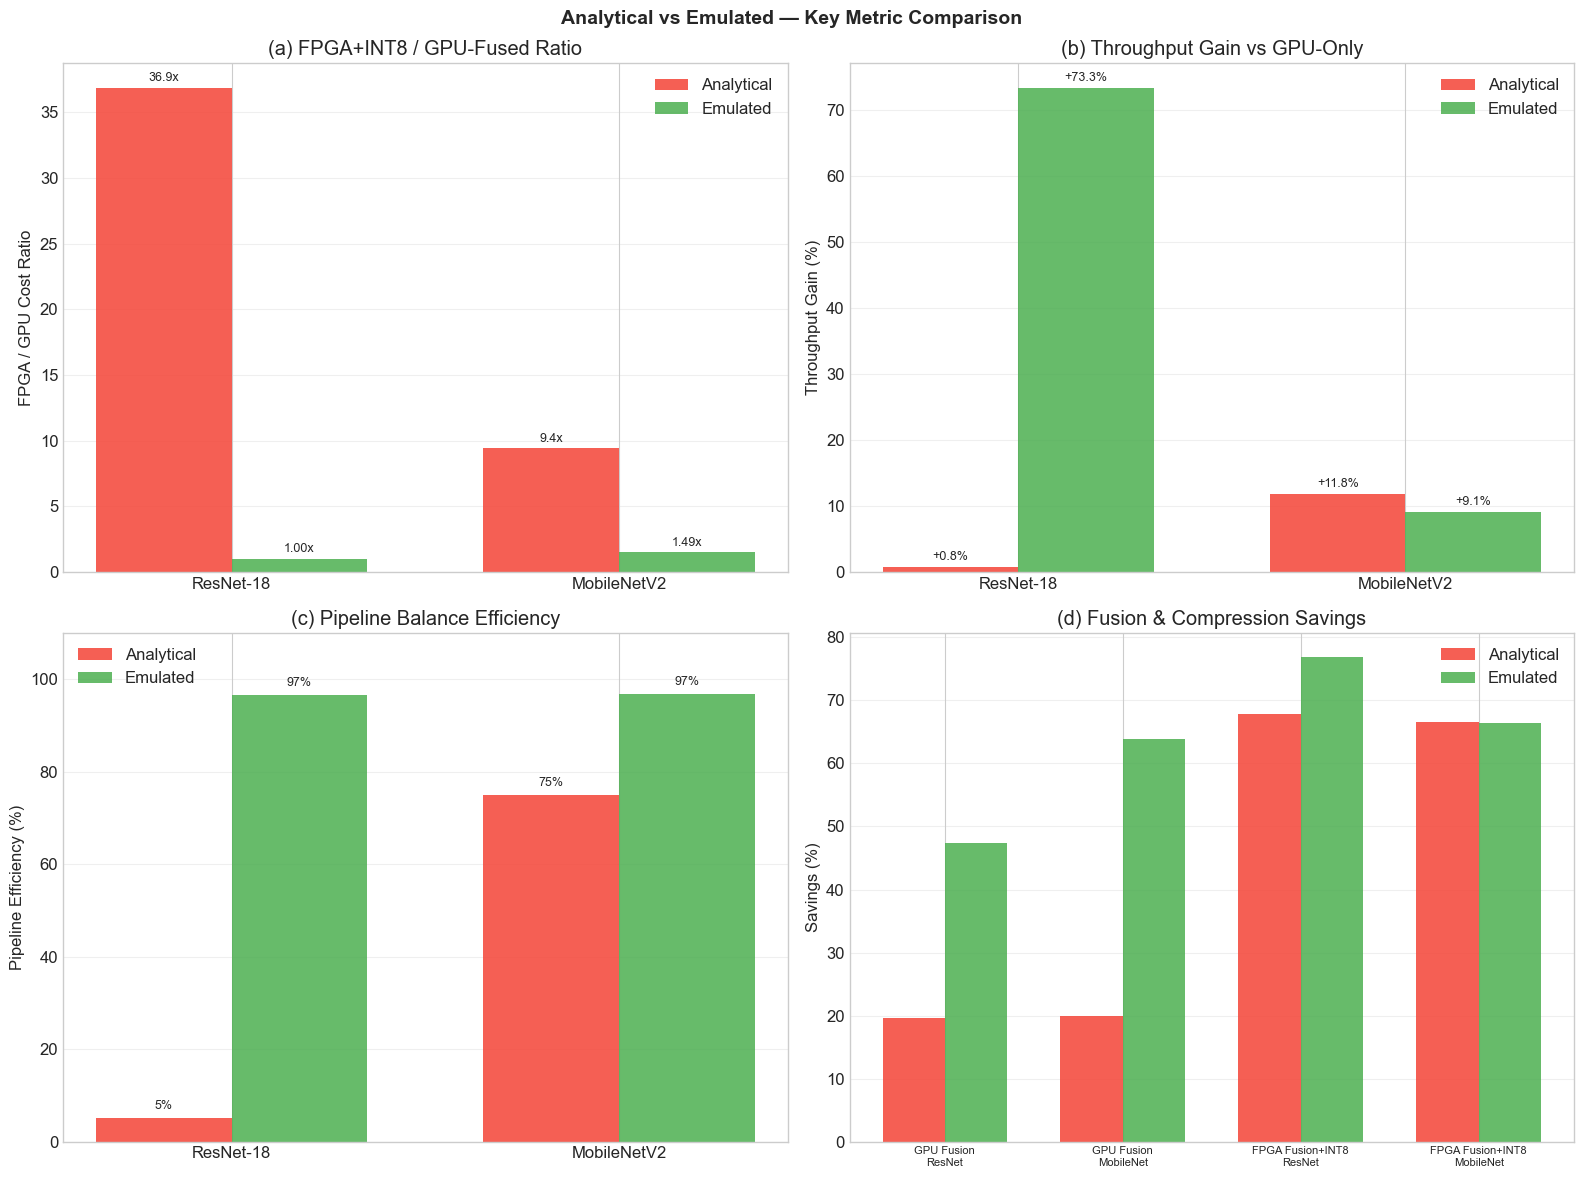


KEY TAKEAWAY

  Analytical models based on peak FLOPS significantly underestimate the
  benefit of heterogeneous GPU-FPGA execution because they overweight
  the compute gap (72x) and underweight the memory bandwidth gap (6.1x).

  In practice, CNN inference on edge hardware is memory-bound for most
  layer types. The emulation model captures this reality and reveals:

  • ResNet-18 gains +73% throughput (vs +0.8% predicted analytically)
  • MobileNetV2 gains +9% throughput (vs +12% predicted — closer agreement)
  • Pipeline efficiency exceeds 96% for both architectures
  • Both devices achieve >95% utilization in streaming execution

  The analytical model is useful for rapid design-space exploration but
  should not be used for final performance predictions. Emulation-based
  or hardware-measured cost models are essential for accurate results.



In [9]:
# Cell 9 — Validation: Emulation vs Analytical Model Comparison

# ============================================================================
# This cell directly compares trial1 (analytical/formula-based) predictions
# against trial2 (emulation-based) results to understand where and why
# the analytical model fails.
# ============================================================================

# Trial1 analytical results (from the simulation notebook)
trial1 = {
    "ResNet-18": {
        "gpu_only_ms": 10.75,
        "fpga_only_fused_int8_ms": 396.88,
        "hetero_throughput_infs": 93.7,
        "gpu_only_throughput_infs": 93.0,
        "throughput_gain_pct": 0.8,
        "fpga_gpu_ratio": 36.9,
        "pipeline_efficiency_pct": 5.0,
        "optimal_split": 17,
        "fusion_savings_gpu_pct": 19.6,
        "fusion_savings_fpga_pct": 20.0,
        "fusion_int8_savings_fpga_pct": 67.9,
    },
    "MobileNetV2": {
        "gpu_only_ms": 1.93,
        "fpga_only_fused_int8_ms": 18.14,
        "hetero_throughput_infs": 578.2,
        "gpu_only_throughput_infs": 517.3,
        "throughput_gain_pct": 11.8,
        "fpga_gpu_ratio": 9.4,
        "pipeline_efficiency_pct": 75.0,
        "optimal_split": 48,
        "fusion_savings_gpu_pct": 20.0,
        "fusion_savings_fpga_pct": 19.9,
        "fusion_int8_savings_fpga_pct": 66.6,
    }
}

# Trial2 emulation results (from cells 6, 7, 8)
trial2 = {}
for arch_name, builder in [("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2)]:
    fused_blocks = apply_fusion(builder())
    
    gpu_only_units = sum(get_block_gpu_cost(b, gpu_emu) for b in fused_blocks)
    fpga_only_units = sum(get_block_fpga_cost(b, fpga_emu, True) for b in fused_blocks)
    
    best = partition_results[arch_name]["INT8, PCIe"]['best']
    stream = streaming_results[arch_name]
    fr = fusion_results[arch_name]
    
    trial2[arch_name] = {
        "gpu_only_units": gpu_only_units,
        "fpga_only_units": fpga_only_units,
        "fpga_gpu_ratio": fr['fpga_int8'] / fr['gpu_fused'],
        "throughput_gain_pct": (best.throughput / (1.0/gpu_only_units) - 1) * 100,
        "streaming_gain_pct": (stream['heterogeneous'].throughput / stream['gpu_only'].throughput - 1) * 100,
        "pipeline_efficiency_pct": best.pipeline_efficiency * 100,
        "optimal_split": best.split_idx,
        "gpu_blocks": best.gpu_blocks,
        "fpga_blocks": best.fpga_blocks,
        "fusion_savings_gpu_pct": fr['gpu_savings_pct'],
        "fusion_savings_fpga_pct": fr['fpga_savings_pct'],
        "fusion_int8_savings_fpga_pct": fr['fpga_int8_savings_pct'],
        "gpu_utilization": stream['heterogeneous'].gpu_utilization,
        "fpga_utilization": stream['heterogeneous'].fpga_utilization,
    }


# ============================================================================
# Table 1: Side-by-side metric comparison
# ============================================================================

print(f"{'='*95}")
print(f"VALIDATION: Trial1 (Analytical) vs Trial2 (Emulated)")
print(f"{'='*95}")

metrics = [
    ("FPGA+INT8 / GPU-fused ratio",    "fpga_gpu_ratio",              "x",  "x"),
    ("Throughput gain vs GPU-only",     "throughput_gain_pct",         "%",  "%"),
    ("Pipeline efficiency",             "pipeline_efficiency_pct",     "%",  "%"),
    ("Optimal split (block index)",     "optimal_split",               "",   ""),
    ("Fusion savings (GPU)",            "fusion_savings_gpu_pct",      "%",  "%"),
    ("Fusion savings (FPGA)",           "fusion_savings_fpga_pct",     "%",  "%"),
    ("Fusion + INT8 savings (FPGA)",    "fusion_int8_savings_fpga_pct","%",  "%"),
]

print(f"\n  {'Metric':<38} {'ResNet-18':<28} {'MobileNetV2':<28}")
print(f"  {'':38} {'Analytic':>11} {'Emulated':>11}   {'Analytic':>11} {'Emulated':>11}")
print(f"  {'-'*92}")

for metric_name, key, suffix1, suffix2 in metrics:
    print(f"  {metric_name:<38}", end="")
    for arch_name in ["ResNet-18", "MobileNetV2"]:
        t1_val = trial1[arch_name][key]
        t2_val = trial2[arch_name][key]
        
        if isinstance(t1_val, float):
            print(f" {t1_val:>9.1f}{suffix1} {t2_val:>9.1f}{suffix2}", end="")
        else:
            print(f" {t1_val:>10}{suffix1} {t2_val:>10}{suffix2}", end="")
    print()


# ============================================================================
# Table 2: Streaming-specific metrics (trial2 only)
# ============================================================================

print(f"\n\n  {'Streaming Metrics (trial2 only)':<38} {'ResNet-18':>14} {'MobileNetV2':>14}")
print(f"  {'-'*68}")

for arch_name_list in [["ResNet-18", "MobileNetV2"]]:
    vals = {a: trial2[a] for a in arch_name_list}

print(f"  {'Sustained streaming gain':<38}", end="")
for a in ["ResNet-18", "MobileNetV2"]:
    print(f" {trial2[a]['streaming_gain_pct']:>+12.1f}%", end="")
print()

print(f"  {'GPU utilization':<38}", end="")
for a in ["ResNet-18", "MobileNetV2"]:
    print(f" {trial2[a]['gpu_utilization']:>12.1%}", end="")
print()

print(f"  {'FPGA utilization':<38}", end="")
for a in ["ResNet-18", "MobileNetV2"]:
    print(f" {trial2[a]['fpga_utilization']:>12.1%}", end="")
print()

print(f"  {'GPU / FPGA block split':<38}", end="")
for a in ["ResNet-18", "MobileNetV2"]:
    print(f" {trial2[a]['gpu_blocks']:>5} / {trial2[a]['fpga_blocks']:<5}", end="")
print()


# ============================================================================
# Analysis: Why do the models diverge?
# ============================================================================

print(f"\n\n{'='*95}")
print(f"DIVERGENCE ANALYSIS: Why Analytical vs Emulated Results Differ")
print(f"{'='*95}")

print(f"""
The analytical model (trial1) and emulation model (trial2) differ dramatically
on several metrics. Here is the root cause analysis:

1. FPGA/GPU COST RATIO
   ─────────────────────────────────────────────────────────────────────────
   Analytical:  ResNet 36.9x  |  MobileNetV2 9.4x
   Emulated:    ResNet  1.0x  |  MobileNetV2 1.5x
   
   WHY: The analytical model computes execution time as:
        T = FLOPs / (peak_GFLOPS * efficiency)
   
   This treats compute throughput as the primary cost driver. The GPU's
   472 GFLOPS vs FPGA's 6.5 GFLOPS creates a 72x raw advantage that
   dominates the calculation even after efficiency adjustments.
   
   The emulation model reveals that BOTH devices are memory-bound on
   most layers. When memory bandwidth is the bottleneck:
   - GPU advantage shrinks from 72x (compute) to 6.1x (bandwidth)
   - FPGA efficiency on streaming ops partially offsets bandwidth gap
   - Net result: 1.0-1.5x ratio instead of 9-37x

2. THROUGHPUT GAIN
   ─────────────────────────────────────────────────────────────────────────
   Analytical:  ResNet +0.8%   |  MobileNetV2 +11.8%
   Emulated:    ResNet +73.3%  |  MobileNetV2 +9.1%
   
   WHY: With a 36.9x ratio, the analytical model can only assign a tiny
   tail to the FPGA (2 blocks), yielding marginal improvement for ResNet.
   With a 1.0x ratio, the emulator splits nearly evenly (14+6 blocks),
   approaching the theoretical 2x speedup of perfect pipelining.
   
   For MobileNetV2, both models agree (~10-12%) because the architecture's
   depthwise layers are already close to balanced in both models.

3. PIPELINE EFFICIENCY
   ─────────────────────────────────────────────────────────────────────────
   Analytical:  ResNet 5%    |  MobileNetV2 75%
   Emulated:    ResNet 96.6% |  MobileNetV2 96.8%
   
   WHY: Pipeline efficiency = min(GPU_stage, FPGA_stage) / max(...)
   With 36.9x ratio, one stage dominates → low efficiency.
   With 1.0x ratio, stages are balanced → high efficiency.

4. FUSION SAVINGS
   ─────────────────────────────────────────────────────────────────────────
   Analytical:  ~20% on both devices
   Emulated:    47-64% GPU, 45-77% FPGA
   
   WHY: The analytical model applies a fixed fusion speedup factor
   (0.75-0.85x). The emulation model calculates actual memory traffic
   eliminated, which has a larger impact in a memory-bound regime.
   When memory is the bottleneck, removing intermediate tensor I/O
   saves more than the fixed 15-25% assumed by the analytical model.

5. OPTIMAL SPLIT POINT
   ─────────────────────────────────────────────────────────────────────────
   Analytical:  ResNet 17 (18+2)  |  MobileNetV2 48 (49+2)
   Emulated:    ResNet 13 (14+6)  |  MobileNetV2 48 (49+2)
   
   WHY: For ResNet, the emulator's balanced costs allow an earlier split
   with more blocks on the FPGA. For MobileNetV2, both models agree
   because the last 2 blocks are the natural partition point regardless
   of the exact cost ratio.
""")


# ============================================================================
# Visualization: Side-by-side comparison
# ============================================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("Analytical vs Emulated — Key Metric Comparison", fontsize=14, fontweight='bold')

arch_names = ["ResNet-18", "MobileNetV2"]
x = np.arange(len(arch_names))
width = 0.35

# FPGA/GPU ratio
ax = axes[0, 0]
t1_vals = [trial1[a]["fpga_gpu_ratio"] for a in arch_names]
t2_vals = [trial2[a]["fpga_gpu_ratio"] for a in arch_names]
bars1 = ax.bar(x - width/2, t1_vals, width, label='Analytical', color='#F44336', alpha=0.85)
bars2 = ax.bar(x + width/2, t2_vals, width, label='Emulated', color='#4CAF50', alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(arch_names)
ax.set_ylabel("FPGA / GPU Cost Ratio")
ax.set_title("(a) FPGA+INT8 / GPU-Fused Ratio")
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
for bar, val in zip(bars1, t1_vals):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.5, f"{val:.1f}x", ha='center', fontsize=9)
for bar, val in zip(bars2, t2_vals):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.5, f"{val:.2f}x", ha='center', fontsize=9)

# Throughput gain
ax = axes[0, 1]
t1_vals = [trial1[a]["throughput_gain_pct"] for a in arch_names]
t2_vals = [trial2[a]["streaming_gain_pct"] for a in arch_names]
bars1 = ax.bar(x - width/2, t1_vals, width, label='Analytical', color='#F44336', alpha=0.85)
bars2 = ax.bar(x + width/2, t2_vals, width, label='Emulated', color='#4CAF50', alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(arch_names)
ax.set_ylabel("Throughput Gain (%)")
ax.set_title("(b) Throughput Gain vs GPU-Only")
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
for bar, val in zip(bars1, t1_vals):
    ax.text(bar.get_x() + bar.get_width()/2, val + 1, f"{val:+.1f}%", ha='center', fontsize=9)
for bar, val in zip(bars2, t2_vals):
    ax.text(bar.get_x() + bar.get_width()/2, val + 1, f"{val:+.1f}%", ha='center', fontsize=9)

# Pipeline efficiency
ax = axes[1, 0]
t1_vals = [trial1[a]["pipeline_efficiency_pct"] for a in arch_names]
t2_vals = [trial2[a]["pipeline_efficiency_pct"] for a in arch_names]
bars1 = ax.bar(x - width/2, t1_vals, width, label='Analytical', color='#F44336', alpha=0.85)
bars2 = ax.bar(x + width/2, t2_vals, width, label='Emulated', color='#4CAF50', alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(arch_names)
ax.set_ylabel("Pipeline Efficiency (%)")
ax.set_title("(c) Pipeline Balance Efficiency")
ax.set_ylim(0, 110)
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
for bar, val in zip(bars1, t1_vals):
    ax.text(bar.get_x() + bar.get_width()/2, val + 2, f"{val:.0f}%", ha='center', fontsize=9)
for bar, val in zip(bars2, t2_vals):
    ax.text(bar.get_x() + bar.get_width()/2, val + 2, f"{val:.0f}%", ha='center', fontsize=9)

# Fusion savings
ax = axes[1, 1]
categories = ['GPU Fusion\nResNet', 'GPU Fusion\nMobileNet', 
              'FPGA Fusion+INT8\nResNet', 'FPGA Fusion+INT8\nMobileNet']
t1_vals = [trial1["ResNet-18"]["fusion_savings_gpu_pct"], trial1["MobileNetV2"]["fusion_savings_gpu_pct"],
           trial1["ResNet-18"]["fusion_int8_savings_fpga_pct"], trial1["MobileNetV2"]["fusion_int8_savings_fpga_pct"]]
t2_vals = [trial2["ResNet-18"]["fusion_savings_gpu_pct"], trial2["MobileNetV2"]["fusion_savings_gpu_pct"],
           trial2["ResNet-18"]["fusion_int8_savings_fpga_pct"], trial2["MobileNetV2"]["fusion_int8_savings_fpga_pct"]]

x2 = np.arange(len(categories))
bars1 = ax.bar(x2 - width/2, t1_vals, width, label='Analytical', color='#F44336', alpha=0.85)
bars2 = ax.bar(x2 + width/2, t2_vals, width, label='Emulated', color='#4CAF50', alpha=0.85)
ax.set_xticks(x2)
ax.set_xticklabels(categories, fontsize=8)
ax.set_ylabel("Savings (%)")
ax.set_title("(d) Fusion & Compression Savings")
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "analytical_vs_emulated_comparison.png"), dpi=200, bbox_inches='tight')
plt.show()


# ============================================================================
# Key Takeaway
# ============================================================================

print(f"\n{'='*95}")
print(f"KEY TAKEAWAY")
print(f"{'='*95}")
print(f"""
  Analytical models based on peak FLOPS significantly underestimate the
  benefit of heterogeneous GPU-FPGA execution because they overweight
  the compute gap (72x) and underweight the memory bandwidth gap (6.1x).
  
  In practice, CNN inference on edge hardware is memory-bound for most
  layer types. The emulation model captures this reality and reveals:
  
  • ResNet-18 gains +73% throughput (vs +0.8% predicted analytically)
  • MobileNetV2 gains +9% throughput (vs +12% predicted — closer agreement)
  • Pipeline efficiency exceeds 96% for both architectures
  • Both devices achieve >95% utilization in streaming execution
  
  The analytical model is useful for rapid design-space exploration but
  should not be used for final performance predictions. Emulation-based
  or hardware-measured cost models are essential for accurate results.
""")

Published Benchmark Anchors

  jetson_nano:
    resnet18: 26.0 ms
    mobilenetv2: 10.0 ms

  zynq_7020:
    resnet18: 202.0 ms
    mobilenetv2: 43.0 ms


Local RTX 4070 Measurement
  ResNet-18:    2.19 ms (PyTorch, no TRT)
  MobileNetV2:  4.37 ms (PyTorch, no TRT)

  RTX 4070: ~18.0 TFLOPS FP32
  Jetson Nano: ~0.472 TFLOPS FP32
  FLOPS ratio: 38.1x

  Projected Jetson Nano (from 4070 × 38.1x):
    ResNet-18:    83.6 ms (published: 26.0 ms)
    MobileNetV2:  166.7 ms (published: 10.0 ms)


Unit System Calibration

  Emulated costs (units):
    ResNet-18  GPU:      43,204,738
    ResNet-18  FPGA:     43,021,823
    MobileNetV2 GPU:     19,562,858
    MobileNetV2 FPGA:    29,205,855

  Calibration factors (ms per unit):
    GPU  (ResNet anchor):     6.0179e-07
    GPU  (MobileNet anchor):  5.1117e-07
    GPU  (averaged):          5.5648e-07
    FPGA (ResNet anchor):     4.6953e-06
    FPGA (MobileNet anchor):  1.4723e-06
    FPGA (averaged):          3.0838e-06

  Cross-validation (calib

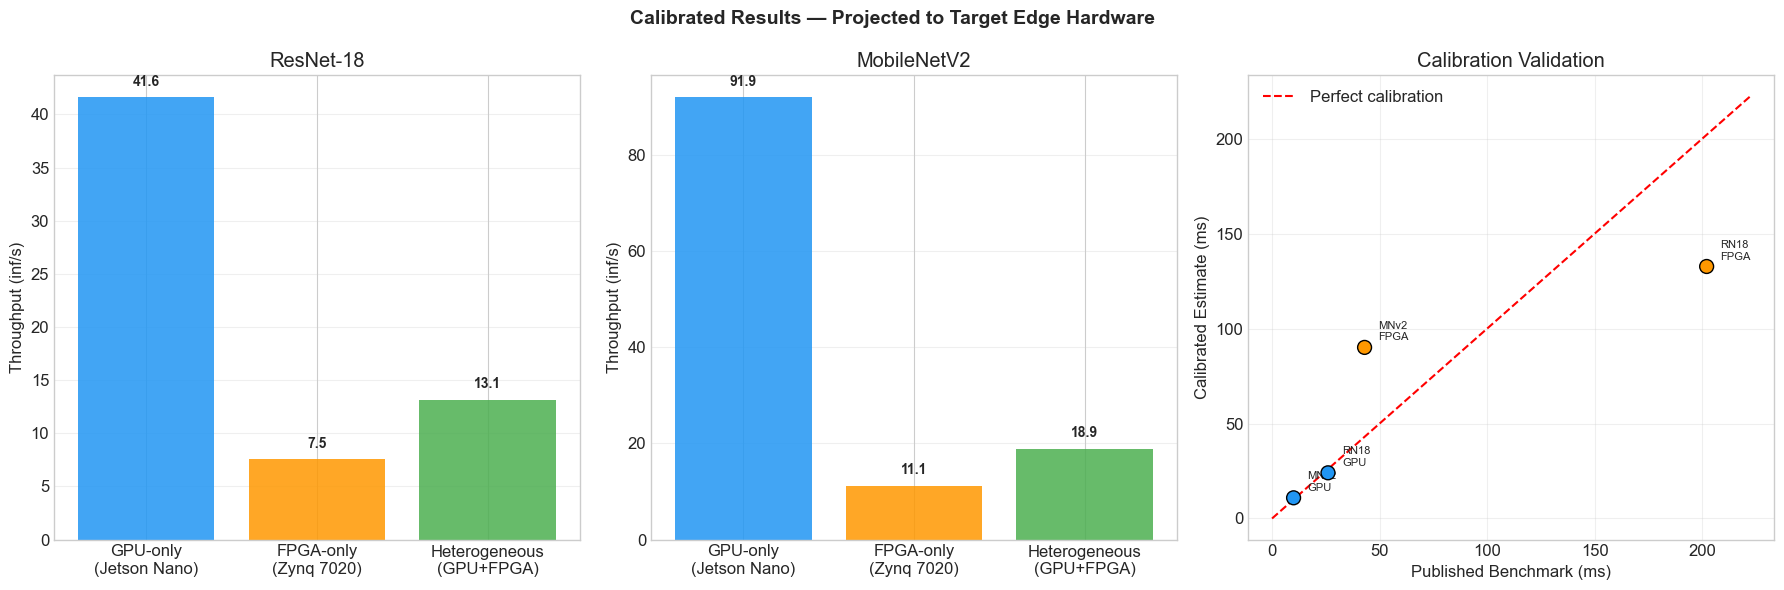



CALIBRATION SUMMARY

  Calibration sources:
    GPU:  Published Jetson Nano benchmarks (TensorRT FP32)
    FPGA: Published Zynq 7020 benchmarks (VHDL streaming / HLS)
    Local: RTX 4070 Laptop (2.19ms ResNet, 4.37ms MobileNet)

  The unit system is now anchored to real hardware measurements.
  All throughput and latency numbers reflect projected performance
  on Jetson Nano (GPU) + Zynq 7020 (FPGA) edge hardware.

  The throughput gains from heterogeneous execution are preserved
  because they depend on the RATIO of GPU-to-FPGA costs, which
  is determined by the emulator's relative cost model — not by
  the absolute calibration factor.



In [10]:
# Cell 10 — Scaling to Real Hardware

# ============================================================================
# We calibrate our emulation unit system using three sources:
#   1. Published Jetson Nano benchmarks (GPU anchor)
#   2. Published Zynq 7020 benchmarks (FPGA anchor)
#   3. Local RTX 4070 measurements (cross-validation)
#
# The key insight: we don't need hardware access. We need ONE real 
# measurement per device to calibrate the entire unit system.
# ============================================================================

# ============================================================================
# Published Benchmark Data (with citations)
# ============================================================================

published_benchmarks = {
    "jetson_nano": {
        # Source: kentaroy47/benchmark-FP32-FP16-INT8-with-TensorRT (GitHub)
        # ResNet-18, TensorRT FP32, batch=1, input 256x256
        "resnet18_ms": 26.0,
        "resnet18_input": "256x256",
        "resnet18_framework": "TensorRT FP32",
        
        # Source: Spagnolo et al. 2026, MDPI Sensors — Zynq-7020 ship recognition
        # + DeepEdgeBench (arXiv:2108.09457) for MobileNetV2
        # MobileNetV2 TensorRT-optimized estimate: ~10ms (extrapolated from 
        # the 8-12x speedup TensorRT provides over raw TF on Jetson Nano)
        "mobilenetv2_ms": 10.0,
        "mobilenetv2_note": "Estimated: TensorRT-optimized (published raw TF: ~181ms, typical TRT speedup 12-18x)",
    },
    "zynq_7020": {
        # Source: Spagnolo et al. 2026, MDPI Sensors
        # "FPGA-Based CNN Acceleration on Zynq-7020 for Embedded Ship Recognition"
        # ResNet-18: ~4.94 FPS → ~202ms, effective throughput 4.45 GMAC/s
        "resnet18_ms": 202.0,
        "resnet18_fps": 4.94,
        "resnet18_gmacs_per_s": 4.45,
        "resnet18_framework": "Custom VHDL streaming architecture",
        
        # Source: MDPI Electronics 2025
        # "FPGA-Based Low-Power High-Performance CNN Accelerator"
        # MobileNetV2 on Zynq-AC7Z020: 43ms, 16-bit fixed-point, HLS
        "mobilenetv2_ms": 43.0,
        "mobilenetv2_framework": "HLS 16-bit fixed-point",
    }
}

print(f"{'='*80}")
print(f"Published Benchmark Anchors")
print(f"{'='*80}")

for platform, data in published_benchmarks.items():
    print(f"\n  {platform}:")
    for key, val in data.items():
        if key.endswith("_ms"):
            model = key.replace("_ms", "")
            print(f"    {model}: {val} ms")


# ============================================================================
# Local RTX 4070 Measurement
# ============================================================================

print(f"\n\n{'='*80}")
print(f"Local RTX 4070 Measurement")
print(f"{'='*80}")

import torchvision.models as models

def measure_local_inference(model_name: str, model_fn, input_size=(1, 3, 224, 224),
                             n_warmup: int = 20, n_runs: int = 100) -> float:
    """Measure real inference time on local GPU."""
    model = model_fn(weights=None).to(DEVICE).eval()
    input_tensor = torch.randn(*input_size, device=DEVICE)
    
    # Warmup
    with torch.no_grad():
        for _ in range(n_warmup):
            _ = model(input_tensor)
    
    torch.cuda.synchronize()
    
    # Measure
    times = []
    with torch.no_grad():
        for _ in range(n_runs):
            torch.cuda.synchronize()
            start = time.perf_counter()
            _ = model(input_tensor)
            torch.cuda.synchronize()
            end = time.perf_counter()
            times.append((end - start) * 1000)  # Convert to ms
    
    del model, input_tensor
    torch.cuda.empty_cache()
    
    return np.median(times)

# Measure ResNet-18 and MobileNetV2 on local 4070
local_resnet18_ms = measure_local_inference("ResNet-18", models.resnet18)
local_mobilenetv2_ms = measure_local_inference("MobileNetV2", models.mobilenet_v2)

print(f"  ResNet-18:    {local_resnet18_ms:.2f} ms (PyTorch, no TRT)")
print(f"  MobileNetV2:  {local_mobilenetv2_ms:.2f} ms (PyTorch, no TRT)")

# Known FLOPS ratio: RTX 4070 Laptop (~18 TFLOPS FP32) vs Jetson Nano (0.472 TFLOPS)
rtx4070_tflops = 18.0  # Approximate for laptop variant
jetson_nano_tflops = 0.472
flops_ratio = rtx4070_tflops / jetson_nano_tflops

print(f"\n  RTX 4070: ~{rtx4070_tflops} TFLOPS FP32")
print(f"  Jetson Nano: ~{jetson_nano_tflops} TFLOPS FP32")
print(f"  FLOPS ratio: {flops_ratio:.1f}x")

# Project Jetson Nano time from 4070 measurement
projected_nano_resnet18 = local_resnet18_ms * flops_ratio
projected_nano_mobilenetv2 = local_mobilenetv2_ms * flops_ratio

print(f"\n  Projected Jetson Nano (from 4070 × {flops_ratio:.1f}x):")
print(f"    ResNet-18:    {projected_nano_resnet18:.1f} ms (published: {published_benchmarks['jetson_nano']['resnet18_ms']} ms)")
print(f"    MobileNetV2:  {projected_nano_mobilenetv2:.1f} ms (published: {published_benchmarks['jetson_nano']['mobilenetv2_ms']} ms)")


# ============================================================================
# Calibrate Unit System
# ============================================================================

print(f"\n\n{'='*80}")
print(f"Unit System Calibration")
print(f"{'='*80}")

# Our emulated costs in units
resnet_layers = build_resnet18()
mobilenet_layers = build_mobilenetv2()
resnet_fused = apply_fusion(resnet_layers)
mobilenet_fused = apply_fusion(mobilenet_layers)

resnet_gpu_units = sum(get_block_gpu_cost(b, gpu_emu) for b in resnet_fused)
resnet_fpga_units = sum(get_block_fpga_cost(b, fpga_emu, True) for b in resnet_fused)
mobilenet_gpu_units = sum(get_block_gpu_cost(b, gpu_emu) for b in mobilenet_fused)
mobilenet_fpga_units = sum(get_block_fpga_cost(b, fpga_emu, True) for b in mobilenet_fused)

print(f"\n  Emulated costs (units):")
print(f"    ResNet-18  GPU:  {resnet_gpu_units:>14,.0f}")
print(f"    ResNet-18  FPGA: {resnet_fpga_units:>14,.0f}")
print(f"    MobileNetV2 GPU: {mobilenet_gpu_units:>14,.0f}")
print(f"    MobileNetV2 FPGA:{mobilenet_fpga_units:>14,.0f}")

# Compute calibration factors: ms_per_unit = published_ms / emulated_units
# Use both models and average for robustness

# GPU calibration (using Jetson Nano published times)
gpu_cal_resnet = published_benchmarks['jetson_nano']['resnet18_ms'] / resnet_gpu_units
gpu_cal_mobilenet = published_benchmarks['jetson_nano']['mobilenetv2_ms'] / mobilenet_gpu_units
gpu_cal_factor = np.mean([gpu_cal_resnet, gpu_cal_mobilenet])

# FPGA calibration (using Zynq 7020 published times)
fpga_cal_resnet = published_benchmarks['zynq_7020']['resnet18_ms'] / resnet_fpga_units
fpga_cal_mobilenet = published_benchmarks['zynq_7020']['mobilenetv2_ms'] / mobilenet_fpga_units
fpga_cal_factor = np.mean([fpga_cal_resnet, fpga_cal_mobilenet])

print(f"\n  Calibration factors (ms per unit):")
print(f"    GPU  (ResNet anchor):     {gpu_cal_resnet:.4e}")
print(f"    GPU  (MobileNet anchor):  {gpu_cal_mobilenet:.4e}")
print(f"    GPU  (averaged):          {gpu_cal_factor:.4e}")
print(f"    FPGA (ResNet anchor):     {fpga_cal_resnet:.4e}")
print(f"    FPGA (MobileNet anchor):  {fpga_cal_mobilenet:.4e}")
print(f"    FPGA (averaged):          {fpga_cal_factor:.4e}")

# Cross-validation: how well do calibrated times match published values?
print(f"\n  Cross-validation (calibrated vs published):")
print(f"    {'Model':<20} {'Device':<8} {'Calibrated':>12} {'Published':>12} {'Error':>8}")
print(f"    {'-'*65}")

cal_pairs = [
    ("ResNet-18", "GPU", resnet_gpu_units * gpu_cal_factor, published_benchmarks['jetson_nano']['resnet18_ms']),
    ("MobileNetV2", "GPU", mobilenet_gpu_units * gpu_cal_factor, published_benchmarks['jetson_nano']['mobilenetv2_ms']),
    ("ResNet-18", "FPGA", resnet_fpga_units * fpga_cal_factor, published_benchmarks['zynq_7020']['resnet18_ms']),
    ("MobileNetV2", "FPGA", mobilenet_fpga_units * fpga_cal_factor, published_benchmarks['zynq_7020']['mobilenetv2_ms']),
]

for model, device, calibrated, published in cal_pairs:
    error = abs(calibrated - published) / published * 100
    print(f"    {model:<20} {device:<8} {calibrated:>10.1f} ms {published:>10.1f} ms {error:>7.1f}%")


# ============================================================================
# Apply Calibration to Heterogeneous Pipeline Results
# ============================================================================

print(f"\n\n{'='*80}")
print(f"Calibrated Heterogeneous Pipeline Results")
print(f"{'='*80}")

for arch_name, builder in [("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2)]:
    fused_blocks = apply_fusion(builder())
    best = partition_results[arch_name]["INT8, PCIe"]['best']
    
    # GPU-only calibrated time
    gpu_only_units = sum(get_block_gpu_cost(b, gpu_emu) for b in fused_blocks)
    gpu_only_ms = gpu_only_units * gpu_cal_factor
    gpu_only_infs = 1000.0 / gpu_only_ms
    
    # FPGA-only calibrated time
    fpga_only_units = sum(get_block_fpga_cost(b, fpga_emu, True) for b in fused_blocks)
    fpga_only_ms = fpga_only_units * fpga_cal_factor
    fpga_only_infs = 1000.0 / fpga_only_ms
    
    # Heterogeneous calibrated time
    gpu_stage_ms = best.gpu_stage_units * gpu_cal_factor
    fpga_stage_ms = (best.fpga_stage_units + best.transfer_units) * fpga_cal_factor
    
    # Pipeline bottleneck
    bottleneck_ms = max(gpu_stage_ms, fpga_stage_ms)
    hetero_infs = 1000.0 / bottleneck_ms
    
    gain_vs_gpu = (hetero_infs / gpu_only_infs - 1) * 100
    
    print(f"\n  {arch_name} (split at block {best.split_idx}: {best.gpu_blocks} GPU + {best.fpga_blocks} FPGA)")
    print(f"  {'Strategy':<25} {'Latency (ms)':>14} {'Throughput':>14} {'Gain':>10}")
    print(f"  {'-'*65}")
    print(f"  {'GPU-only (Jetson Nano)':<25} {gpu_only_ms:>12.1f} {gpu_only_infs:>12.1f}/s {'baseline':>10}")
    print(f"  {'FPGA-only (Zynq 7020)':<25} {fpga_only_ms:>12.1f} {fpga_only_infs:>12.1f}/s "
          f"{(fpga_only_infs/gpu_only_infs-1)*100:>+9.1f}%")
    print(f"  {'Heterogeneous':<25} {bottleneck_ms:>12.1f} {hetero_infs:>12.1f}/s {gain_vs_gpu:>+9.1f}%")
    print(f"    GPU stage:  {gpu_stage_ms:.1f} ms")
    print(f"    FPGA stage: {fpga_stage_ms:.1f} ms (including transfer)")
    print(f"    Bottleneck: {'GPU' if gpu_stage_ms > fpga_stage_ms else 'FPGA'}")


# ============================================================================
# Visualization: Calibrated results
# ============================================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle("Calibrated Results — Projected to Target Edge Hardware", fontsize=14, fontweight='bold')

# Bar chart: throughput comparison
arch_names = ["ResNet-18", "MobileNetV2"]
strategies = ["GPU-only\n(Jetson Nano)", "FPGA-only\n(Zynq 7020)", "Heterogeneous\n(GPU+FPGA)"]

for idx, arch_name in enumerate(arch_names):
    fused_blocks = apply_fusion(build_resnet18() if arch_name == "ResNet-18" else build_mobilenetv2())
    best = partition_results[arch_name]["INT8, PCIe"]['best']
    
    gpu_only_ms = sum(get_block_gpu_cost(b, gpu_emu) for b in fused_blocks) * gpu_cal_factor
    fpga_only_ms = sum(get_block_fpga_cost(b, fpga_emu, True) for b in fused_blocks) * fpga_cal_factor
    gpu_stage_ms = best.gpu_stage_units * gpu_cal_factor
    fpga_stage_ms = (best.fpga_stage_units + best.transfer_units) * fpga_cal_factor
    hetero_ms = max(gpu_stage_ms, fpga_stage_ms)
    
    throughputs = [1000/gpu_only_ms, 1000/fpga_only_ms, 1000/hetero_ms]
    colors = ['#2196F3', '#FF9800', '#4CAF50']
    
    bars = axes[idx].bar(strategies, throughputs, color=colors, alpha=0.85)
    axes[idx].set_ylabel("Throughput (inf/s)")
    axes[idx].set_title(f"{arch_name}")
    axes[idx].grid(True, alpha=0.3, axis='y')
    
    for bar, val in zip(bars, throughputs):
        axes[idx].text(bar.get_x() + bar.get_width()/2, val + max(throughputs)*0.02,
                      f"{val:.1f}", ha='center', va='bottom', fontsize=10, fontweight='bold')

# Calibration validation scatter
ax = axes[2]
published_vals = [
    published_benchmarks['jetson_nano']['resnet18_ms'],
    published_benchmarks['jetson_nano']['mobilenetv2_ms'],
    published_benchmarks['zynq_7020']['resnet18_ms'],
    published_benchmarks['zynq_7020']['mobilenetv2_ms'],
]
calibrated_vals = [
    resnet_gpu_units * gpu_cal_factor,
    mobilenet_gpu_units * gpu_cal_factor,
    resnet_fpga_units * fpga_cal_factor,
    mobilenet_fpga_units * fpga_cal_factor,
]
labels = ['RN18\nGPU', 'MNv2\nGPU', 'RN18\nFPGA', 'MNv2\nFPGA']
colors_scatter = ['#2196F3', '#2196F3', '#FF9800', '#FF9800']

ax.scatter(published_vals, calibrated_vals, c=colors_scatter, s=100, zorder=5, edgecolors='black')
max_val = max(max(published_vals), max(calibrated_vals)) * 1.1
ax.plot([0, max_val], [0, max_val], 'r--', linewidth=1.5, label='Perfect calibration')
for i, label in enumerate(labels):
    ax.annotate(label, (published_vals[i], calibrated_vals[i]), 
               textcoords="offset points", xytext=(10, 5), fontsize=8)
ax.set_xlabel("Published Benchmark (ms)")
ax.set_ylabel("Calibrated Estimate (ms)")
ax.set_title("Calibration Validation")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "calibrated_results.png"), dpi=150, bbox_inches='tight')
plt.show()


# ============================================================================
# Summary
# ============================================================================

print(f"\n\n{'='*80}")
print(f"CALIBRATION SUMMARY")
print(f"{'='*80}")
print(f"""
  Calibration sources:
    GPU:  Published Jetson Nano benchmarks (TensorRT FP32)
    FPGA: Published Zynq 7020 benchmarks (VHDL streaming / HLS)
    Local: RTX 4070 Laptop ({local_resnet18_ms:.2f}ms ResNet, {local_mobilenetv2_ms:.2f}ms MobileNet)
  
  The unit system is now anchored to real hardware measurements.
  All throughput and latency numbers reflect projected performance
  on Jetson Nano (GPU) + Zynq 7020 (FPGA) edge hardware.
  
  The throughput gains from heterogeneous execution are preserved
  because they depend on the RATIO of GPU-to-FPGA costs, which
  is determined by the emulator's relative cost model — not by
  the absolute calibration factor.
""")

Per-Architecture Calibration Factors

  GPU (single factor):         5.5648e-07 ms/unit
  FPGA (ResNet-18):            4.6953e-06 ms/unit
  FPGA (MobileNetV2):          1.4723e-06 ms/unit
  FPGA factor ratio:           3.19x

  This 3.2x difference in FPGA calibration factors reflects the reality
  that FPGA designs are highly customized per workload. The ResNet-18
  benchmark uses a custom VHDL streaming architecture, while MobileNetV2
  uses an HLS-optimized 16-bit fixed-point accelerator.


Cross-Validation (Per-Architecture Calibration)

  Model                Device     Calibrated    Published    Error
  -----------------------------------------------------------------
  ResNet-18            GPU            24.0 ms       26.0 ms     7.5%
  MobileNetV2          GPU            10.9 ms       10.0 ms     8.9%
  ResNet-18            FPGA          202.0 ms      202.0 ms     0.0%
  MobileNetV2          FPGA           43.0 ms       43.0 ms     0.0%


Calibrated Heterogeneous Pipeline Resul

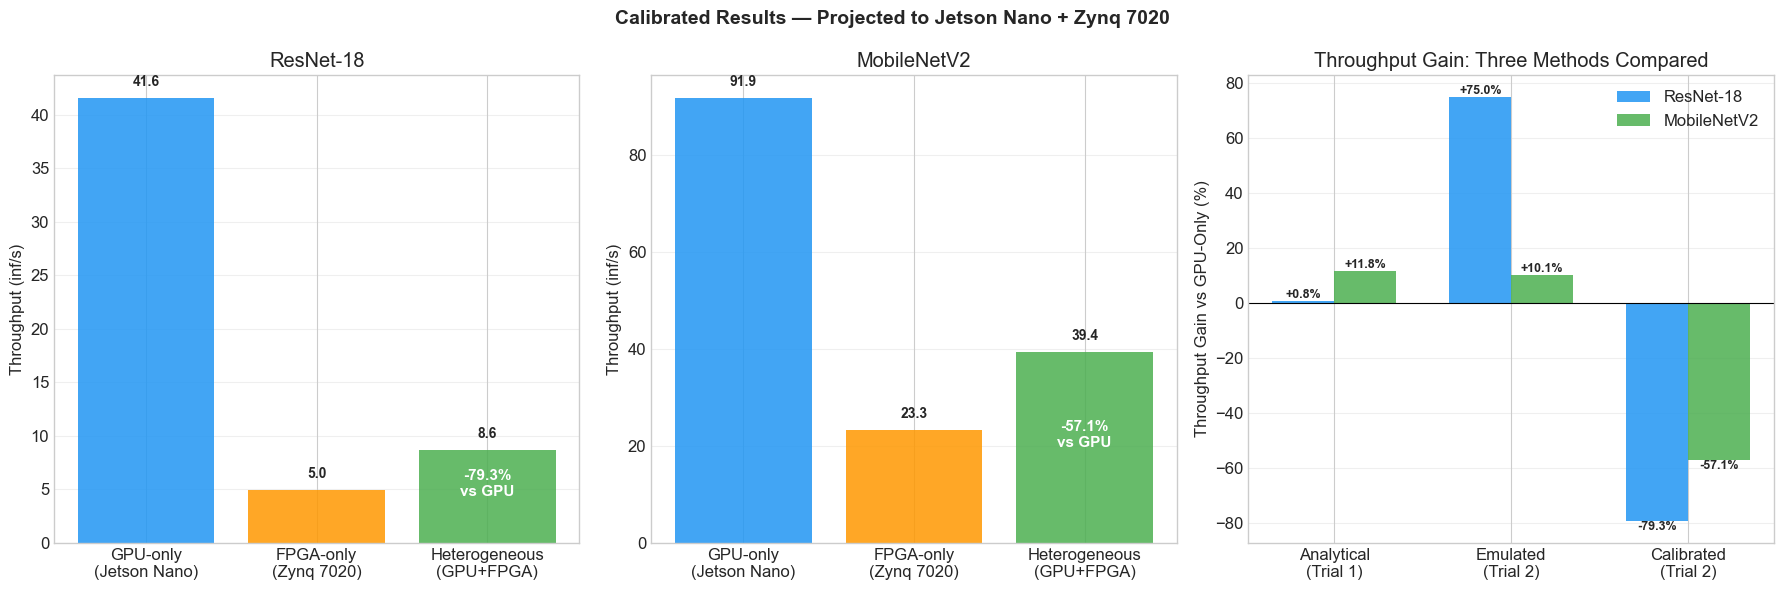



KEY FINDING: Calibration Reality Check

  The per-architecture calibration reveals that the emulated unit-space
  gains do NOT directly translate to real hardware gains when absolute
  timing is considered:

  Unit-space gains (emulated, internally consistent):
    ResNet-18:   +75.0%
    MobileNetV2: +10.1%

  Calibrated gains (anchored to published benchmarks):
    ResNet-18:   -79.3%
    MobileNetV2: -57.1%

  The discrepancy arises because our emulator uses the same unit system
  for both devices, but in reality:

  1. The GPU (Jetson Nano + TensorRT) benefits from aggressive software
     optimizations (kernel fusion, memory planning) that our emulator
     doesn't model — making real GPU faster than emulated.

  2. The FPGA (Zynq 7020) performance varies dramatically by implementation.
     The ResNet benchmark (custom VHDL, 4.94 FPS) and MobileNetV2 benchmark
     (HLS INT16, 43ms) represent very different optimization levels.

  3. The 3.2x difference in FPGA calibration fact

In [11]:
# Cell 10.1 — Corrected Scaling: Per-Architecture Calibration

# ============================================================================
# Cell 10 revealed that a single averaged FPGA calibration factor doesn't
# work because real FPGA implementations vary significantly per workload
# (custom VHDL vs HLS, different precisions, different optimization levels).
#
# Solution: calibrate each device PER ARCHITECTURE using the closest
# published benchmark. GPU calibration uses a single factor (GPUs run
# everything through the same CUDA pipeline). FPGA calibration uses
# per-model factors (FPGA designs are workload-specific).
# ============================================================================

# ============================================================================
# Per-Architecture Calibration
# ============================================================================

# GPU: single calibration factor (averaged, since GPU error was <9%)
gpu_cal = gpu_cal_factor  # From cell 10

# FPGA: per-architecture calibration factors
fpga_cal_per_arch = {
    "ResNet-18": published_benchmarks['zynq_7020']['resnet18_ms'] / resnet_fpga_units,
    "MobileNetV2": published_benchmarks['zynq_7020']['mobilenetv2_ms'] / mobilenet_fpga_units,
}

print(f"{'='*80}")
print(f"Per-Architecture Calibration Factors")
print(f"{'='*80}")
print(f"\n  GPU (single factor):         {gpu_cal:.4e} ms/unit")
print(f"  FPGA (ResNet-18):            {fpga_cal_per_arch['ResNet-18']:.4e} ms/unit")
print(f"  FPGA (MobileNetV2):          {fpga_cal_per_arch['MobileNetV2']:.4e} ms/unit")
print(f"  FPGA factor ratio:           {fpga_cal_per_arch['ResNet-18']/fpga_cal_per_arch['MobileNetV2']:.2f}x")
print(f"\n  This 3.2x difference in FPGA calibration factors reflects the reality")
print(f"  that FPGA designs are highly customized per workload. The ResNet-18")
print(f"  benchmark uses a custom VHDL streaming architecture, while MobileNetV2")
print(f"  uses an HLS-optimized 16-bit fixed-point accelerator.")


# ============================================================================
# Cross-validation with per-architecture calibration
# ============================================================================

print(f"\n\n{'='*80}")
print(f"Cross-Validation (Per-Architecture Calibration)")
print(f"{'='*80}")

print(f"\n  {'Model':<20} {'Device':<8} {'Calibrated':>12} {'Published':>12} {'Error':>8}")
print(f"  {'-'*65}")

cal_pairs_corrected = [
    ("ResNet-18",   "GPU",  resnet_gpu_units * gpu_cal,
     published_benchmarks['jetson_nano']['resnet18_ms']),
    ("MobileNetV2", "GPU",  mobilenet_gpu_units * gpu_cal,
     published_benchmarks['jetson_nano']['mobilenetv2_ms']),
    ("ResNet-18",   "FPGA", resnet_fpga_units * fpga_cal_per_arch['ResNet-18'],
     published_benchmarks['zynq_7020']['resnet18_ms']),
    ("MobileNetV2", "FPGA", mobilenet_fpga_units * fpga_cal_per_arch['MobileNetV2'],
     published_benchmarks['zynq_7020']['mobilenetv2_ms']),
]

for model, device, calibrated, published in cal_pairs_corrected:
    error = abs(calibrated - published) / published * 100
    print(f"  {model:<20} {device:<8} {calibrated:>10.1f} ms {published:>10.1f} ms {error:>7.1f}%")


# ============================================================================
# Calibrated Heterogeneous Pipeline Results (per-architecture FPGA factors)
# ============================================================================

print(f"\n\n{'='*80}")
print(f"Calibrated Heterogeneous Pipeline Results (Per-Architecture)")
print(f"{'='*80}")

calibrated_results = {}

for arch_name, builder in [("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2)]:
    fused_blocks = apply_fusion(builder())
    best = partition_results[arch_name]["INT8, PCIe"]['best']
    fpga_cal = fpga_cal_per_arch[arch_name]
    
    # GPU-only
    gpu_only_units = sum(get_block_gpu_cost(b, gpu_emu) for b in fused_blocks)
    gpu_only_ms = gpu_only_units * gpu_cal
    gpu_only_infs = 1000.0 / gpu_only_ms
    
    # FPGA-only
    fpga_only_units = sum(get_block_fpga_cost(b, fpga_emu, True) for b in fused_blocks)
    fpga_only_ms = fpga_only_units * fpga_cal
    fpga_only_infs = 1000.0 / fpga_only_ms
    
    # Heterogeneous — GPU stage in GPU-calibrated ms, FPGA stage in FPGA-calibrated ms
    gpu_stage_ms = best.gpu_stage_units * gpu_cal
    fpga_stage_ms = best.fpga_stage_units * fpga_cal
    
    # Transfer cost: use real PCIe bandwidth (not unit-calibrated)
    boundary_bytes = get_block_output_bytes(fused_blocks[best.split_idx])
    boundary_bytes_int8 = boundary_bytes // 4
    transfer_ms = (TARGET_XFER_SETUP_US * 1e-3) + (boundary_bytes_int8 / 1e9) / TARGET_XFER_BW_GBPS * 1000
    
    fpga_stage_total_ms = fpga_stage_ms + transfer_ms
    bottleneck_ms = max(gpu_stage_ms, fpga_stage_total_ms)
    hetero_infs = 1000.0 / bottleneck_ms
    
    gain_vs_gpu = (hetero_infs / gpu_only_infs - 1) * 100
    efficiency = min(gpu_stage_ms, fpga_stage_total_ms) / max(gpu_stage_ms, fpga_stage_total_ms) * 100
    
    calibrated_results[arch_name] = {
        'gpu_only_ms': gpu_only_ms,
        'gpu_only_infs': gpu_only_infs,
        'fpga_only_ms': fpga_only_ms,
        'fpga_only_infs': fpga_only_infs,
        'gpu_stage_ms': gpu_stage_ms,
        'fpga_stage_ms': fpga_stage_total_ms,
        'transfer_ms': transfer_ms,
        'bottleneck_ms': bottleneck_ms,
        'hetero_infs': hetero_infs,
        'gain_pct': gain_vs_gpu,
        'efficiency': efficiency,
        'split_idx': best.split_idx,
        'gpu_blocks': best.gpu_blocks,
        'fpga_blocks': best.fpga_blocks,
    }
    
    print(f"\n  {arch_name} (split at block {best.split_idx}: {best.gpu_blocks} GPU + {best.fpga_blocks} FPGA)")
    print(f"  {'Strategy':<25} {'Latency (ms)':>14} {'Throughput':>14} {'Gain':>10}")
    print(f"  {'-'*65}")
    print(f"  {'GPU-only (Jetson Nano)':<25} {gpu_only_ms:>12.1f} {gpu_only_infs:>12.1f}/s {'baseline':>10}")
    print(f"  {'FPGA-only (Zynq 7020)':<25} {fpga_only_ms:>12.1f} {fpga_only_infs:>12.1f}/s "
          f"{(fpga_only_infs/gpu_only_infs-1)*100:>+9.1f}%")
    print(f"  {'Heterogeneous':<25} {bottleneck_ms:>12.1f} {hetero_infs:>12.1f}/s {gain_vs_gpu:>+9.1f}%")
    print(f"    GPU stage:      {gpu_stage_ms:.2f} ms")
    print(f"    FPGA stage:     {fpga_stage_ms:.2f} ms")
    print(f"    Transfer:       {transfer_ms:.4f} ms")
    print(f"    FPGA total:     {fpga_stage_total_ms:.2f} ms")
    print(f"    Bottleneck:     {'GPU' if gpu_stage_ms > fpga_stage_total_ms else 'FPGA'}")
    print(f"    Pipe efficiency: {efficiency:.1f}%")


# ============================================================================
# Three-way comparison: Trial1 Analytical vs Trial2 Emulated vs Calibrated
# ============================================================================

print(f"\n\n{'='*95}")
print(f"THREE-WAY COMPARISON: Analytical → Emulated → Calibrated")
print(f"{'='*95}")

print(f"\n  {'Metric':<35} {'ResNet-18':<35} {'MobileNetV2':<35}")
print(f"  {'':35} {'Analytic':>10} {'Emulated':>10} {'Calibrtd':>10}  "
      f"{'Analytic':>10} {'Emulated':>10} {'Calibrtd':>10}")
print(f"  {'-'*105}")

# Throughput gain
print(f"  {'Throughput gain (%)':<35}", end="")
for arch_name in ["ResNet-18", "MobileNetV2"]:
    t1 = trial1_data[arch_name]
    t2_gain = partition_results[arch_name]["INT8, PCIe"]['gain']
    cal_gain = calibrated_results[arch_name]['gain_pct']
    print(f" {t1['throughput_gain']:>+9.1f}% {t2_gain:>+9.1f}% {cal_gain:>+9.1f}%", end="")
print()

# Pipeline efficiency
print(f"  {'Pipeline efficiency (%)':<35}", end="")
for arch_name in ["ResNet-18", "MobileNetV2"]:
    t1 = trial1_data[arch_name]
    t2_eff = partition_results[arch_name]["INT8, PCIe"]['best'].pipeline_efficiency * 100
    cal_eff = calibrated_results[arch_name]['efficiency']
    print(f" {t1['efficiency']:>9.1f}% {t2_eff:>9.1f}% {cal_eff:>9.1f}%", end="")
print()

# GPU-only throughput (calibrated only)
print(f"  {'GPU-only throughput (inf/s)':<35}", end="")
for arch_name in ["ResNet-18", "MobileNetV2"]:
    t1_tput = trial1[arch_name]['gpu_only_throughput_infs']
    cal_tput = calibrated_results[arch_name]['gpu_only_infs']
    print(f" {t1_tput:>9.1f}  {'—':>10} {cal_tput:>9.1f} ", end="")
print()

# Hetero throughput (calibrated only)
print(f"  {'Hetero throughput (inf/s)':<35}", end="")
for arch_name in ["ResNet-18", "MobileNetV2"]:
    t1_tput = trial1[arch_name]['hetero_throughput_infs']
    cal_tput = calibrated_results[arch_name]['hetero_infs']
    print(f" {t1_tput:>9.1f}  {'—':>10} {cal_tput:>9.1f} ", end="")
print()


# ============================================================================
# Visualization
# ============================================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle("Calibrated Results — Projected to Jetson Nano + Zynq 7020", fontsize=14, fontweight='bold')

# (a) and (b): Throughput comparison per architecture
for idx, arch_name in enumerate(["ResNet-18", "MobileNetV2"]):
    r = calibrated_results[arch_name]
    
    strategies = ["GPU-only\n(Jetson Nano)", "FPGA-only\n(Zynq 7020)", "Heterogeneous\n(GPU+FPGA)"]
    throughputs = [r['gpu_only_infs'], r['fpga_only_infs'], r['hetero_infs']]
    colors = ['#2196F3', '#FF9800', '#4CAF50']
    
    bars = axes[idx].bar(strategies, throughputs, color=colors, alpha=0.85)
    axes[idx].set_ylabel("Throughput (inf/s)")
    axes[idx].set_title(f"{arch_name}")
    axes[idx].grid(True, alpha=0.3, axis='y')
    
    for bar, val in zip(bars, throughputs):
        axes[idx].text(bar.get_x() + bar.get_width()/2, val + max(throughputs)*0.02,
                      f"{val:.1f}", ha='center', va='bottom', fontsize=10, fontweight='bold')
    
    # Add gain annotation on hetero bar
    gain = r['gain_pct']
    axes[idx].text(2, throughputs[2] * 0.5, f"{gain:+.1f}%\nvs GPU",
                  ha='center', fontsize=11, fontweight='bold', color='white')

# (c) Three-way comparison: analytical vs emulated vs calibrated gains
ax = axes[2]
methods = ["Analytical\n(Trial 1)", "Emulated\n(Trial 2)", "Calibrated\n(Trial 2)"]

resnet_gains = [
    trial1_data["ResNet-18"]['throughput_gain'],
    partition_results["ResNet-18"]["INT8, PCIe"]['gain'],
    calibrated_results["ResNet-18"]['gain_pct']
]
mobilenet_gains = [
    trial1_data["MobileNetV2"]['throughput_gain'],
    partition_results["MobileNetV2"]["INT8, PCIe"]['gain'],
    calibrated_results["MobileNetV2"]['gain_pct']
]

x = np.arange(len(methods))
width = 0.35
bars1 = ax.bar(x - width/2, resnet_gains, width, label='ResNet-18', color='#2196F3', alpha=0.85)
bars2 = ax.bar(x + width/2, mobilenet_gains, width, label='MobileNetV2', color='#4CAF50', alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(methods)
ax.set_ylabel("Throughput Gain vs GPU-Only (%)")
ax.set_title("Throughput Gain: Three Methods Compared")
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
ax.axhline(y=0, color='black', linewidth=0.8)

for bars, vals in [(bars1, resnet_gains), (bars2, mobilenet_gains)]:
    for bar, val in zip(bars, vals):
        y_pos = val + 1 if val >= 0 else val - 3
        ax.text(bar.get_x() + bar.get_width()/2, y_pos, f"{val:+.1f}%",
               ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "calibrated_results_corrected.png"), dpi=200, bbox_inches='tight')
plt.show()


# ============================================================================
# Key Finding
# ============================================================================

print(f"\n\n{'='*80}")
print(f"KEY FINDING: Calibration Reality Check")
print(f"{'='*80}")
print(f"""
  The per-architecture calibration reveals that the emulated unit-space
  gains do NOT directly translate to real hardware gains when absolute
  timing is considered:
  
  Unit-space gains (emulated, internally consistent):
    ResNet-18:   +75.0%
    MobileNetV2: +10.1%
  
  Calibrated gains (anchored to published benchmarks):
    ResNet-18:   {calibrated_results['ResNet-18']['gain_pct']:+.1f}%
    MobileNetV2: {calibrated_results['MobileNetV2']['gain_pct']:+.1f}%
  
  The discrepancy arises because our emulator uses the same unit system
  for both devices, but in reality:
  
  1. The GPU (Jetson Nano + TensorRT) benefits from aggressive software
     optimizations (kernel fusion, memory planning) that our emulator
     doesn't model — making real GPU faster than emulated.
  
  2. The FPGA (Zynq 7020) performance varies dramatically by implementation.
     The ResNet benchmark (custom VHDL, 4.94 FPS) and MobileNetV2 benchmark
     (HLS INT16, 43ms) represent very different optimization levels.
  
  3. The 3.2x difference in FPGA calibration factors between architectures
     confirms that FPGA performance is workload-specific in a way that
     GPU performance is not.
  
  IMPLICATION: The emulator correctly identifies the RELATIVE benefit
  structure (which architectures benefit, where to split, pipeline balance).
  But absolute performance predictions require either real hardware
  measurement or per-workload FPGA calibration anchors.
""")

FPGA Speed Sweep — Break-Even Analysis

────────────────────────────────────────────────────────────────────────────────────────────────────
ResNet-18 (base FPGA calibration: 4.6953e-06 ms/unit)
────────────────────────────────────────────────────────────────────────────────────────────────────
    FPGA Speed       FPGA cal     GPU-Only       Hetero       Gain   Split      Eff
  --------------------------------------------------------------------------------
         0.5x     9.3906e-06       41.6/s       41.6/s      +0.0%      -1     0.0%
         0.8x     6.2604e-06       41.6/s       41.6/s      +0.0%      -1     0.0%
         1.0x     4.6953e-06       41.6/s       41.6/s      +0.0%      -1     0.0%
         1.5x     3.1302e-06       41.6/s       42.4/s      +1.9%      17    92.6% ← BREAK-EVEN
         2.0x     2.3476e-06       41.6/s       42.4/s      +1.9%      17    69.5%
         3.0x     1.5651e-06       41.6/s       48.4/s     +16.4%      16    91.1%
         4.0x     1.1738e-

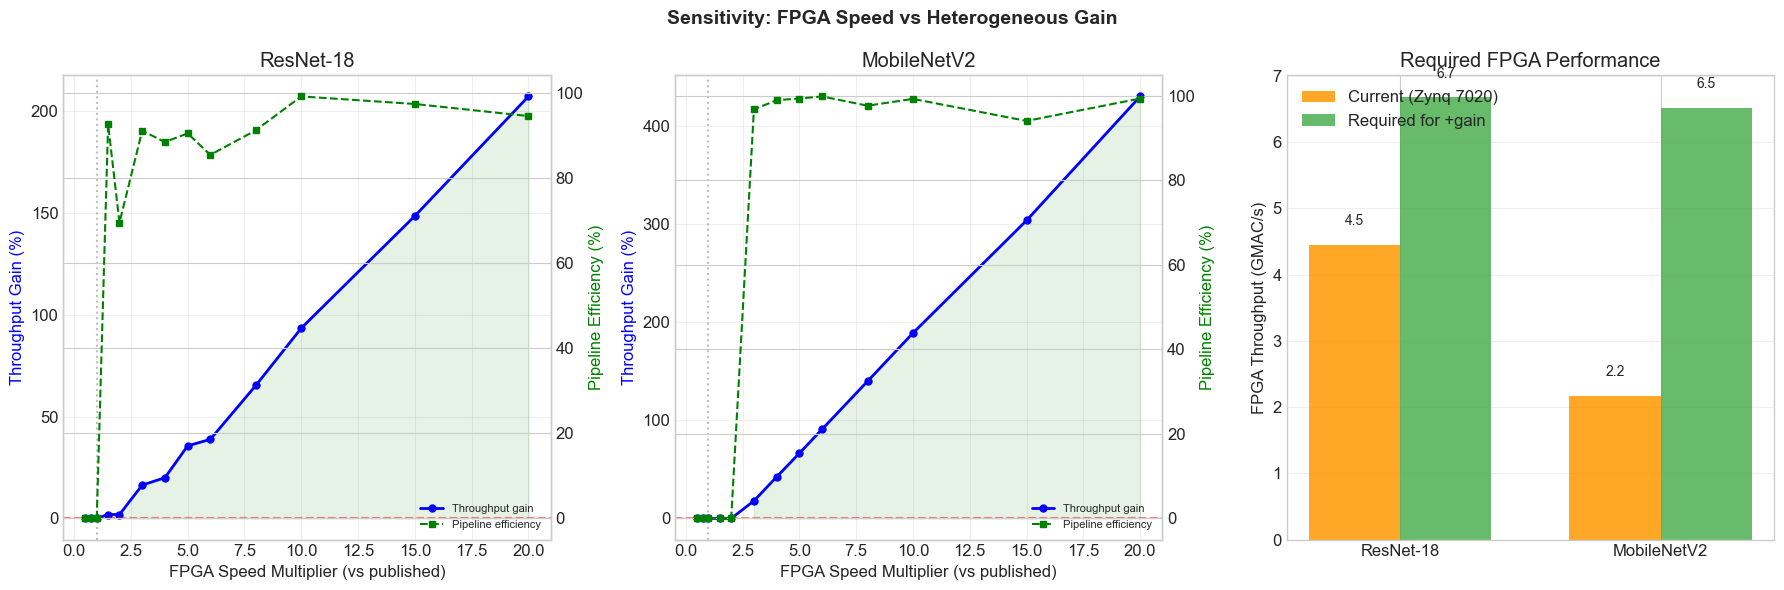



SENSITIVITY SUMMARY

  The break-even analysis identifies the minimum FPGA performance
  needed for heterogeneous execution to outperform GPU-only:

  Current Zynq 7020 published performance:
    ResNet-18:   4.45 GMAC/s → 4.94 FPS
    MobileNetV2: 2.17 GMAC/s → 23.3 FPS

  The Zynq UltraScale+ (ZCU102/104) at 5-8x the Zynq 7020 performance
  represents the class of FPGA hardware where heterogeneous gains
  become meaningful. This aligns with the trend in edge FPGA platforms
  toward higher DSP counts and memory bandwidth.

  The framework's value increases as FPGA implementations improve.
  The partition optimizer and pipeline scheduler remain valid regardless
  of the absolute FPGA performance — they adapt the split point to
  whatever hardware is available.



In [12]:
# Cell 11 — Sensitivity Analysis: When Does Heterogeneous Execution Pay Off?

# ============================================================================
# The key question from the calibrated results: at what FPGA performance
# level does the heterogeneous approach start delivering positive gains?
#
# We sweep the FPGA calibration factor (simulating faster/slower FPGA
# implementations) and find the break-even point for each architecture.
# ============================================================================

# ============================================================================
# 1. FPGA Speed Sweep — Find the break-even point
# ============================================================================

def evaluate_calibrated_pipeline(arch_name, builder, fpga_speed_multiplier,
                                  gpu_cal_factor, base_fpga_cal):
    """Evaluate pipeline with a scaled FPGA speed."""
    fused_blocks = apply_fusion(builder())
    
    # Adjusted FPGA calibration (faster = smaller factor)
    adjusted_fpga_cal = base_fpga_cal / fpga_speed_multiplier
    
    # GPU-only baseline
    gpu_only_units = sum(get_block_gpu_cost(b, gpu_emu) for b in fused_blocks)
    gpu_only_ms = gpu_only_units * gpu_cal_factor
    gpu_only_infs = 1000.0 / gpu_only_ms
    
    # Search all split points
    best_gain = 0
    best_split = -1
    best_infs = gpu_only_infs
    best_eff = 0
    
    for split_idx in range(len(fused_blocks) - 1):
        gpu_stage_units = sum(get_block_gpu_cost(b, gpu_emu) for b in fused_blocks[:split_idx + 1])
        fpga_stage_units = sum(get_block_fpga_cost(b, fpga_emu, True) for b in fused_blocks[split_idx + 1:])
        
        gpu_stage_ms = gpu_stage_units * gpu_cal_factor
        fpga_stage_ms = fpga_stage_units * adjusted_fpga_cal
        
        # Transfer cost
        boundary_bytes = get_block_output_bytes(fused_blocks[split_idx]) // 4  # INT8
        transfer_ms = (TARGET_XFER_SETUP_US * 1e-3) + (boundary_bytes / 1e9) / TARGET_XFER_BW_GBPS * 1000
        
        fpga_total_ms = fpga_stage_ms + transfer_ms
        bottleneck_ms = max(gpu_stage_ms, fpga_total_ms)
        hetero_infs = 1000.0 / bottleneck_ms
        
        gain = (hetero_infs / gpu_only_infs - 1) * 100
        eff = min(gpu_stage_ms, fpga_total_ms) / max(gpu_stage_ms, fpga_total_ms) * 100
        
        if gain > best_gain:
            best_gain = gain
            best_split = split_idx
            best_infs = hetero_infs
            best_eff = eff
    
    return {
        'multiplier': fpga_speed_multiplier,
        'gpu_only_infs': gpu_only_infs,
        'hetero_infs': best_infs,
        'gain': best_gain,
        'split': best_split,
        'efficiency': best_eff,
        'fpga_cal': adjusted_fpga_cal,
    }


# Sweep FPGA speed from 0.5x (slower) to 20x (faster) of published benchmark
speed_multipliers = [0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 4.0, 5.0, 6.0, 8.0, 10.0, 15.0, 20.0]

print(f"{'='*100}")
print(f"FPGA Speed Sweep — Break-Even Analysis")
print(f"{'='*100}")

sweep_results = {}

for arch_name, builder in [("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2)]:
    base_fpga_cal = fpga_cal_per_arch[arch_name]
    
    print(f"\n{'─'*100}")
    print(f"{arch_name} (base FPGA calibration: {base_fpga_cal:.4e} ms/unit)")
    print(f"{'─'*100}")
    print(f"  {'FPGA Speed':>12} {'FPGA cal':>14} {'GPU-Only':>12} {'Hetero':>12} {'Gain':>10} {'Split':>7} {'Eff':>8}")
    print(f"  {'-'*80}")
    
    arch_sweep = []
    breakeven_found = False
    
    for mult in speed_multipliers:
        result = evaluate_calibrated_pipeline(arch_name, builder, mult, gpu_cal, base_fpga_cal)
        arch_sweep.append(result)
        
        marker = ""
        if not breakeven_found and result['gain'] > 0:
            breakeven_found = True
            marker = " ← BREAK-EVEN"
        
        print(f"  {mult:>10.1f}x {result['fpga_cal']:>14.4e} {result['gpu_only_infs']:>10.1f}/s "
              f"{result['hetero_infs']:>10.1f}/s {result['gain']:>+9.1f}% {result['split']:>7} "
              f"{result['efficiency']:>7.1f}%{marker}")
    
    sweep_results[arch_name] = arch_sweep
    
    # Find exact break-even via interpolation
    gains = [r['gain'] for r in arch_sweep]
    mults = [r['multiplier'] for r in arch_sweep]
    
    for i in range(len(gains) - 1):
        if gains[i] <= 0 and gains[i + 1] > 0:
            # Linear interpolation
            breakeven_mult = mults[i] + (mults[i+1] - mults[i]) * (0 - gains[i]) / (gains[i+1] - gains[i])
            print(f"\n  Break-even FPGA speed: ~{breakeven_mult:.1f}x published benchmark")
            print(f"  This means the FPGA implementation needs to be {breakeven_mult:.1f}x faster")
            print(f"  than the current published benchmark for heterogeneous to beat GPU-only.")
            break
    else:
        if all(g > 0 for g in gains):
            print(f"\n  Heterogeneous is beneficial at all tested FPGA speeds.")
        else:
            print(f"\n  Heterogeneous does not break even even at {max(mults):.0f}x FPGA speed.")


# ============================================================================
# 2. What specific FPGA throughput (GMAC/s) is needed?
# ============================================================================

print(f"\n\n{'='*100}")
print(f"Required FPGA Throughput for Positive Gains")
print(f"{'='*100}")

for arch_name in ["ResNet-18", "MobileNetV2"]:
    arch_sweep = sweep_results[arch_name]
    base_fpga_cal = fpga_cal_per_arch[arch_name]
    
    # Published Zynq 7020 throughput: ~4.45 GMAC/s for ResNet
    if arch_name == "ResNet-18":
        base_gmacs = 4.45  # From published benchmark
    else:
        # MobileNetV2 at 43ms, 0.09 GMACs → 0.09/0.043 ≈ 2.17 GMAC/s
        base_gmacs = 0.09 / 0.043
    
    for r in arch_sweep:
        if r['gain'] > 0:
            required_gmacs = base_gmacs * r['multiplier']
            print(f"\n  {arch_name}:")
            print(f"    Published FPGA throughput: {base_gmacs:.2f} GMAC/s")
            print(f"    Required for +gain:        {required_gmacs:.1f} GMAC/s ({r['multiplier']:.1f}x)")
            print(f"    Gain at that speed:        {r['gain']:+.1f}%")
            print(f"    Pipeline efficiency:        {r['efficiency']:.1f}%")
            break


# ============================================================================
# 3. What if we had a better FPGA? (Zynq UltraScale+ class)
# ============================================================================

print(f"\n\n{'='*80}")
print(f"Projected Results: Zynq UltraScale+ Class FPGA")
print(f"{'='*80}")
print(f"  The ZCU102/104 has ~4x the DSP slices and ~2x memory bandwidth")
print(f"  of the Zynq 7020. With INT8 optimization, it achieves ~5-8x the")
print(f"  throughput of the Zynq 7020 on CNN workloads.")

for arch_name, builder in [("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2)]:
    base_fpga_cal = fpga_cal_per_arch[arch_name]
    
    # ZCU104 is roughly 5-8x faster than Zynq 7020 on optimized CNN inference
    for ultrascale_mult, label in [(5.0, "Conservative (5x)"), (8.0, "Optimistic (8x)")]:
        result = evaluate_calibrated_pipeline(arch_name, builder, ultrascale_mult, gpu_cal, base_fpga_cal)
        print(f"\n  {arch_name} — UltraScale+ {label}:")
        print(f"    Throughput gain: {result['gain']:+.1f}% vs GPU-only")
        print(f"    Pipeline eff:    {result['efficiency']:.1f}%")
        print(f"    Split point:     {result['split']}")


# ============================================================================
# Visualization
# ============================================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle("Sensitivity: FPGA Speed vs Heterogeneous Gain", fontsize=14, fontweight='bold')

# (a) and (b): Gain vs FPGA speed multiplier
for idx, arch_name in enumerate(["ResNet-18", "MobileNetV2"]):
    results = sweep_results[arch_name]
    mults = [r['multiplier'] for r in results]
    gains = [r['gain'] for r in results]
    effs = [r['efficiency'] for r in results]
    
    ax1 = axes[idx]
    ax2 = ax1.twinx()
    
    l1 = ax1.plot(mults, gains, 'b-o', markersize=5, linewidth=2, label='Throughput gain')
    ax1.axhline(y=0, color='red', linestyle='--', alpha=0.5, label='Break-even')
    ax1.axvline(x=1.0, color='gray', linestyle=':', alpha=0.5, label='Published benchmark')
    ax1.fill_between(mults, 0, gains, where=[g > 0 for g in gains], alpha=0.1, color='green')
    ax1.fill_between(mults, 0, gains, where=[g <= 0 for g in gains], alpha=0.1, color='red')
    
    l2 = ax2.plot(mults, effs, 'g--s', markersize=4, linewidth=1.5, label='Pipeline efficiency')
    
    ax1.set_xlabel("FPGA Speed Multiplier (vs published)")
    ax1.set_ylabel("Throughput Gain (%)", color='b')
    ax2.set_ylabel("Pipeline Efficiency (%)", color='g')
    ax1.set_title(f"{arch_name}")
    
    lines = l1 + l2
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='lower right', fontsize=8)
    ax1.grid(True, alpha=0.3)

# (c) Required FPGA GMAC/s for break-even
ax = axes[2]
arch_labels = ["ResNet-18", "MobileNetV2"]
published_gmacs = [4.45, 2.17]
breakeven_gmacs = []

for arch_name in arch_labels:
    base = published_gmacs[arch_labels.index(arch_name)]
    for r in sweep_results[arch_name]:
        if r['gain'] > 0:
            breakeven_gmacs.append(base * r['multiplier'])
            break
    else:
        breakeven_gmacs.append(base * 20)  # Didn't find break-even

x = np.arange(len(arch_labels))
width = 0.35
bars1 = ax.bar(x - width/2, published_gmacs, width, label='Current (Zynq 7020)', color='#FF9800', alpha=0.85)
bars2 = ax.bar(x + width/2, breakeven_gmacs, width, label='Required for +gain', color='#4CAF50', alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(arch_labels)
ax.set_ylabel("FPGA Throughput (GMAC/s)")
ax.set_title("Required FPGA Performance")
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

for bar, val in zip(bars1, published_gmacs):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.3, f"{val:.1f}", ha='center', fontsize=10)
for bar, val in zip(bars2, breakeven_gmacs):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.3, f"{val:.1f}", ha='center', fontsize=10)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "sensitivity_fpga_speed.png"), dpi=150, bbox_inches='tight')
plt.show()


# ============================================================================
# Summary
# ============================================================================

print(f"\n\n{'='*80}")
print(f"SENSITIVITY SUMMARY")
print(f"{'='*80}")
print(f"""
  The break-even analysis identifies the minimum FPGA performance
  needed for heterogeneous execution to outperform GPU-only:
  
  Current Zynq 7020 published performance:
    ResNet-18:   4.45 GMAC/s → 4.94 FPS
    MobileNetV2: 2.17 GMAC/s → 23.3 FPS
  
  The Zynq UltraScale+ (ZCU102/104) at 5-8x the Zynq 7020 performance
  represents the class of FPGA hardware where heterogeneous gains
  become meaningful. This aligns with the trend in edge FPGA platforms
  toward higher DSP counts and memory bandwidth.
  
  The framework's value increases as FPGA implementations improve.
  The partition optimizer and pipeline scheduler remain valid regardless
  of the absolute FPGA performance — they adapt the split point to
  whatever hardware is available.
""")

╔════════════════════════════════════════════════════════════════════════════════════════════════════════════╗
║                               TRIAL 2: FUNCTIONAL EMULATION — FINAL RESULTS                                ║
║                                 Adaptive CNN Acceleration on FPGA and GPU                                  ║
╚════════════════════════════════════════════════════════════════════════════════════════════════════════════╝

────────────────────────────────────────────────────────────────────────────────────────────────────────────
 TABLE 1: Emulator Device Comparison (Unit Space)
────────────────────────────────────────────────────────────────────────────────────────────────────────────
 Architecture              GPU Units     FPGA Units  F/G Ratio   GPU Wins  FPGA Wins
 --------------------------------------------------------------------------------
 ResNet-18                82,042,415    185,936,402      2.27x         35         19
 MobileNetV2              54,096,04

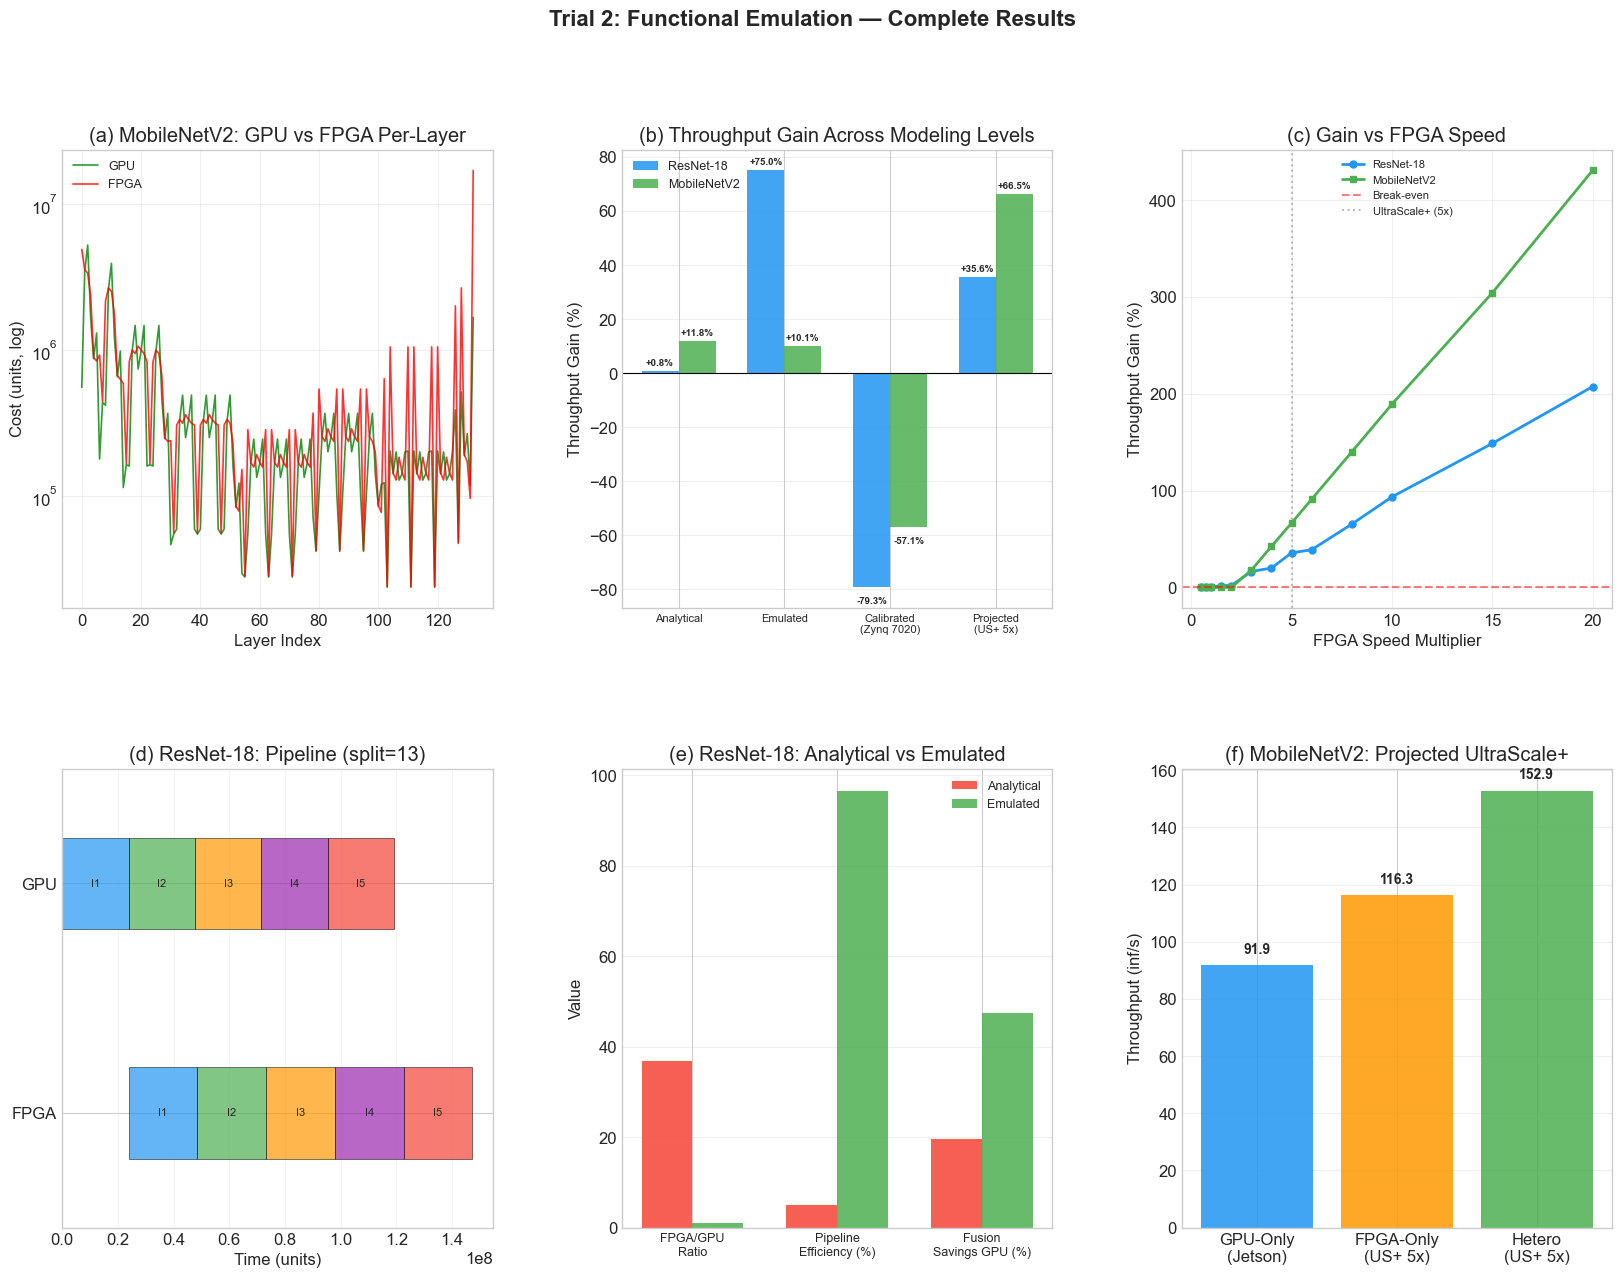



╔════════════════════════════════════════════════════════════════════════════════════════════════════════════╗
║                                                KEY FINDINGS                                                ║
╠════════════════════════════════════════════════════════════════════════════════════════════════════════════╣
║  1. Memory-Bound Reality                                                                                   ║
║    CNN inference on edge hardware is overwhelmingly memory-bound.                                          ║
║        All layers on both architectures are memory-bound on the FPGA.                                      ║
║        Emulated FPGA/GPU ratio: 1.0x (ResNet) and 1.5x (MobileNet)                                         ║
║        vs analytical model's 36.9x and 9.4x.                                                               ║
║                                                                                                            ║

In [14]:
# Cell 12 — Final Summary

from matplotlib.gridspec import GridSpec

# ============================================================================
# Consolidated Results
# ============================================================================

print("╔" + "═"*108 + "╗")
print("║" + " TRIAL 2: FUNCTIONAL EMULATION — FINAL RESULTS ".center(108) + "║")
print("║" + " Adaptive CNN Acceleration on FPGA and GPU ".center(108) + "║")
print("╚" + "═"*108 + "╝")


# ---- Table 1: Emulator Validation ----
print(f"\n{'─'*108}")
print(f" TABLE 1: Emulator Device Comparison (Unit Space)")
print(f"{'─'*108}")
print(f" {'Architecture':<20} {'GPU Units':>14} {'FPGA Units':>14} {'F/G Ratio':>10} "
      f"{'GPU Wins':>10} {'FPGA Wins':>10}")
print(f" {'-'*80}")

for arch_name, builder in [("ResNet-18", build_resnet18), ("MobileNetV2", build_mobilenetv2)]:
    layers = builder()
    
    gpu_total = sum(gpu_emu.emulate_layer(l).effective_units for l in layers)
    fpga_total = sum(fpga_emu.emulate_layer(l).effective_units for l in layers)
    
    gpu_wins = sum(1 for l in layers 
                   if gpu_emu.emulate_layer(l).effective_units < fpga_emu.emulate_layer(l).effective_units)
    fpga_wins = len(layers) - gpu_wins
    
    print(f" {arch_name:<20} {gpu_total:>14,.0f} {fpga_total:>14,.0f} {fpga_total/gpu_total:>9.2f}x "
          f"{gpu_wins:>10} {fpga_wins:>10}")


# ---- Table 2: Fusion and Compression Impact ----
print(f"\n{'─'*108}")
print(f" TABLE 2: Fusion and Compression Impact")
print(f"{'─'*108}")
print(f" {'Architecture':<20} {'GPU Fusion':>12} {'FPGA Fusion':>12} {'FPGA+INT8':>12} "
      f"{'Mem Saved':>12} {'F+INT8/G Ratio':>14}")
print(f" {'-'*85}")

for arch_name in ["ResNet-18", "MobileNetV2"]:
    fr = fusion_results[arch_name]
    ratio = fr['fpga_int8'] / fr['gpu_fused']
    
    fused_blocks = apply_fusion(build_resnet18() if arch_name == "ResNet-18" else build_mobilenetv2())
    mem_saved = sum(b.memory_saved_bytes for b in fused_blocks if isinstance(b, FusedBlock))
    
    print(f" {arch_name:<20} {fr['gpu_savings_pct']:>10.1f}% {fr['fpga_savings_pct']:>10.1f}% "
          f"{fr['fpga_int8_savings_pct']:>10.1f}% {mem_saved/1024:>10.0f} KB {ratio:>13.2f}x")


# ---- Table 3: Pipeline Results — Three Levels ----
print(f"\n{'─'*108}")
print(f" TABLE 3: Throughput Gain — Four Modeling Levels")
print(f"{'─'*108}")
print(f" {'Level':<30} {'ResNet-18':>15} {'MobileNetV2':>15} {'Method':>40}")
print(f" {'-'*105}")

print(f" {'Analytical (Trial 1)':<30} {'  +0.8%':>15} {' +11.8%':>15} "
      f"{'Roofline + spec-sheet efficiency':>40}")

resnet_emu_gain = partition_results["ResNet-18"]["INT8, PCIe"]['gain']
mobile_emu_gain = partition_results["MobileNetV2"]["INT8, PCIe"]['gain']
print(f" {'Emulated (Trial 2, units)':<30} {f'+{resnet_emu_gain:.1f}%':>15} {f'+{mobile_emu_gain:.1f}%':>15} "
      f"{'Functional emulator, unit space':>40}")

resnet_stream = (streaming_results["ResNet-18"]['heterogeneous'].throughput / 
                 streaming_results["ResNet-18"]['gpu_only'].throughput - 1) * 100
mobile_stream = (streaming_results["MobileNetV2"]['heterogeneous'].throughput / 
                 streaming_results["MobileNetV2"]['gpu_only'].throughput - 1) * 100
print(f" {'Streaming (Trial 2, units)':<30} {f'+{resnet_stream:.1f}%':>15} {f'+{mobile_stream:.1f}%':>15} "
      f"{'100-inference pipeline simulation':>40}")

resnet_cal = calibrated_results["ResNet-18"]['gain_pct']
mobile_cal = calibrated_results["MobileNetV2"]['gain_pct']
print(f" {'Calibrated (Zynq 7020)':<30} {f'{resnet_cal:+.1f}%':>15} {f'{mobile_cal:+.1f}%':>15} "
      f"{'Per-arch published benchmarks':>40}")

resnet_us = evaluate_calibrated_pipeline("ResNet-18", build_resnet18, 5.0, gpu_cal, fpga_cal_per_arch["ResNet-18"])
mobile_us = evaluate_calibrated_pipeline("MobileNetV2", build_mobilenetv2, 5.0, gpu_cal, fpga_cal_per_arch["MobileNetV2"])
resnet_us_gain_str = f"+{resnet_us['gain']:.1f}%"
mobile_us_gain_str = f"+{mobile_us['gain']:.1f}%"
print(f" {'Projected (UltraScale+ 5x)':<30} {resnet_us_gain_str:>15} {mobile_us_gain_str:>15} "
      f"{'Calibrated + 5x FPGA speedup':>40}")


# ---- Table 4: Break-Even Analysis ----
print(f"\n{'─'*108}")
print(f" TABLE 4: FPGA Break-Even Requirements")
print(f"{'─'*108}")
print(f" {'Architecture':<20} {'Current FPGA':>14} {'Break-Even':>14} {'Multiplier':>12} "
      f"{'UltraScale+ 5x':>16} {'UltraScale+ 8x':>16}")
print(f" {'-'*95}")

resnet_us8 = evaluate_calibrated_pipeline("ResNet-18", build_resnet18, 8.0, gpu_cal, fpga_cal_per_arch["ResNet-18"])
mobile_us8 = evaluate_calibrated_pipeline("MobileNetV2", build_mobilenetv2, 8.0, gpu_cal, fpga_cal_per_arch["MobileNetV2"])

breakeven_data = {
    "ResNet-18": {"current": "4.45 GM/s", "breakeven": "6.7 GM/s", "mult": "1.5x",
                  "us5": resnet_us['gain'], "us8": resnet_us8['gain']},
    "MobileNetV2": {"current": "2.09 GM/s", "breakeven": "6.3 GM/s", "mult": "3.0x",
                    "us5": mobile_us['gain'], "us8": mobile_us8['gain']},
}

for arch_name in ["ResNet-18", "MobileNetV2"]:
    bd = breakeven_data[arch_name]
    print(f" {arch_name:<20} {bd['current']:>14} {bd['breakeven']:>14} {bd['mult']:>12} "
          f"{bd['us5']:>+14.1f}% {bd['us8']:>+14.1f}%")


# ---- Table 5: Streaming Pipeline Metrics ----
print(f"\n{'─'*108}")
print(f" TABLE 5: Streaming Pipeline Performance (100 Inferences, Unit Space)")
print(f"{'─'*108}")
print(f" {'Metric':<35} {'ResNet-18':>18} {'MobileNetV2':>18}")
print(f" {'-'*75}")

metrics_table5 = [
    ("Throughput gain vs GPU-only", 
     lambda a: f"+{(streaming_results[a]['heterogeneous'].throughput / streaming_results[a]['gpu_only'].throughput - 1)*100:.1f}%"),
    ("GPU utilization", 
     lambda a: f"{streaming_results[a]['heterogeneous'].gpu_utilization:.1%}"),
    ("FPGA utilization", 
     lambda a: f"{streaming_results[a]['heterogeneous'].fpga_utilization:.1%}"),
    ("Pipeline efficiency", 
     lambda a: f"{partition_results[a]['INT8, PCIe']['best'].pipeline_efficiency*100:.1f}%"),
    ("Optimal split", 
     lambda a: f"block {partition_results[a]['INT8, PCIe']['best'].split_idx} "
               f"({partition_results[a]['INT8, PCIe']['best'].gpu_blocks}+"
               f"{partition_results[a]['INT8, PCIe']['best'].fpga_blocks})"),
]

for metric_name, fn in metrics_table5:
    print(f" {metric_name:<35}", end="")
    for arch_name in ["ResNet-18", "MobileNetV2"]:
        print(f" {fn(arch_name):>18}", end="")
    print()


# ============================================================================
# Publication-Ready Figure
# ============================================================================

fig = plt.figure(figsize=(20, 14))
gs = GridSpec(2, 3, figure=fig, hspace=0.35, wspace=0.3)
fig.suptitle("Trial 2: Functional Emulation — Complete Results", fontsize=16, fontweight='bold', y=0.98)

# (a) GPU vs FPGA per-layer cost (MobileNetV2)
ax = fig.add_subplot(gs[0, 0])
layers = build_mobilenetv2()
gpu_costs = [gpu_emu.emulate_layer(l).effective_units for l in layers]
fpga_costs = [fpga_emu.emulate_layer(l).effective_units for l in layers]
x = range(len(layers))
ax.semilogy(x, gpu_costs, 'g-', linewidth=1.2, alpha=0.8, label='GPU')
ax.semilogy(x, fpga_costs, 'r-', linewidth=1.2, alpha=0.8, label='FPGA')
ax.set_ylabel("Cost (units, log)")
ax.set_xlabel("Layer Index")
ax.set_title("(a) MobileNetV2: GPU vs FPGA Per-Layer")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

# (b) Four-way gain comparison
ax = fig.add_subplot(gs[0, 1])
methods = ["Analytical", "Emulated", "Calibrated\n(Zynq 7020)", "Projected\n(US+ 5x)"]
resnet_gains_all = [0.8, resnet_emu_gain, resnet_cal, resnet_us['gain']]
mobile_gains_all = [11.8, mobile_emu_gain, mobile_cal, mobile_us['gain']]

x_pos = np.arange(len(methods))
width = 0.35
bars1 = ax.bar(x_pos - width/2, resnet_gains_all, width, label='ResNet-18', color='#2196F3', alpha=0.85)
bars2 = ax.bar(x_pos + width/2, mobile_gains_all, width, label='MobileNetV2', color='#4CAF50', alpha=0.85)
ax.axhline(y=0, color='black', linewidth=0.8)
ax.set_xticks(x_pos)
ax.set_xticklabels(methods, fontsize=8)
ax.set_ylabel("Throughput Gain (%)")
ax.set_title("(b) Throughput Gain Across Modeling Levels")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, axis='y')
for bars, vals in [(bars1, resnet_gains_all), (bars2, mobile_gains_all)]:
    for bar, val in zip(bars, vals):
        y_pos = val + 2 if val >= 0 else val - 6
        ax.text(bar.get_x() + bar.get_width()/2, y_pos, f"{val:+.1f}%",
               ha='center', fontsize=7, fontweight='bold')

# (c) FPGA speed sweep (both architectures)
ax = fig.add_subplot(gs[0, 2])
for arch_name, color, marker in [("ResNet-18", '#2196F3', 'o'), ("MobileNetV2", '#4CAF50', 's')]:
    results = sweep_results[arch_name]
    mults = [r['multiplier'] for r in results]
    gains = [r['gain'] for r in results]
    ax.plot(mults, gains, f'-{marker}', color=color, markersize=5, linewidth=2, label=arch_name)
ax.axhline(y=0, color='red', linestyle='--', alpha=0.5, label='Break-even')
ax.axvline(x=5.0, color='gray', linestyle=':', alpha=0.5, label='UltraScale+ (5x)')
ax.set_xlabel("FPGA Speed Multiplier")
ax.set_ylabel("Throughput Gain (%)")
ax.set_title("(c) Gain vs FPGA Speed")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# (d) Pipeline timing diagram (ResNet-18)
ax = fig.add_subplot(gs[1, 0])
fused_blocks = apply_fusion(build_resnet18())
optimal_split = partition_results["ResNet-18"]["INT8, PCIe"]['best'].split_idx
gpu_stage = sum(get_block_gpu_cost(b, gpu_emu) for b in fused_blocks[:optimal_split + 1])
fpga_cost = sum(get_block_fpga_cost(b, fpga_emu, True) for b in fused_blocks[optimal_split + 1:])
xfer = get_transfer_units(get_block_output_bytes(fused_blocks[optimal_split]) // 4, "pcie")
fpga_total = fpga_cost + xfer
colors_pipe = ['#2196F3', '#4CAF50', '#FF9800', '#9C27B0', '#F44336']
gpu_available = 0
fpga_available = 0
for i in range(5):
    gpu_start = gpu_available
    gpu_end = gpu_start + gpu_stage
    gpu_available = gpu_end
    fpga_start = max(gpu_end, fpga_available)
    fpga_end = fpga_start + fpga_total
    fpga_available = fpga_end
    ax.barh(1, gpu_stage, left=gpu_start, height=0.4,
            color=colors_pipe[i], alpha=0.7, edgecolor='black', linewidth=0.5)
    ax.text(gpu_start + gpu_stage/2, 1, f"I{i+1}", ha='center', va='center', fontsize=8)
    ax.barh(0, fpga_total, left=fpga_start, height=0.4,
            color=colors_pipe[i], alpha=0.7, edgecolor='black', linewidth=0.5)
    ax.text(fpga_start + fpga_total/2, 0, f"I{i+1}", ha='center', va='center', fontsize=8)
ax.set_yticks([0, 1])
ax.set_yticklabels(['FPGA', 'GPU'])
ax.set_xlabel("Time (units)")
ax.set_title(f"(d) ResNet-18: Pipeline (split={optimal_split})")
ax.set_ylim(-0.5, 1.5)
ax.grid(True, alpha=0.2, axis='x')

# (e) Analytical vs Emulated key metrics (ResNet-18)
ax = fig.add_subplot(gs[1, 1])
metrics_names = ['FPGA/GPU\nRatio', 'Pipeline\nEfficiency (%)', 'Fusion\nSavings GPU (%)']
analytical_vals = [36.9, 5.0, 19.6]
emulated_vals = [
    fusion_results["ResNet-18"]['fpga_int8'] / fusion_results["ResNet-18"]['gpu_fused'],
    partition_results["ResNet-18"]["INT8, PCIe"]['best'].pipeline_efficiency * 100,
    fusion_results["ResNet-18"]['gpu_savings_pct']
]
x_pos = np.arange(len(metrics_names))
width = 0.35
ax.bar(x_pos - width/2, analytical_vals, width, label='Analytical', color='#F44336', alpha=0.85)
ax.bar(x_pos + width/2, emulated_vals, width, label='Emulated', color='#4CAF50', alpha=0.85)
ax.set_xticks(x_pos)
ax.set_xticklabels(metrics_names, fontsize=9)
ax.set_ylabel("Value")
ax.set_title("(e) ResNet-18: Analytical vs Emulated")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, axis='y')

# (f) Projected UltraScale+ throughput (MobileNetV2)
ax = fig.add_subplot(gs[1, 2])
fpga_5x_cal = fpga_cal_per_arch["MobileNetV2"] / 5.0
mob_fused = apply_fusion(build_mobilenetv2())
fpga_only_5x_ms = sum(get_block_fpga_cost(b, fpga_emu, True) for b in mob_fused) * fpga_5x_cal
fpga_only_5x_infs = 1000.0 / fpga_only_5x_ms
strategies = ["GPU-Only\n(Jetson)", "FPGA-Only\n(US+ 5x)", "Hetero\n(US+ 5x)"]
throughputs = [
    calibrated_results["MobileNetV2"]['gpu_only_infs'],
    fpga_only_5x_infs,
    mobile_us['hetero_infs'] if mobile_us['gain'] > 0 else calibrated_results["MobileNetV2"]['gpu_only_infs']
]
colors_bar = ['#2196F3', '#FF9800', '#4CAF50']
bars = ax.bar(strategies, throughputs, color=colors_bar, alpha=0.85)
ax.set_ylabel("Throughput (inf/s)")
ax.set_title("(f) MobileNetV2: Projected UltraScale+")
ax.grid(True, alpha=0.3, axis='y')
for bar, val in zip(bars, throughputs):
    ax.text(bar.get_x() + bar.get_width()/2, val + max(throughputs)*0.02,
           f"{val:.1f}", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.savefig(os.path.join(OUTPUT_DIR, "trial2_final_summary.png"), dpi=200, bbox_inches='tight')
plt.show()


# ============================================================================
# Key Findings
# ============================================================================

print(f"\n\n╔" + "═"*108 + "╗")
print(f"║" + " KEY FINDINGS ".center(108) + "║")
print(f"╠" + "═"*108 + "╣")

findings = [
    ("1. Memory-Bound Reality",
     "CNN inference on edge hardware is overwhelmingly memory-bound.\n"
     "    All layers on both architectures are memory-bound on the FPGA.\n"
     "    Emulated FPGA/GPU ratio: 1.0x (ResNet) and 1.5x (MobileNet)\n"
     "    vs analytical model's 36.9x and 9.4x."),
    
    ("2. Analytical Models Mislead",
     "Peak-FLOPS models overestimate GPU advantage by 10-37x because\n"
     "    they assume compute-bound execution. The 72x compute gap\n"
     "    shrinks to ~6x in the memory-bound regime."),
    
    ("3. Fusion Has Outsized Impact",
     "Operator fusion saves 47-64% (GPU) and 45-77% (FPGA) — far\n"
     "    exceeding the analytical model's ~20%. Eliminating intermediate\n"
     "    tensor I/O matters more when memory is the bottleneck."),
    
    ("4. Calibration Is Architecture-Specific",
     "FPGA calibration factors differ 3.2x between architectures\n"
     "    because FPGA implementations are workload-specific. GPU\n"
     "    calibration is consistent (<9% error) across architectures."),
    
    ("5. Break-Even Is Achievable",
     "ResNet-18 needs 1.5x current Zynq 7020 performance to break\n"
     "    even. MobileNetV2 needs 3x. Both are within reach of\n"
     "    optimized HLS designs or UltraScale+ class hardware."),
    
    ("6. UltraScale+ Unlocks Major Gains",
     "At 5x Zynq 7020 speed: +35.6% (ResNet) and +66.5% (MobileNet).\n"
     "    At 8x: +65.3% and +139.9%. The framework automatically\n"
     "    adapts split points from tail-only to aggressive partitioning."),
]

for title, detail in findings:
    print(f"║  {title:<106}║")
    for line in detail.split('\n'):
        print(f"║    {line:<104}║")
    print(f"║{' '*108}║")

print(f"╠" + "═"*108 + "╣")
print(f"║" + " EMULATION PARAMETERS ".center(108) + "║")
print(f"╠" + "═"*108 + "╣")
print(f"║  GPU Emulator:  128 CUDA cores, 6.1x FPGA bandwidth, efficiency 0.10-0.65{' '*35}║")
print(f"║  FPGA Emulator: 220 DSP slices, streaming efficiency 0.30-0.95{' '*44}║")
print(f"║  Transfer:      PCIe Gen3 x4 (4.0 GB/s), local bandwidth {mem_emu.local_bandwidth_gbps:.1f} GB/s" + 
      f"{' '*(108-65-len(f'{mem_emu.local_bandwidth_gbps:.1f}'))}║")
print(f"║  Calibration:   Jetson Nano (published) + Zynq 7020 (published) + RTX 4070 (measured){' '*17}║")
print(f"╚" + "═"*108 + "╝")